# Analysis of uoe5 pipeline run
Reran antibody panel 1 with new updates within the pipeline, resutling in run uoe5.

Major pipeline changes include more quality control mesasures focused on organelle channels (Mitochondria, endosome, and mitochondria) - I added the contrast check that we run for the nuclues channel to script 3 to check each channel before segmentation is preformed. The organelle channels are generally more dim than the nuclues channel, so the threshold for QC is quite a bit lower than that of the nucleus channel.

The goals here are to preform the prior PCA analyses (plus additional analysis on the genotype level, manual focused analsysis, and structure level analysis) and assess whether we reduced the number of poor quality images that make it to this analysis stage. 

In [1]:
import pathlib as Path
import pandas as pd
import os

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
import io
import matplotlib.pyplot as plt

# pip install python-pptx  (if not already installed)
from pptx import Presentation
from pptx.util import Inches, Pt

# ===========================================================================
# Figure capture: wrap plt.show so EVERY plot is grabbed, no per-call edits.
# ===========================================================================
_CAPTURED = []            # list of (title, png_bytes)
_CAPTURE_ON = True        # flip to False to pause capture for a cell


def _best_title(fig):
    """Pull a slide title from the figure: suptitle first, else first axes title."""
    # suptitle (used by scree / variant_pca)
    if getattr(fig, "_suptitle", None) is not None and fig._suptitle.get_text():
        return fig._suptitle.get_text()
    for ax in fig.axes:
        if ax.get_title():
            return ax.get_title()
    return None


_orig_show = plt.show

def _capturing_show(*args, **kwargs):
    if _CAPTURE_ON:
        fig = plt.gcf()
        # skip empty figures (no axes / nothing drawn)
        if fig.axes:
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
            buf.seek(0)
            _CAPTURED.append((_best_title(fig), buf.getvalue()))
    return _orig_show(*args, **kwargs)

plt.show = _capturing_show
print("Figure capture ON — every plt.show() will be collected.")


# ===========================================================================
# Build the deck (call once at the very end of the notebook).
# ===========================================================================
def build_pptx(path, captured=None, widescreen=True):
    captured = _CAPTURED if captured is None else captured
    prs = Presentation()
    if widescreen:
        prs.slide_width = Inches(13.333)
        prs.slide_height = Inches(7.5)
    blank = prs.slide_layouts[6]   # fully blank

    sw = prs.slide_width
    sh = prs.slide_height
    for title, png in captured:
        slide = prs.slides.add_slide(blank)
        top = Inches(0.1)
        if title:
            tb = slide.shapes.add_textbox(Inches(0.3), Inches(0.1),
                                          sw - Inches(0.6), Inches(0.6))
            tf = tb.text_frame
            tf.text = title
            tf.paragraphs[0].font.size = Pt(18)
            top = Inches(0.8)

        pic = slide.shapes.add_picture(io.BytesIO(png), Inches(0), top)
        # scale to fit the slide while preserving aspect ratio
        avail_w = sw
        avail_h = sh - top - Inches(0.1)
        scale = min(avail_w / pic.width, avail_h / pic.height)
        pic.width = int(pic.width * scale)
        pic.height = int(pic.height * scale)
        pic.left = int((sw - pic.width) / 2)   # center horizontally

    prs.save(path)
    print(f"wrote {len(captured)} slides -> {path}")


def restore_show():
    """Undo the monkeypatch (optional, e.g. before re-running interactively)."""
    plt.show = _orig_show
    print("Figure capture OFF — plt.show restored.")

Figure capture ON — every plt.show() will be collected.


## Load feature data
Load in feature data merged with metadata

In [3]:
uoe5_organelle_output_fn = "/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_organelle_output.parquet"
df = pd.read_parquet(uoe5_organelle_output_fn)

df["Batch"] = df["Batch"].astype("Int64").astype(str)  # Int64 first handles any NaN

df = df[df["Structure"] == "Mitochondria"]

print(df.head())
print(df.columns.tolist())

                DAPI_filename  Nucleus_ID  \
2   r01c01f01p01-ch01t01.tiff         1.0   
5   r01c01f01p01-ch01t01.tiff         2.0   
8   r01c01f01p01-ch01t01.tiff         2.0   
11  r01c01f01p01-ch01t01.tiff         2.0   
14  r01c01f01p01-ch01t01.tiff         3.0   

                          Measurement_ID subdirectory  Row  Column  Frame  \
2   7e03b502-ad64-4090-a9e2-fc4c3ecdae11       r01c01    1       1      1   
5   72c0a713-b5d5-4cd4-a826-c556368ed1d1       r01c01    1       1      1   
8   7e03b502-ad64-4090-a9e2-fc4c3ecdae11       r01c01    1       1      1   
11  d7e04b5c-a253-42ff-859f-2af0e6047a00       r01c01    1       1      1   
14  2b1c31ad-579d-4ea6-a782-251ea083ed6a       r01c01    1       1      1   

    Plane  Time           channel_filename  ... Variant Genotype  \
2       1     1  r01c01f01p01-ch03t01.tiff  ...    None     None   
5       1     1  r01c01f01p01-ch03t01.tiff  ...    None     None   
8       1     1  r01c01f01p01-ch03t01.tiff  ...    None     No

In [4]:
print(f"Total number of images: {df[['channel_filename', 'iNDI_Plate_ID']].drop_duplicates().shape[0]}")
print(f"Total number of ROIs: {len(df)}")

Total number of images: 194111
Total number of ROIs: 1036647


# Primary analysis
## ROI level data
### Feature assessment and PCA loadings
Broad assessment of features before PCA

#### Helper functions

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# candidate regionprops features (from script 1)
CANDIDATE_FEATURES = [
    # ROI-level
    "area_px", "organelle_count", "average_organelle_area", "roi_occupancy",
    # pooled-pixel intensity
    "max_f_intensity", "sum_f_intensity", "mean_f_intensity",
    "median_f_intensity", "CoefOfVar_intensity",
    # per-object shape (use median as the robust center; add _std for spread)
    "area_median", "area_std",
    "perimeter_median", "eccentricity_median", "solidity_median",
    "extent_median", "axis_major_length_median", "axis_minor_length_median",
    "equivalent_diameter_area_median",
    # per-object intensity distribution
    "intensity_mean_median", "intensity_max_median", "intensity_min_median",
    # radial organization
    "dist_to_centroid_median", "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]
# pruned set fed to PCA (after the |r|>0.9 review)
PCA_FEATURES = [
    "area_px", "organelle_count", "roi_occupancy",
    "mean_f_intensity", "CoefOfVar_intensity",
    "eccentricity_median", "solidity_median", "extent_median",
    "intensity_max_median",
    "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]


def feature_correlation(data, features=CANDIDATE_FEATURES,
                        title="Nuclear feature cross-correlation (raw)", show=True):
    """Pearson corr heatmap + list of |r|>0.9 pairs. Returns the corr matrix."""
    features = [c for c in features if c in data.columns]
    X = data[features].replace([np.inf, -np.inf], np.nan)
    corr = X.corr(method="pearson")

    if show:
        plt.figure(figsize=(9, 7))
        im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
        plt.xticks(range(len(features)), features, rotation=90, fontsize=8)
        plt.yticks(range(len(features)), features, fontsize=8)
        plt.colorbar(im, label="Pearson r")
        plt.title(title)
        plt.tight_layout(); plt.show()

    hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
    pairs = [(a, b, round(corr.loc[a, b], 3))
             for i, a in enumerate(features)
             for b in features[i + 1:] if hi.loc[a, b]]
    print("Highly correlated pairs (|r| > 0.9):")
    for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
        print(f"  {r:+.3f}  {a:22s} {b}")
    return corr


def fit_pca(data, features=PCA_FEATURES, add_aspect_ratio=True,
            show_scree=True, show_loadings=True, label=""):
    """Add aspect_ratio, drop NaN/inf, scale, and fit PCA.

    Operates on a COPY -- does not mutate the input or any global. Returns
    (scored_df, pca, features_used) where scored_df has PC1..PCn columns.
    """
    data = data.copy()
    if add_aspect_ratio and {"axis_minor_length", "axis_major_length"} <= set(data.columns):
        data["aspect_ratio"] = data["axis_minor_length"] / data["axis_major_length"]

    features = [c for c in features if c in data.columns]
    print(f"[{label}] using FEATURES:", features)

    before = len(data)
    X_df = data[features].replace([np.inf, -np.inf], np.nan)
    keep = X_df.notna().all(axis=1)
    data = data[keep].reset_index(drop=True)
    X_df = X_df[keep].reset_index(drop=True)
    print(f"[{label}] dropped {before - len(data)} rows with NaN/inf; {len(data)} remain")

    X = StandardScaler().fit_transform(X_df.values)
    pca = PCA(n_components=len(features))
    scores = pca.fit_transform(X)
    for i in range(scores.shape[1]):
        data[f"PC{i+1}"] = scores[:, i]

    ev = pca.explained_variance_ratio_
    print(f"[{label}] EVR:", ev.round(3))
    print(f"[{label}] cumulative:", np.cumsum(ev).round(3))

    if show_scree:
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ax[0].bar(range(1, len(ev) + 1), ev)
        ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
        ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
        ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
        ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
        if label:
            fig.suptitle(f"{label} — scree")
        plt.tight_layout(); plt.show()

    if show_loadings:
        loadings = pd.DataFrame(
            pca.components_.T, index=features,
            columns=[f"PC{i+1}" for i in range(len(features))],
        )
        print(loadings.round(3))
        n_show = min(6, len(features))
        plt.figure(figsize=(1.6 * n_show, 0.4 * len(features) + 1))
        im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r",
                        vmin=-1, vmax=1, aspect="auto")
        plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
        plt.yticks(range(len(features)), features, fontsize=9)
        plt.colorbar(im, label="Loading")
        plt.title(f"{label} — Nuclear PCA loadings" if label else "Nuclear PCA loadings")
        plt.tight_layout(); plt.show()

    return data, pca, features


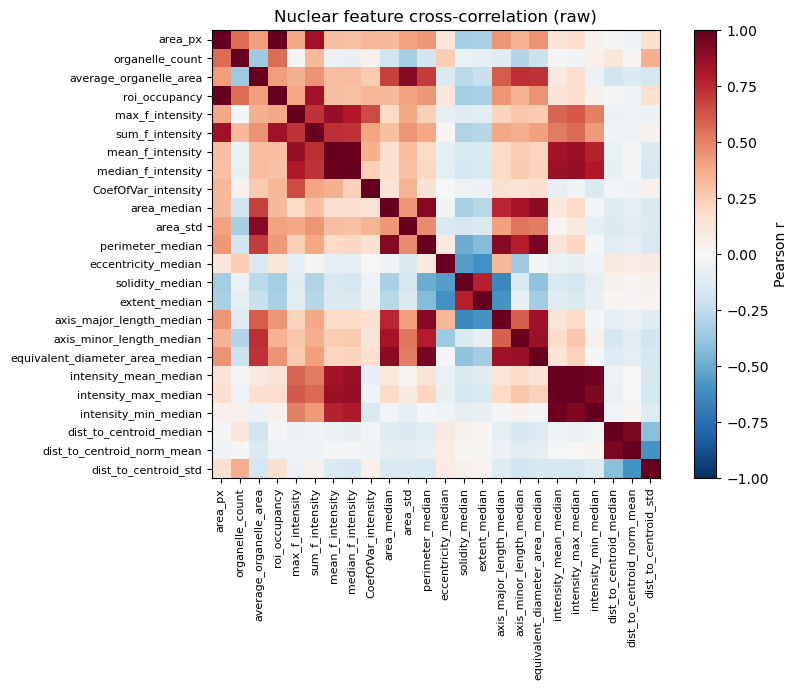

Highly correlated pairs (|r| > 0.9):
  +1.000  area_px                roi_occupancy
  +0.987  intensity_mean_median  intensity_max_median
  +0.982  mean_f_intensity       median_f_intensity
  +0.970  intensity_mean_median  intensity_min_median
  +0.946  perimeter_median       equivalent_diameter_area_median
  +0.941  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.935  intensity_max_median   intensity_min_median
  +0.914  area_median            perimeter_median
  +0.911  average_organelle_area area_std
  +0.908  perimeter_median       axis_major_length_median
[full] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full] dropped 0 rows with NaN/inf; 1036647 remain
[full] EVR: [0.3   0.183 0.172 0.123 0.089 0.06  0.026 0.022 0.02  0.005 0.   ]
[full] cumulative: [0.3   0.484 0.656 0.779 

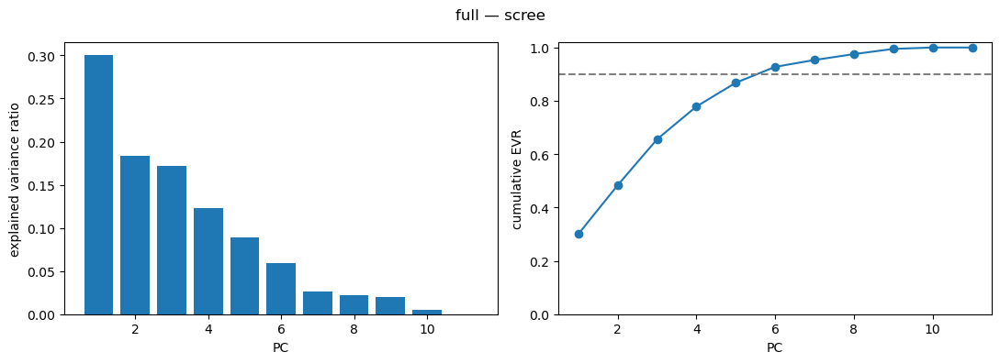

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.474 -0.063 -0.237  0.225 -0.034 -0.290 -0.143   
organelle_count             0.288 -0.325 -0.193  0.261 -0.400  0.392  0.069   
roi_occupancy               0.474 -0.063 -0.237  0.225 -0.034 -0.290 -0.143   
mean_f_intensity            0.247  0.536 -0.211 -0.217  0.002  0.252  0.016   
CoefOfVar_intensity         0.197  0.083 -0.236  0.100  0.819  0.319  0.064   
eccentricity_median         0.246 -0.193  0.476 -0.059  0.003  0.534 -0.525   
solidity_median            -0.363 -0.017 -0.427  0.169 -0.075  0.239 -0.327   
extent_median              -0.362  0.006 -0.446  0.160 -0.080  0.139 -0.226   
intensity_max_median        0.188  0.533 -0.106 -0.280 -0.380  0.163  0.012   
dist_to_centroid_norm_mean -0.044  0.246  0.240  0.676 -0.094  0.252  0.489   
dist_to_centroid_std        0.090 -0.459 -0.272 -0.424 -0.048  0.247  0.526   

                              PC8    PC9   PC10   P

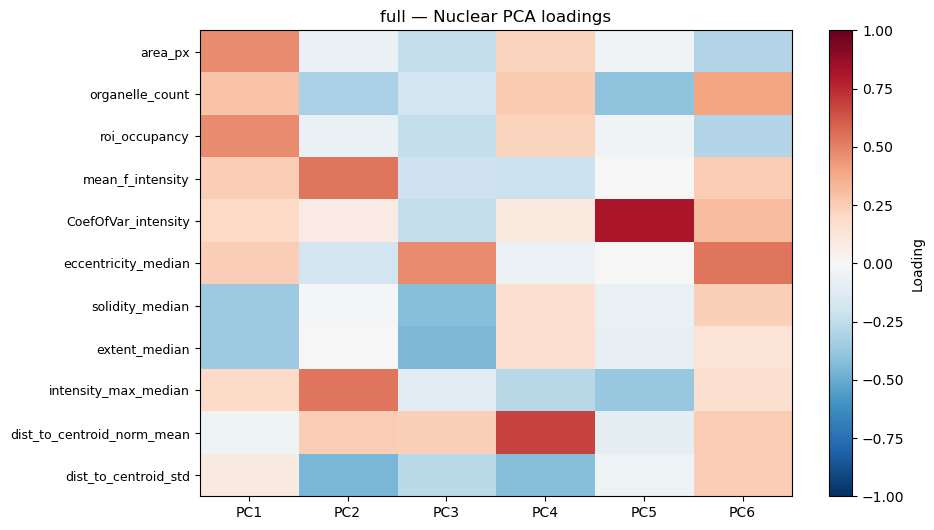

In [6]:
feature_correlation(df)
df, pca, FEATURES = fit_pca(df, label="full")

### PCA plots
Assessment of ROI level data for features

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey


# ===========================================================================
# Palettes
# ===========================================================================
def make_palette(values, hue_bounds=(60, 500.0), chroma_bounds=(40, 130)):
    """Stable {value: color} mapping for a categorical column, derived from
    the data (not a hardcoded set). Sorted so colors are reproducible."""
    vals = sorted(pd.Series(values).dropna().unique())
    raw = glasbey.create_palette(palette_size=max(len(vals), 1),
                                 hue_bounds=hue_bounds, chroma_bounds=chroma_bounds)
    cmap = ListedColormap(raw)
    pal = {v: cmap(i) for i, v in enumerate(vals)}
    return pal


# high-cardinality fallback for genotype-like columns with no fixed mapping
_GENO_RAW = glasbey.create_palette(palette_size=64, hue_bounds=(0.0, 360.0),
                                   chroma_bounds=(40, 90))
GENO_COLORS = [ListedColormap(_GENO_RAW)(i) for i in range(64)]


def check_palette_coverage(data, col, palette):
    """Warn about values present in the data but missing from the palette."""
    present = set(data[col].dropna().unique())
    missing = present - set(palette)
    print(f"[warning] {col} values with no color: {sorted(missing)}" if missing
          else f"All {len(present)} {col} values have a color.")


# ===========================================================================
# Scatter: one PCA panel colored by a categorical column
# ===========================================================================
def pca_scatter(data, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True, shuffle=True, random_state=0):
    """PCA scatter colored by `color_col`.

    palette : optional {value: color} dict. If None, Gene_Var_Type uses the
              glasbey genotype colors and everything else falls back to husl.
    shuffle : plot rows in random order so no single group sits on top.
    """
    if shuffle:
        data = data.sample(frac=1, random_state=random_state).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = data[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [GENO_COLORS[i % len(GENO_COLORS)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(data.loc[m, pcx], data.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()
    return ax


# ===========================================================================
# Centroid overlay: per-group centroids over a faint background cloud
# ===========================================================================
def centroid_overlay(data, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = data.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else data
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = data.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    colors = ([palette.get(c, "#808080") for c in cats] if palette
              else sns.color_palette("husl", n_colors=len(cats)))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent


# ===========================================================================
# Convenience: a standard panel set for one scored frame
# ===========================================================================
def scatter_panels(data, specs, label="Mitochondria", s=2, alpha=0.15, figsize=(12, 7)):
    """Run pca_scatter for several columns in one call.

    specs : list of (column, palette_or_None). Pass a palette dict for columns
            you want stable colors on (plate, batch); None lets the function
            pick (glasbey for Gene_Var_Type, husl otherwise).
    """
    for col, pal in specs:
        pca_scatter(data, col, palette=pal, s=s, alpha=alpha, figsize=figsize,
                    legend_ncol=2 if col in ("Gene_Var_Type", "Genotype_Name") else 1,
                    title=f"{label} — {col}")


# --- usage -----------------------------------------------------------------
# build palettes once from whatever frame you're plotting:
# plate_pal = make_palette(df["iNDI_Plate_ID"])
# batch_pal = make_palette(df["Batch"])
# check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
#
# # single calls, anywhere later in the script -- no global dependencies:
# pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7),
#             title="Nuclei — iNDI_Plate_ID")
# pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
#             title="Nuclei — Gene_Var_Type")
#
# # or the whole standard set at once:
# scatter_panels(df, [
#     ("iNDI_Plate_ID", plate_pal),
#     ("Source",        None),
#     ("Batch",         batch_pal),
#     ("Asp PosID",     None),
#     ("Gene_Var_Type", None),
# ])
#
# centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal,
#                  figsize=(12, 7), title="Per-experiment medians (by plate)")
# cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
# print("Std of per-experiment centroids (batch magnitude):")
# print(cent.std().round(3))

All 21 iNDI_Plate_ID values have a color.


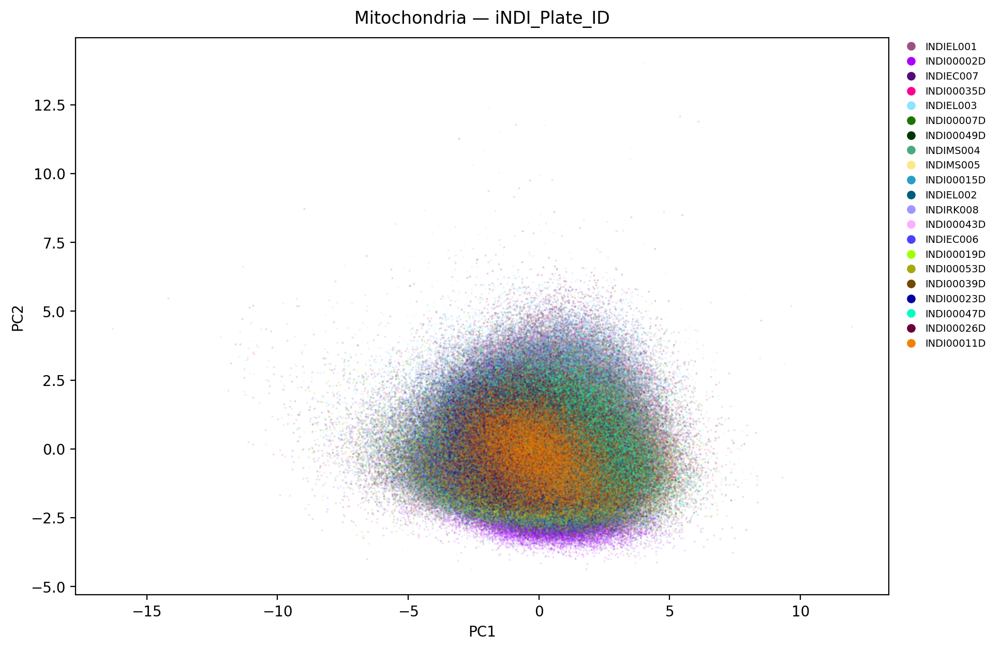

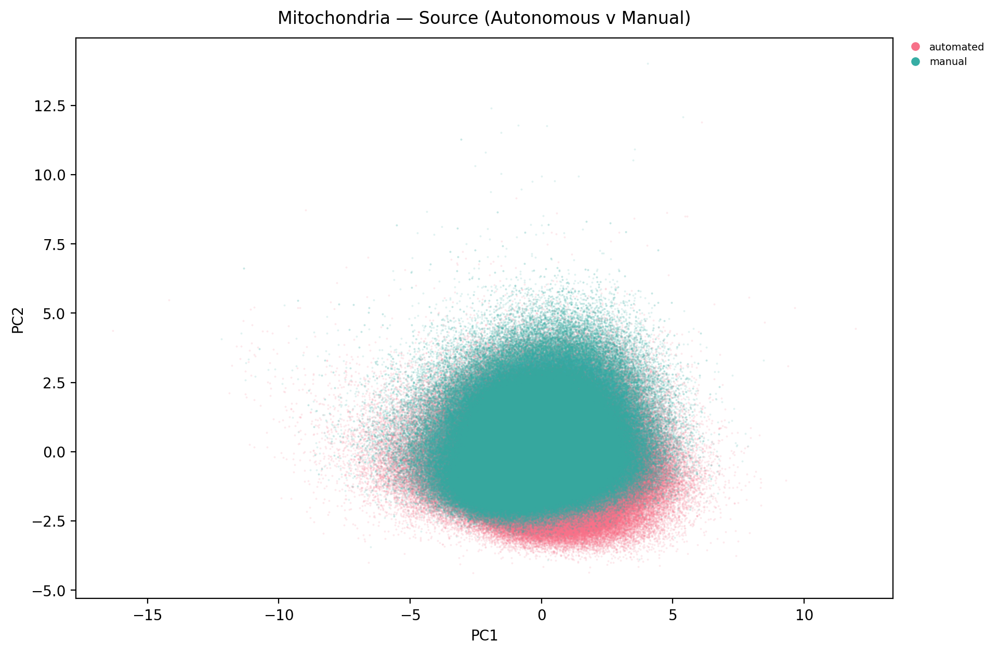

All 5 Batch values have a color.


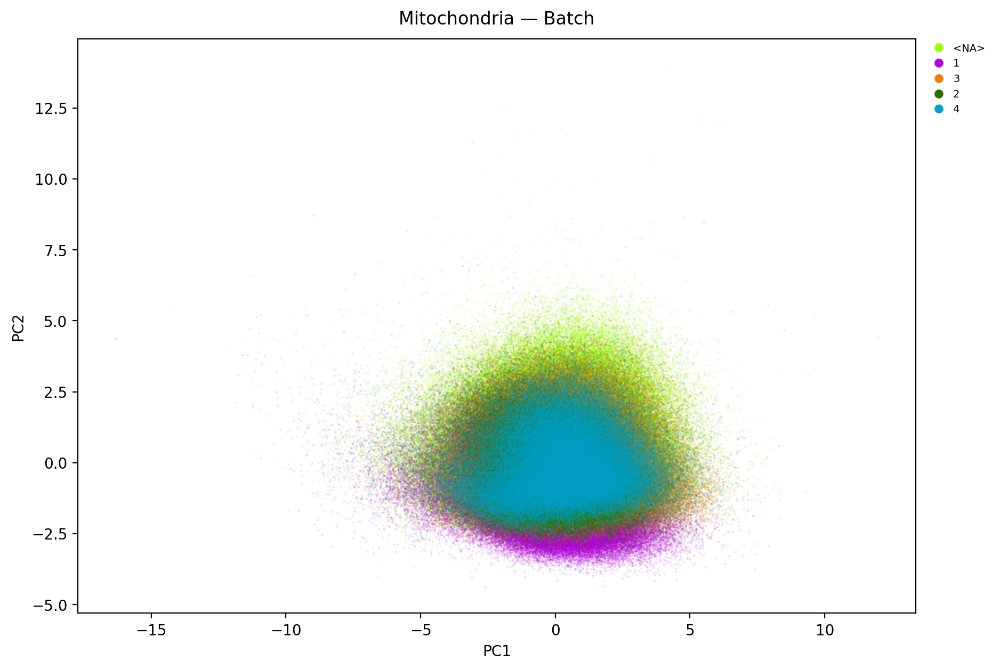

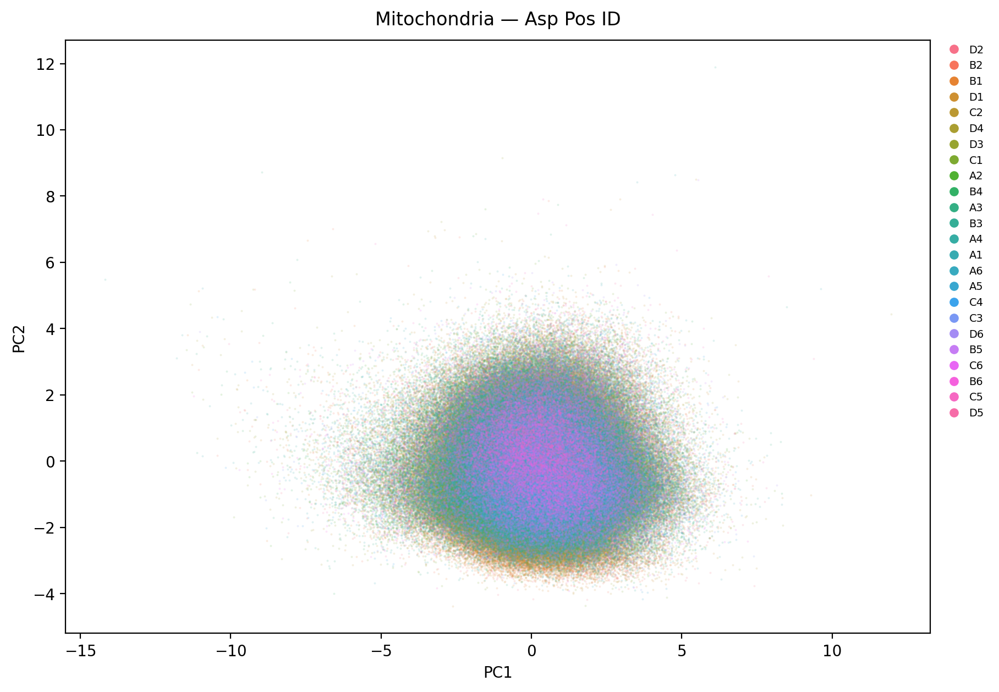

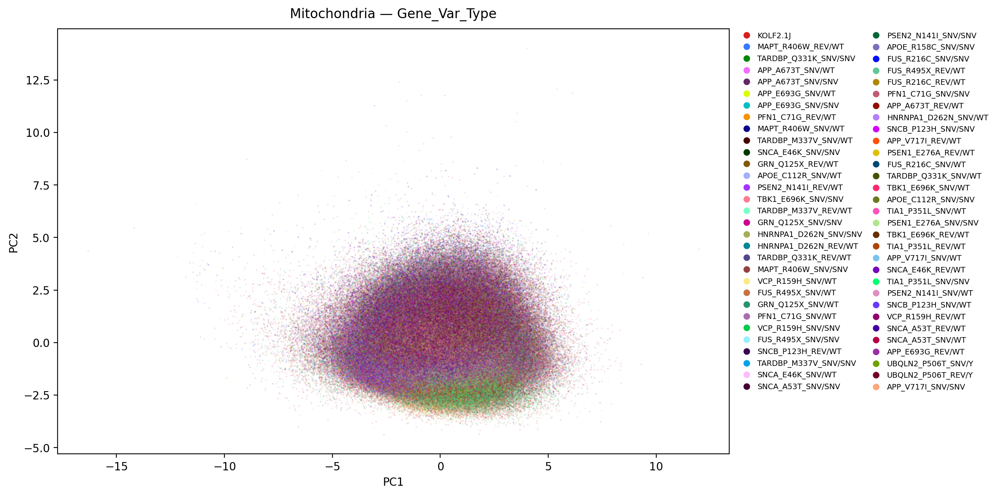

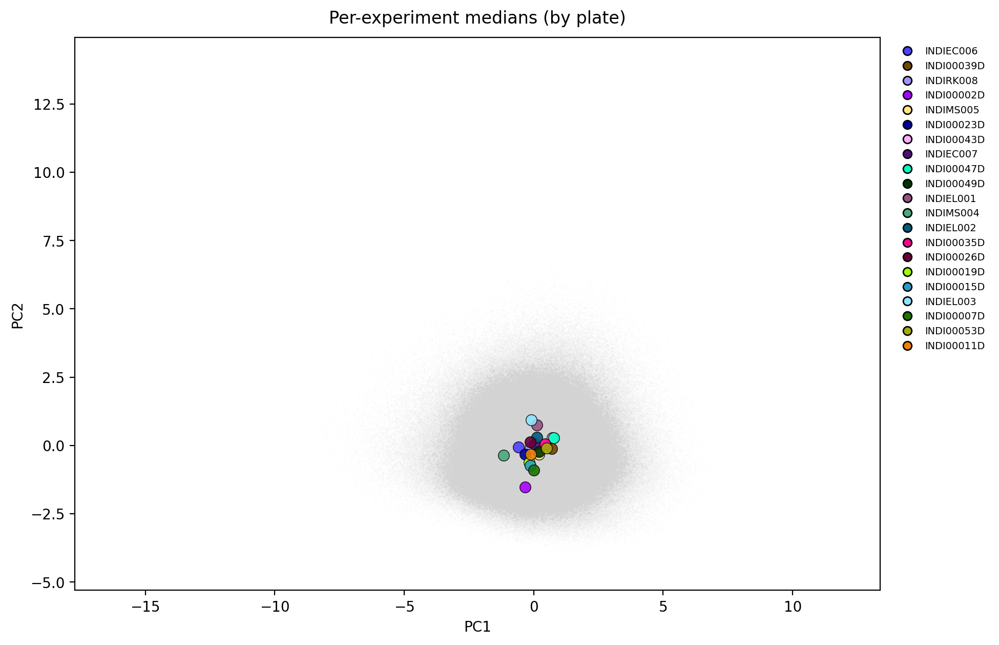

Std of per-experiment centroids (batch magnitude):
PC1    0.457
PC2    0.543
PC3    0.527
dtype: float64


In [8]:
plate_pal = make_palette(df["iNDI_Plate_ID"])
check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Mitochondria — iNDI_Plate_ID")

pca_scatter(df, "Source", figsize=(12, 7),title="Mitochondria — Source (Autonomous v Manual)")

batch_palette = make_palette(df["Batch"])
check_palette_coverage(df, "Batch", batch_palette)
pca_scatter(df, "Batch", palette=batch_palette, figsize=(12, 7),title="Mitochondria — Batch")

pca_scatter(df, "Asp PosID", figsize=(12, 7),title="Mitochondria — Asp Pos ID")

pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Mitochondria — Gene_Var_Type")

centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### Variance-component analysis

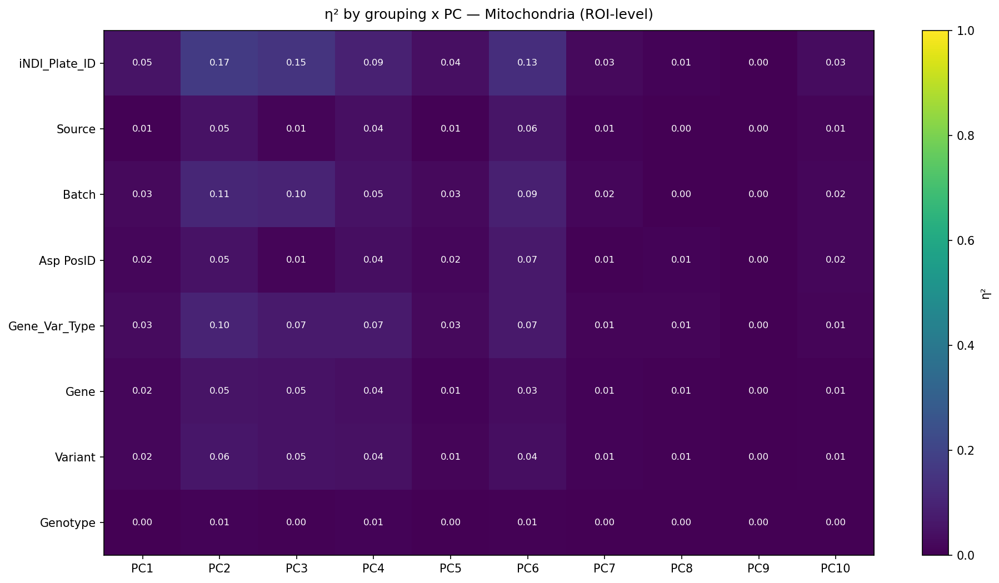

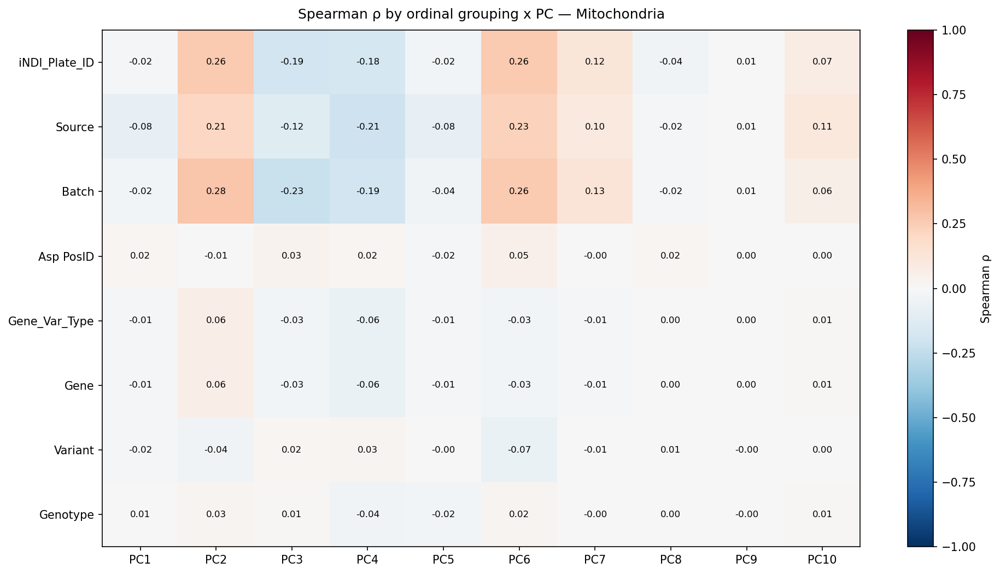

In [9]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:            # guard: skip empty groups
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, n_pcs=None, title="η² by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    fig, ax = plt.subplots(figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

# Structure dropped (single channel). Batch drivers that matter:
GROUP_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=10, title="η² by grouping x PC — Mitochondria (ROI-level)")

from scipy.stats import spearmanr

def spearman_heatmap(data, group_cols, n_pcs=None,
                     title="Spearman ρ by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)

    for gc in group_cols:
        # ordinal code: use numeric directly if numeric, else factorize
        col = data[gc]
        if pd.api.types.is_numeric_dtype(col):
            codes = col.to_numpy(dtype=float)
        else:
            codes = pd.factorize(col, sort=True)[0].astype(float)
            codes[codes < 0] = np.nan  # NaNs come back as -1
        for pc in pc_cols:
            x = data[pc].to_numpy(dtype=float)
            m = np.isfinite(x) & np.isfinite(codes)
            if m.sum() < 3:
                mat.loc[gc, pc] = np.nan
                continue
            rho, _ = spearmanr(x[m], codes[m])
            mat.loc[gc, pc] = rho

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    # diverging map + symmetric limits since ρ ∈ [-1, 1]
    im = ax.imshow(mat.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="Spearman ρ")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if abs(v) > 0.5 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

ORDINAL_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
spear = spearman_heatmap(df, ORDINAL_COLS, n_pcs=10,
                         title="Spearman ρ by ordinal grouping x PC — Mitochondria")

[facet] 16 genes; 236431 total KOLF2.1J rows (all folded into each facet)
  APOE: 38658 variant + 236431 KOLF rows


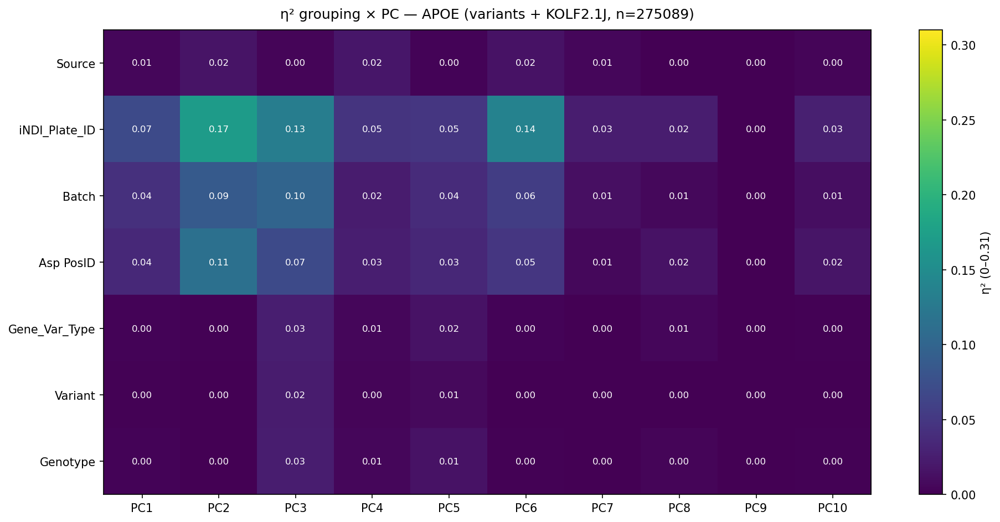

  APP: 119477 variant + 236431 KOLF rows


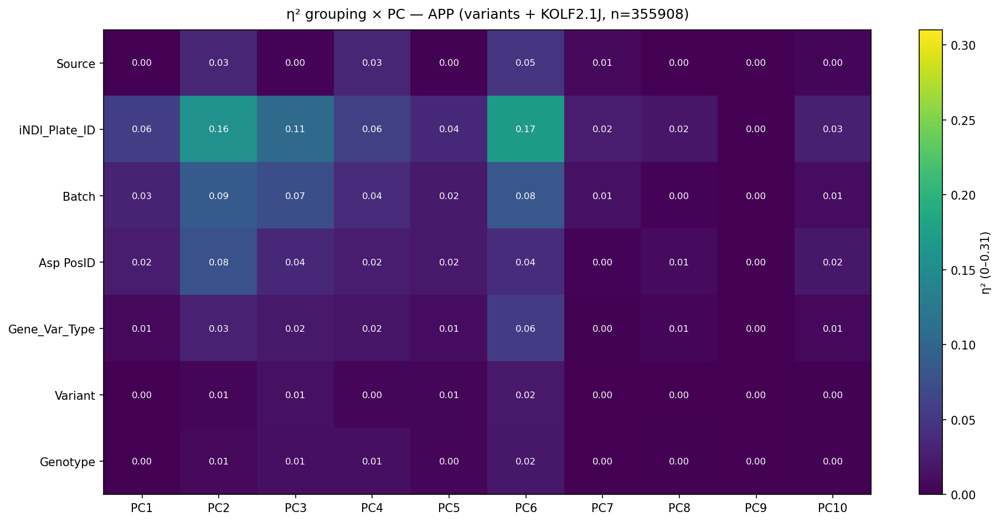

  FUS: 75276 variant + 236431 KOLF rows


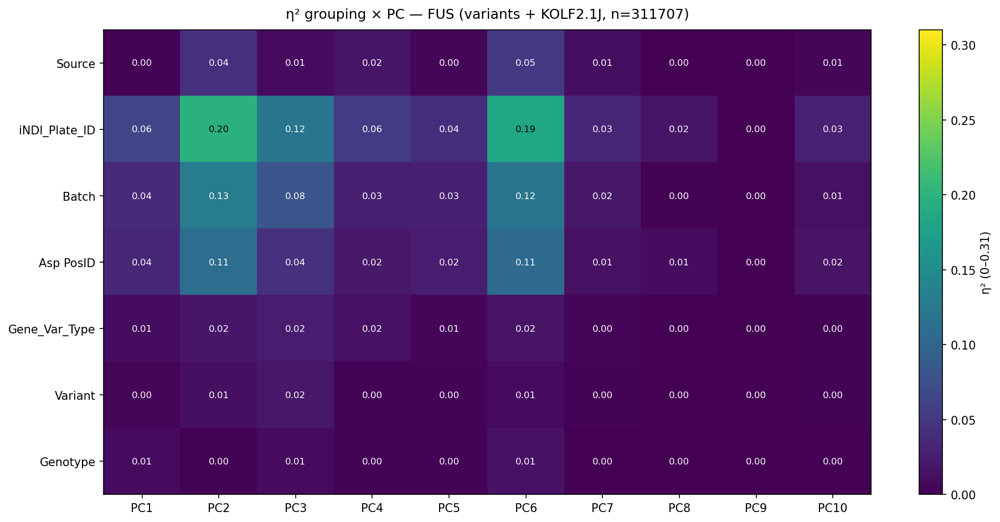

  GRN: 47221 variant + 236431 KOLF rows


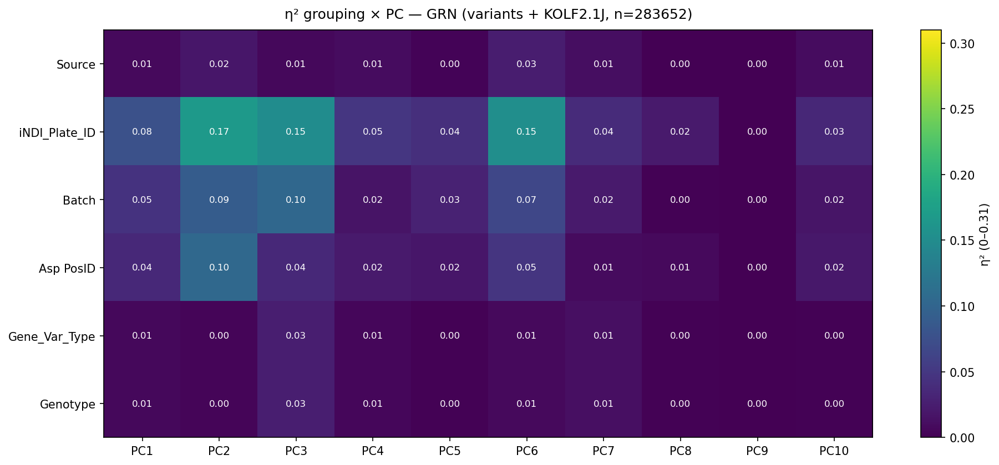

  HNRNPA1: 42560 variant + 236431 KOLF rows


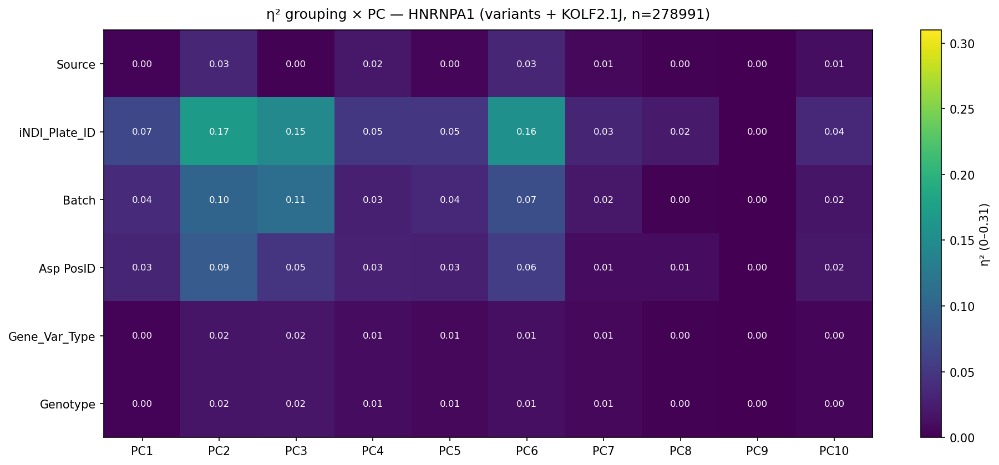

  MAPT: 59872 variant + 236431 KOLF rows


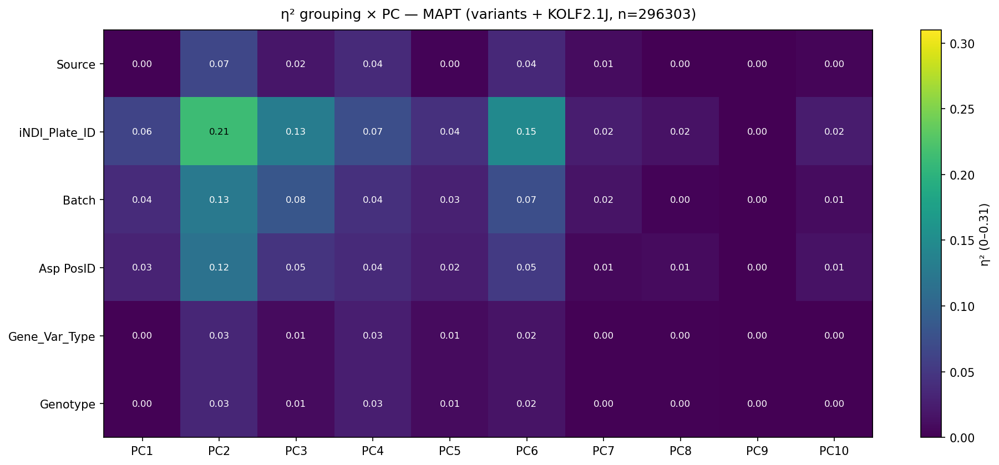

  PFN1: 44378 variant + 236431 KOLF rows


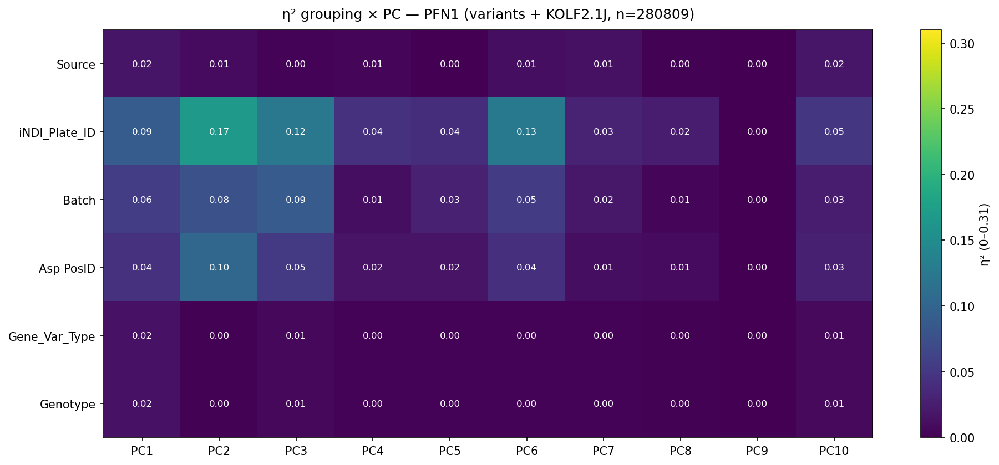

  PSEN1: 19413 variant + 236431 KOLF rows


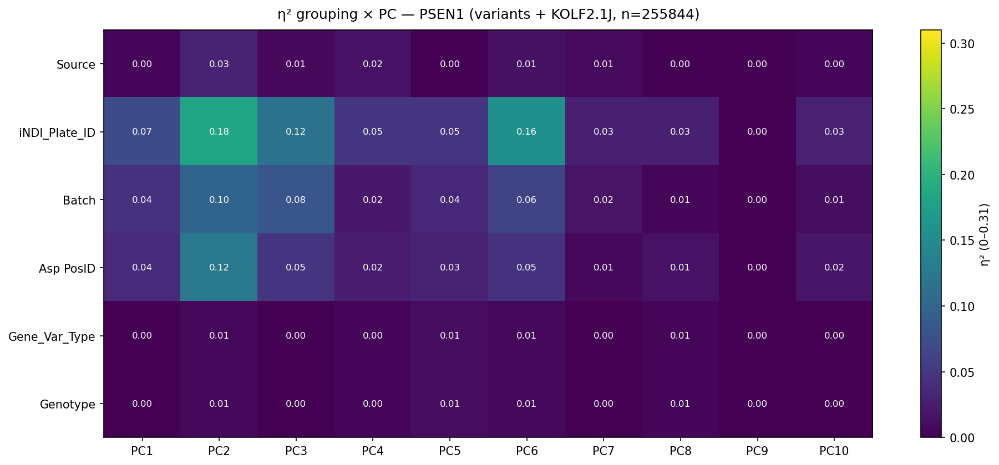

  PSEN2: 37148 variant + 236431 KOLF rows


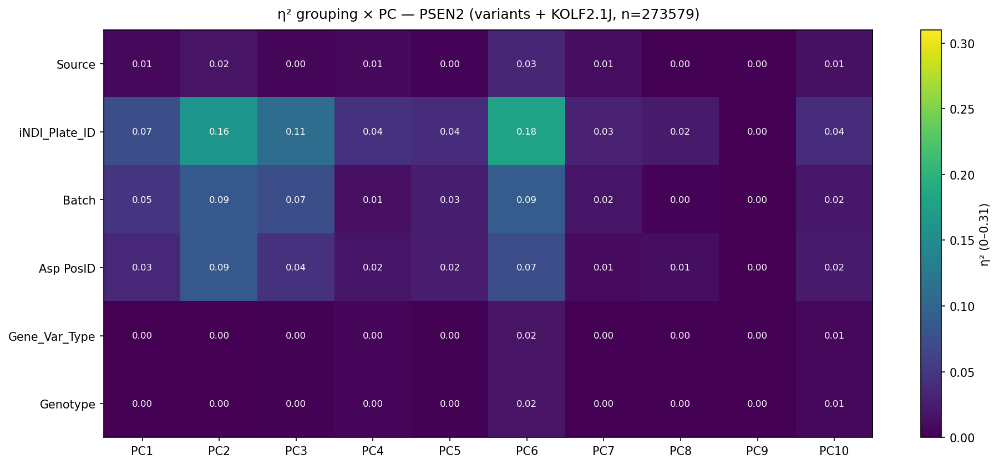

  SNCA: 66779 variant + 236431 KOLF rows


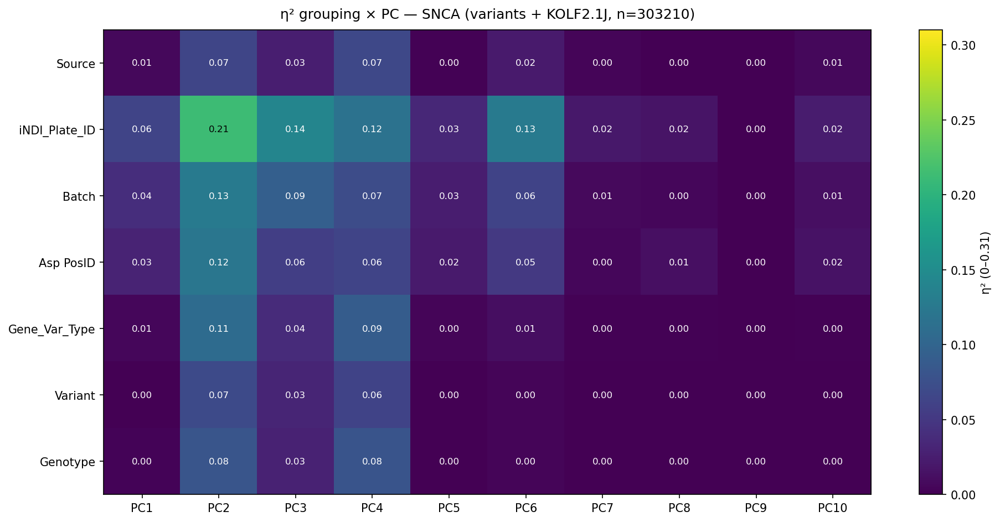

  SNCB: 32074 variant + 236431 KOLF rows


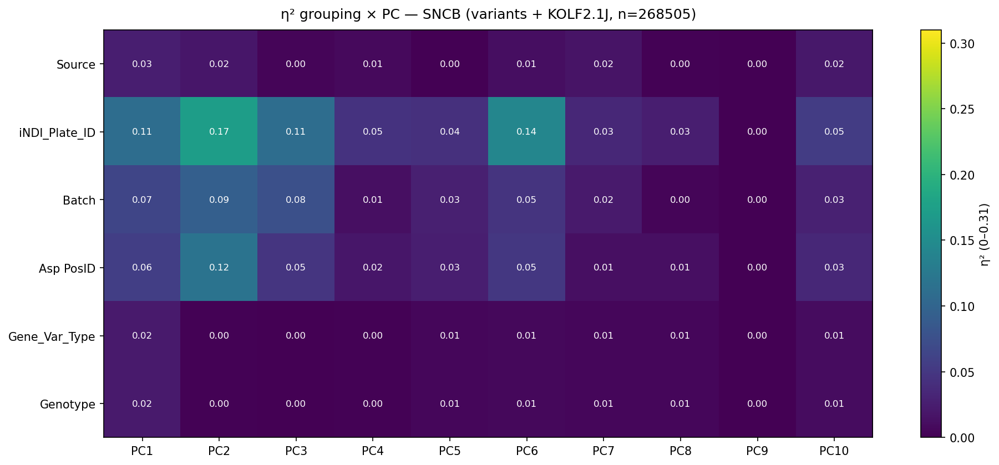

  TARDBP: 98427 variant + 236431 KOLF rows


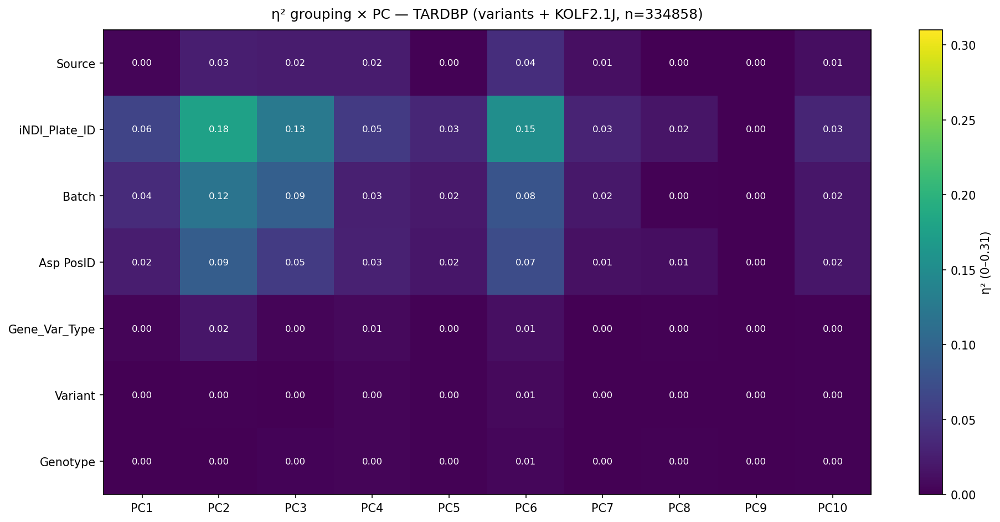

  TBK1: 35093 variant + 236431 KOLF rows


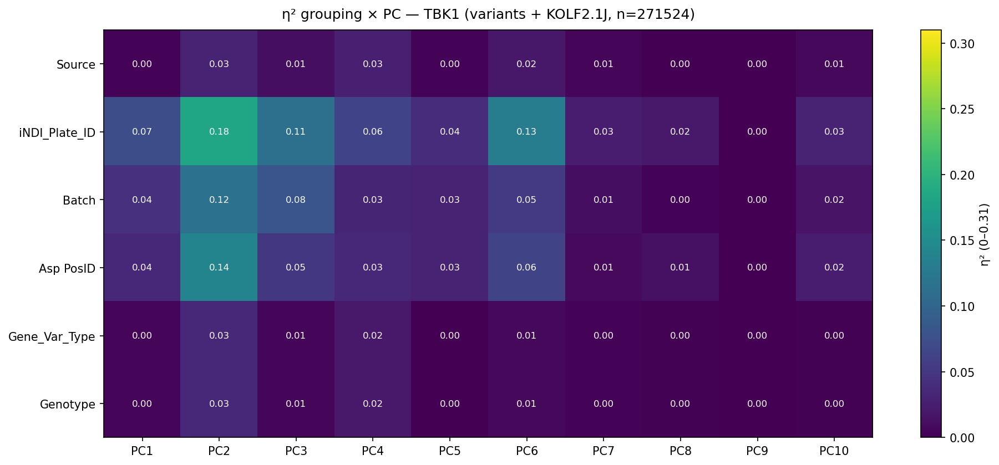

  TIA1: 26060 variant + 236431 KOLF rows


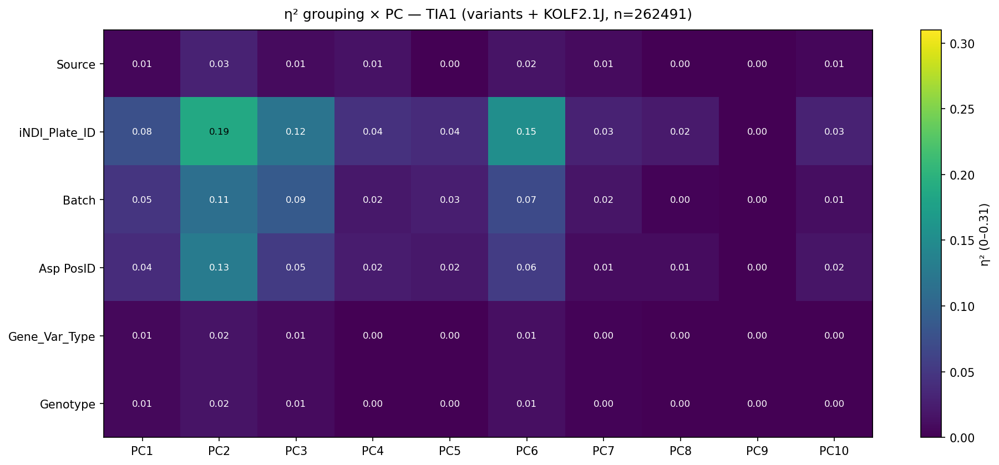

  UBQLN2: 12836 variant + 236431 KOLF rows


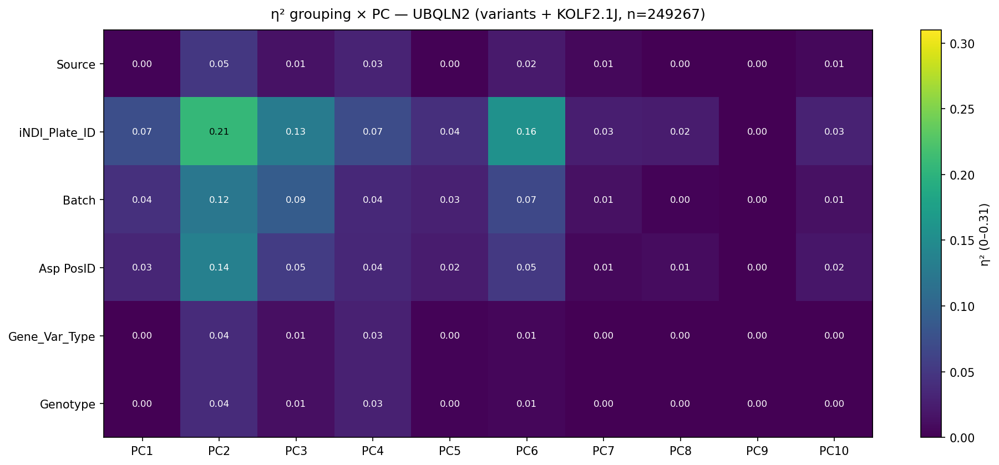

  VCP: 36655 variant + 236431 KOLF rows


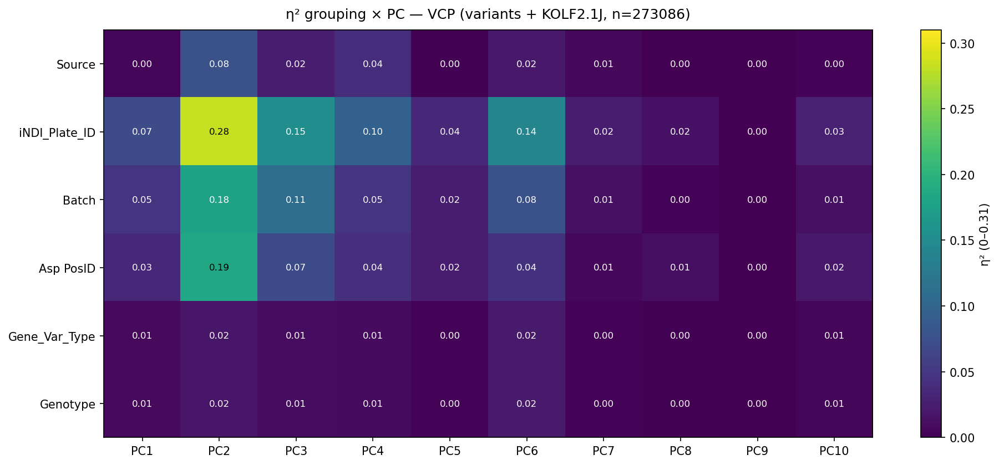

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene: ONE SEPARATE FIGURE per gene --------------------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, vmax=0.2, annot=True,
                      drop_constant=True):
    """Draw a single grouping x PC η² heatmap for one gene's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} (variants + KOLF2.1J, n={len(sub)})",
                 pad=10)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene(data, group_cols, n_pcs=10,
                  gene_col="Gene", vmax=0.2, annot=True,
                  include_wt=True, drop_constant=True,
                  plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per gene. Each gene's subset is that
    gene's variant rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that gene's variants actually occupy, removing the plate confound
    that arises when controls span all plates but a gene sits on only a few.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]
    genes = sorted(pd.unique(edited[gene_col].dropna()))
    print(f"[facet] {len(genes)} genes; {len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    facet_groups = [g for g in group_cols if g != gene_col]

    mats = {}
    for gene in genes:
        gene_rows = edited[edited[gene_col] == gene]
        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                gene_plates = set(gene_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(gene_plates)]
            sub = pd.concat([gene_rows, wt_use], ignore_index=True)
            print(f"  {gene}: {len(gene_rows)} variant + {len(wt_use)} KOLF rows"
                  f"{f' on {len(set(gene_rows[plate_col].dropna().unique()))} plate(s)' if plate_match else ''}")
        else:
            sub = gene_rows
        mats[gene] = plot_gene_heatmap(sub, facet_groups, pc_cols, gene,
                                       vmax=vmax, annot=annot,
                                       drop_constant=drop_constant)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

# recommended: aggregate to wells first (adjust well_keys to your schema)
# pc_cols = sorted([c for c in df.columns if c.startswith("PC")], key=lambda s: int(s[2:]))[:10]
# well_df = aggregate_to_wells(
#     df,
#     well_keys=["iNDI_Plate_ID", "Row", "Column"],
#     carry_cols=GROUP_COLS + ["Gene"],
#     pc_cols=pc_cols,
# )
# facet_grid_by_gene(well_df, GROUP_COLS, n_pcs=10, vmax=0.2)

# or straight on ROI-level df (noisier):
mats = facet_by_gene(df, GROUP_COLS, n_pcs=10, vmax=0.31)

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 194111 rows (13440 images)
[full] well-level: 5936 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 5936 remain
[full well] EVR: [0.265 0.233 0.185 0.155 0.093 0.044 0.013 0.008 0.004 0.001 0.   ]
[full well] cumulative: [0.265 0.498 0.683 0.838 0.93  0.975 0.988 0.995 0.999 1.    1.   ]


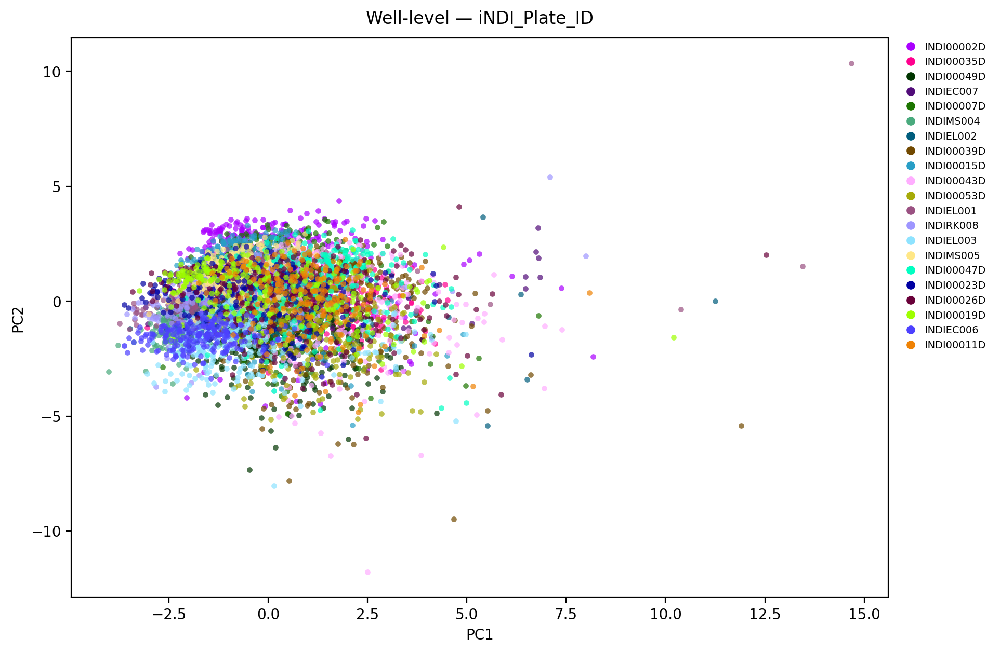

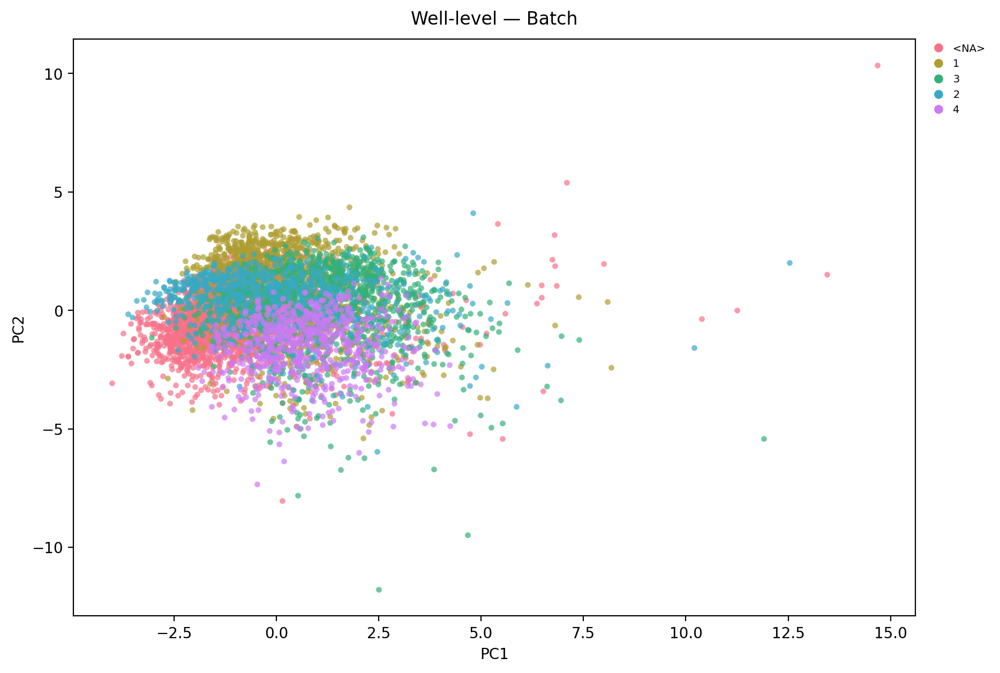

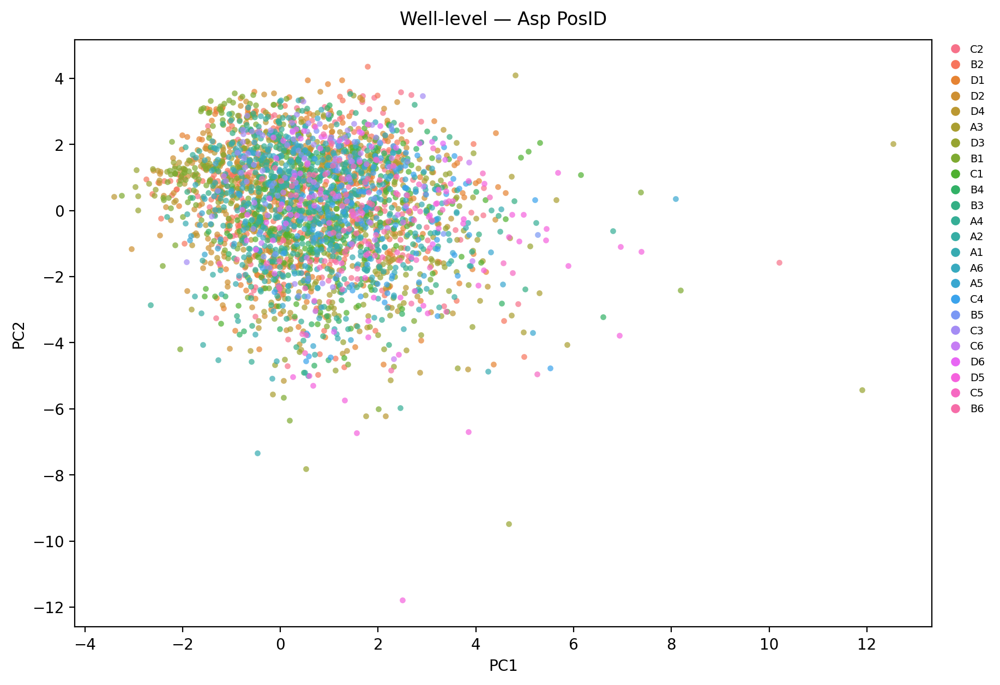

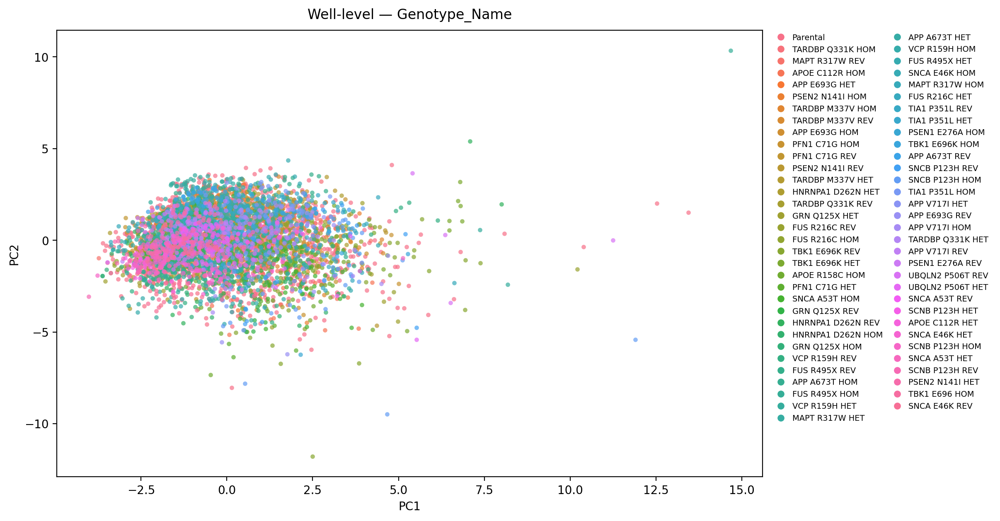

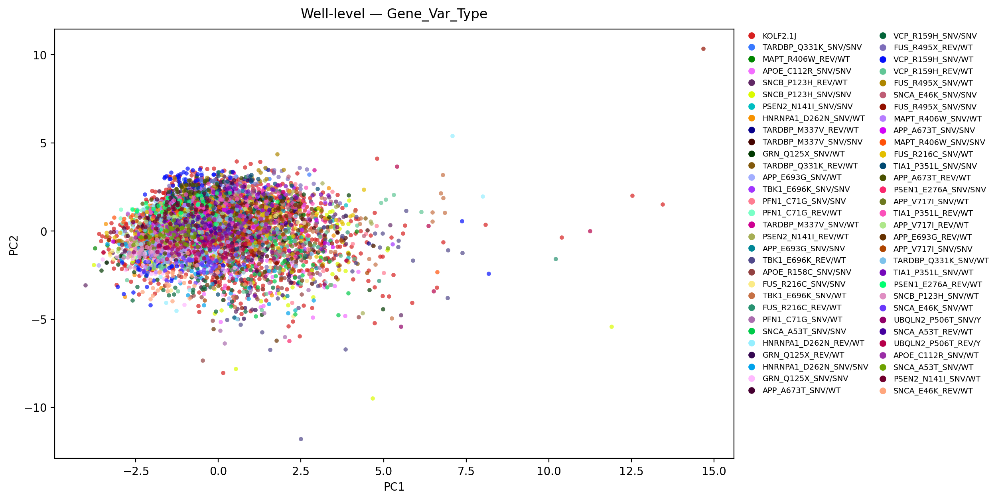

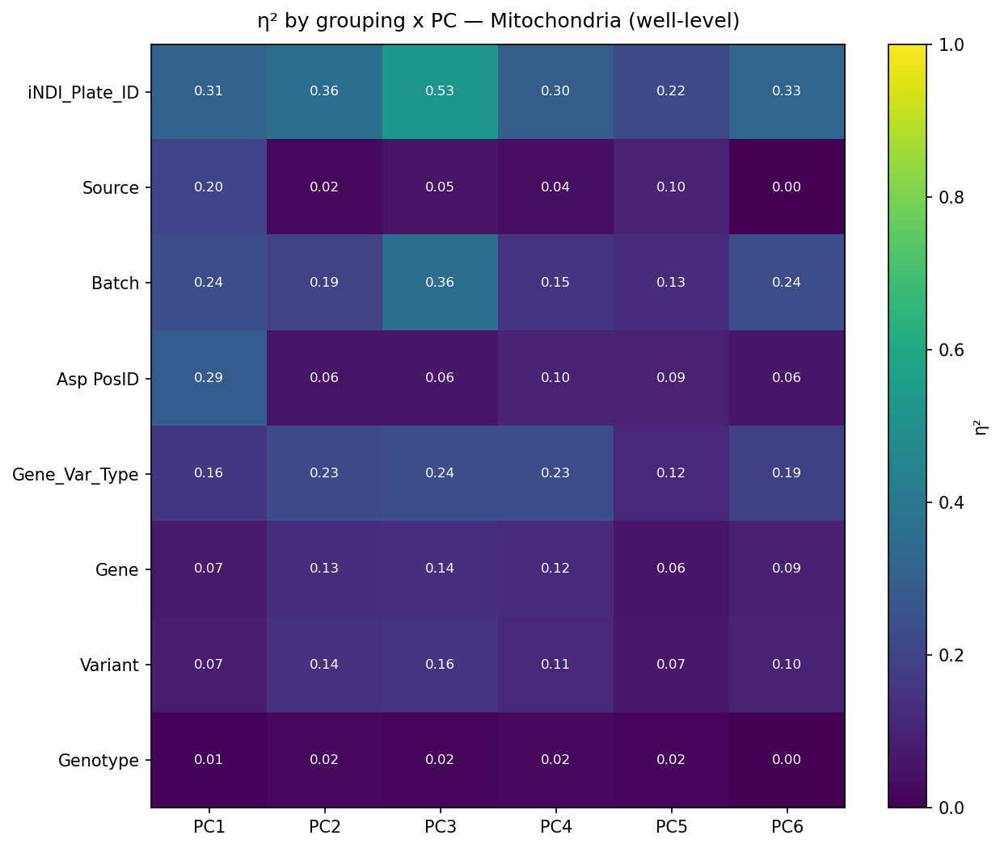

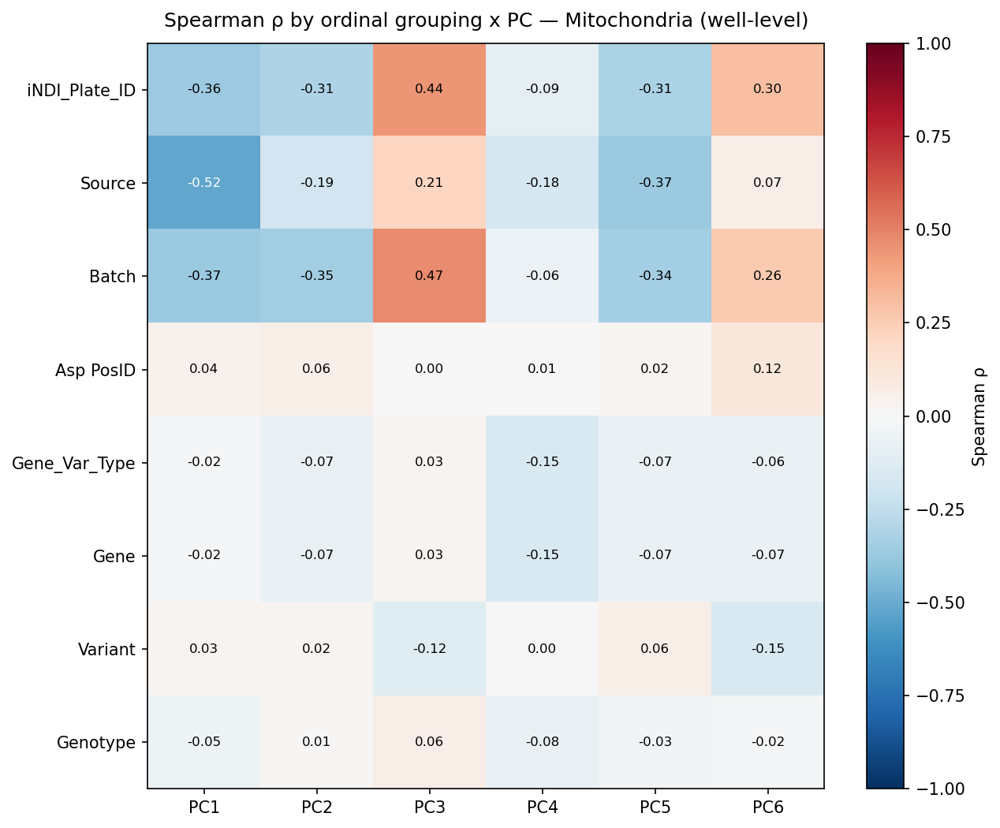

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.364770,-0.305423,0.437934,-0.088335,-0.313766,0.299678
Source,-0.516910,-0.187821,0.214557,-0.176970,-0.372166,0.067375
Batch,-0.374995,-0.346072,0.468816,-0.062448,-0.340041,0.262003
Asp PosID,0.040274,0.059171,0.003691,0.006362,0.019147,0.116185
Gene_Var_Type,-0.020620,-0.071998,0.028418,-0.149513,-0.067245,-0.064398
Gene,-0.019387,-0.072495,0.029297,-0.149410,-0.069894,-0.066597
Variant,0.027135,0.023439,-0.120055,0.002858,0.056674,-0.154537
Genotype,-0.053451,0.011157,0.063672,-0.076093,-0.030511,-0.017035


In [11]:
import numpy as np
import pandas as pd

# well = Measurement_ID + subdirectory; image = channel_filename
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "channel_filename"


def aggregate_wells(data, features, well_keys=WELL_KEYS, image_key=IMAGE_KEY,
                    check_cols=("Genotype_Name", "iNDI_Plate_ID", "prep_method"),
                    label="", image_stat="median", well_stat="mean",
                    n_pc_drop=20):
    """Collapse ROI -> image -> well.

    stage 1: `image_stat` across ROI within each image
    stage 2: `well_stat` across images within each well

    Metadata columns (everything that isn't a feature, PC, or key) are carried
    through with .first(), after a safety check that they're invariant within a
    well. Returns the well-level dataframe (NOT PCA-scored -- run fit_pca next).
    """
    features = [f for f in features if f in data.columns]
    group_keys = [*well_keys, image_key]
    drop_cols = (set(features) | {f"PC{i+1}" for i in range(n_pc_drop)}
                 | set(group_keys) | {"label", "filename", "filepath"})
    meta_cols = [c for c in data.columns if c not in drop_cols]

    # safety: metadata carried by .first() should be invariant within a well
    for col in check_cols:
        if col in data.columns:
            n_bad = (data.groupby(well_keys)[col].nunique() > 1).sum()
            print(f"[{label}] {col}: {n_bad} well(s) with >1 value"
                  f"{'  <-- CHECK' if n_bad else ''}")

    # stage 1: within-image summary
    agg_image = {**{f: image_stat for f in features},
                 **{m: "first" for m in meta_cols}}
    image_level = data.groupby(group_keys, as_index=False).agg(agg_image)
    print(f"[{label}] image-level: {len(image_level)} rows "
          f"({data[image_key].nunique()} images)")

    # stage 2: within-well summary across images
    agg_well = {**{f: well_stat for f in features},
                **{m: "first" for m in meta_cols}}
    well_level = image_level.groupby(well_keys, as_index=False).agg(agg_well)
    print(f"[{label}] well-level: {len(well_level)} rows")

    return well_level


# --- usage -----------------------------------------------------------------
# aggregate, then reuse the SAME fit_pca from the feature section (don't
# re-implement the scale/PCA/score here):
#
# well_level = aggregate_wells(df, FEATURES, label="full")
# well_level, pca_well, _ = fit_pca(
#     well_level, features=FEATURES, add_aspect_ratio=False,
#     show_scree=False, show_loadings=False, label="full well",
# )


well_level = aggregate_wells(df, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)
well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — Mitochondria (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Mitochondria (well-level)")

### Variance-component analysis
This is built to handle all of the parental data for each genotype, but remember that this is HIGHLY unbalanced.\
"plate_match=True" will correct for this by only pulling parentals from the plates that each genotype is on, which is more accurate, but NOT a proxy for plate correction

[facet] 16 genes; 1448 total KOLF2.1J rows (all folded into each facet)
  APOE: 224 variant + 1448 KOLF rows


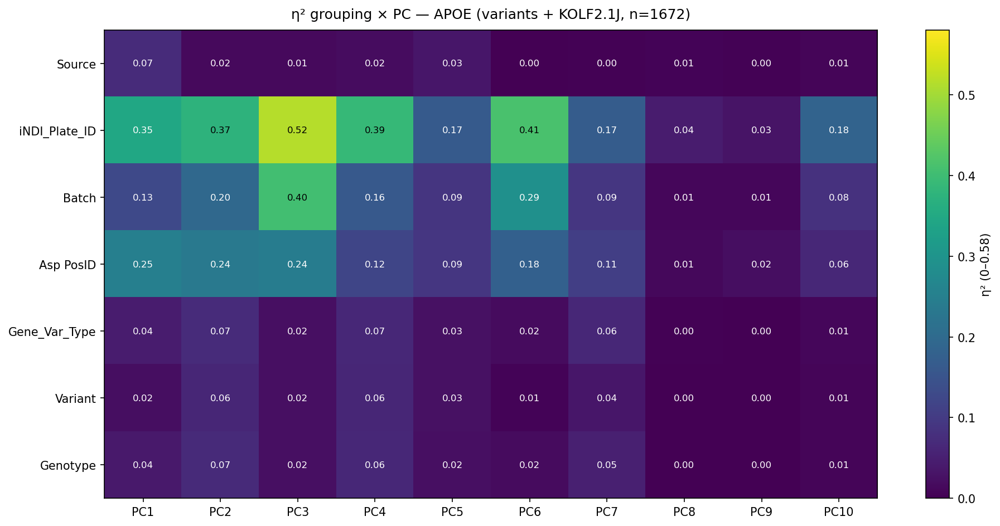

  APP: 572 variant + 1448 KOLF rows


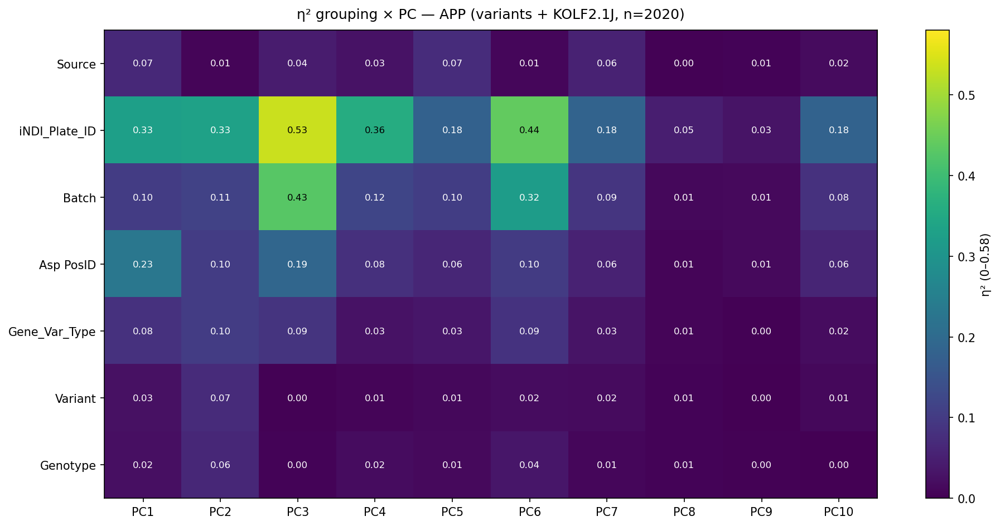

  FUS: 481 variant + 1448 KOLF rows


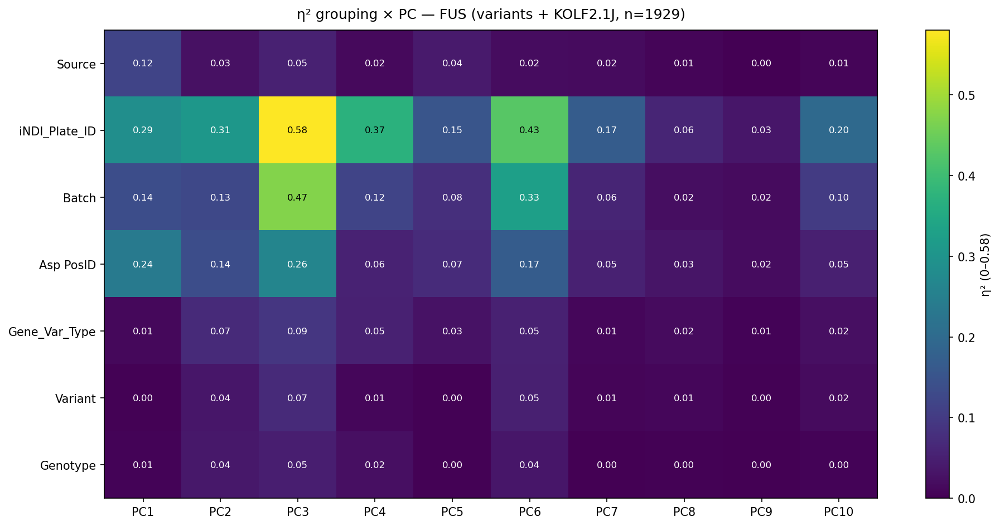

  GRN: 260 variant + 1448 KOLF rows


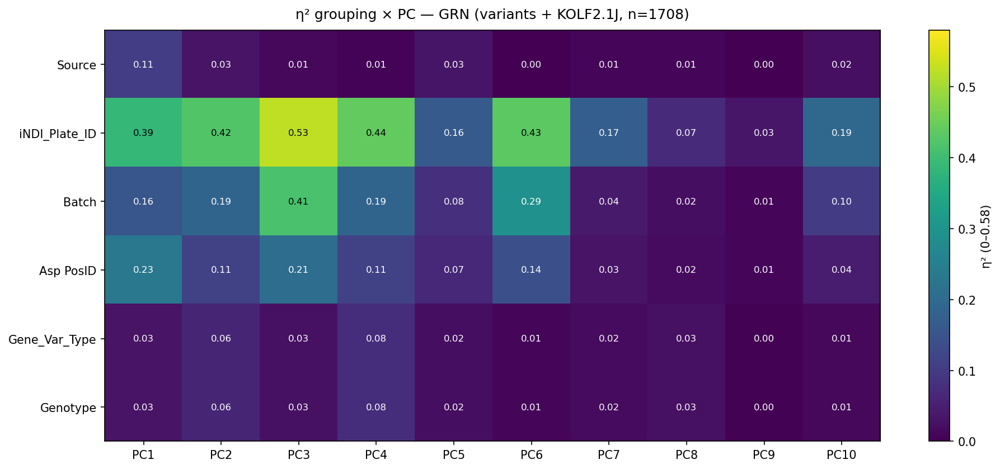

  HNRNPA1: 262 variant + 1448 KOLF rows


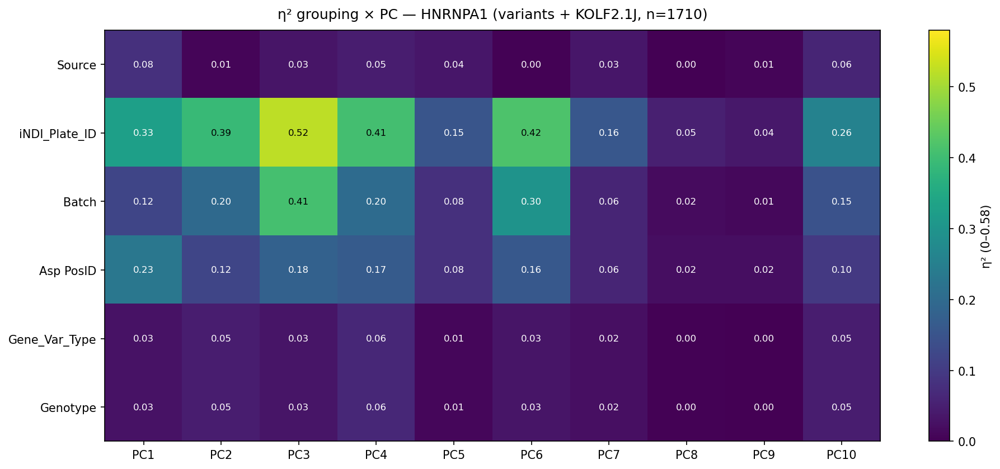

  MAPT: 255 variant + 1448 KOLF rows


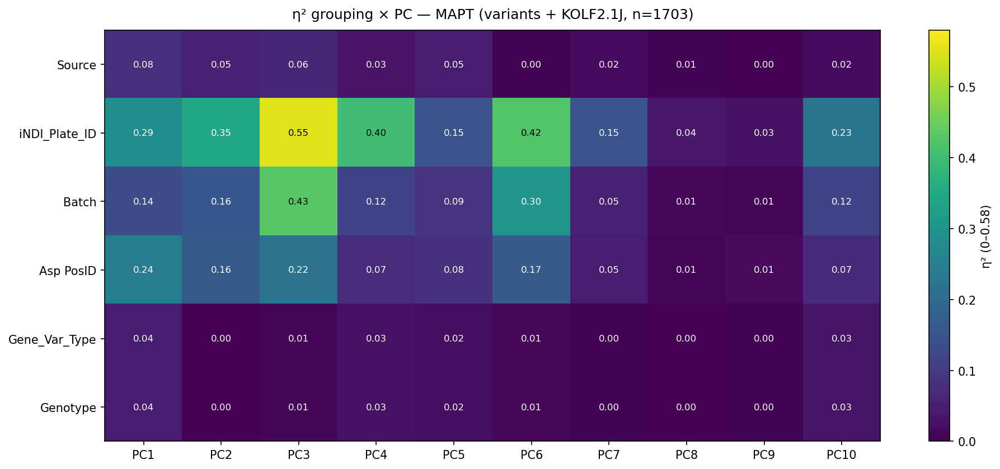

  PFN1: 268 variant + 1448 KOLF rows


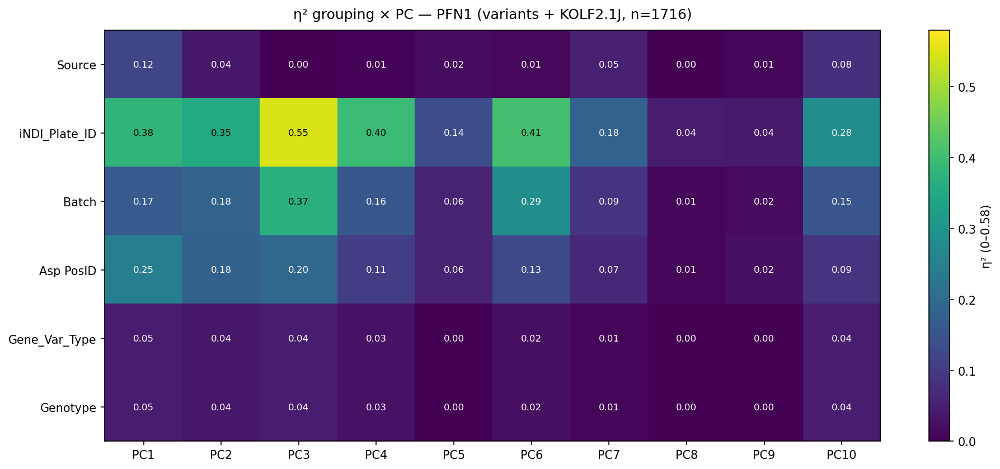

  PSEN1: 95 variant + 1448 KOLF rows


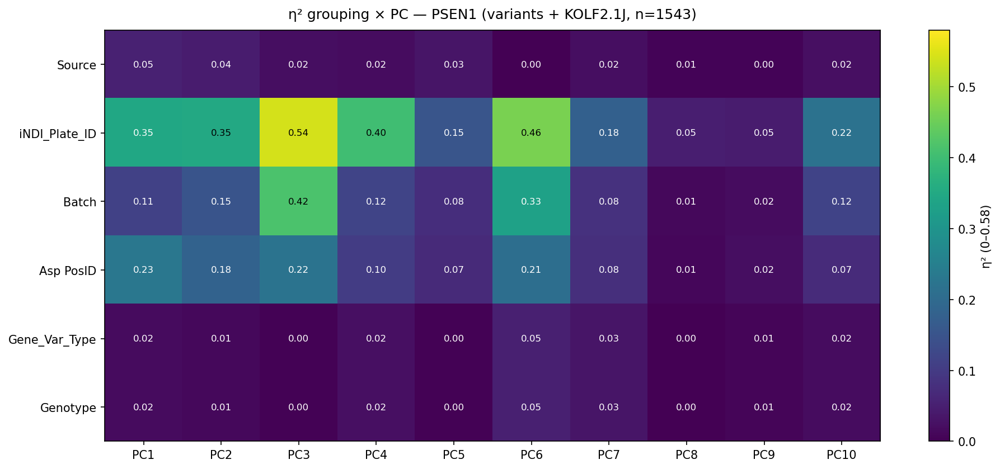

  PSEN2: 222 variant + 1448 KOLF rows


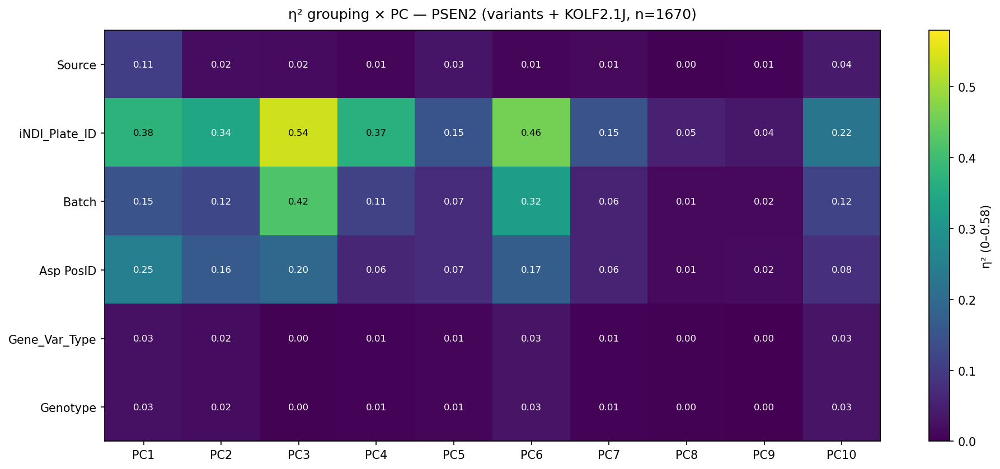

  SNCA: 318 variant + 1448 KOLF rows


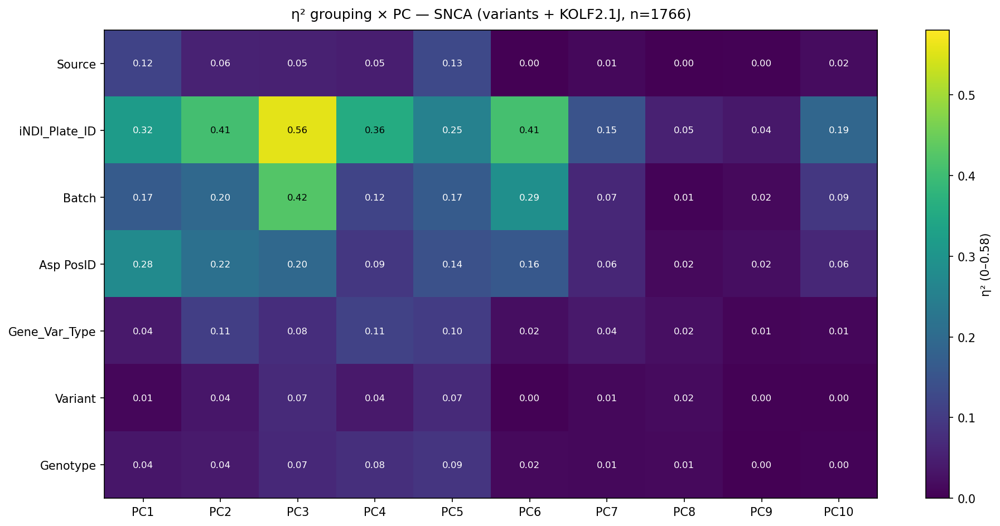

  SNCB: 222 variant + 1448 KOLF rows


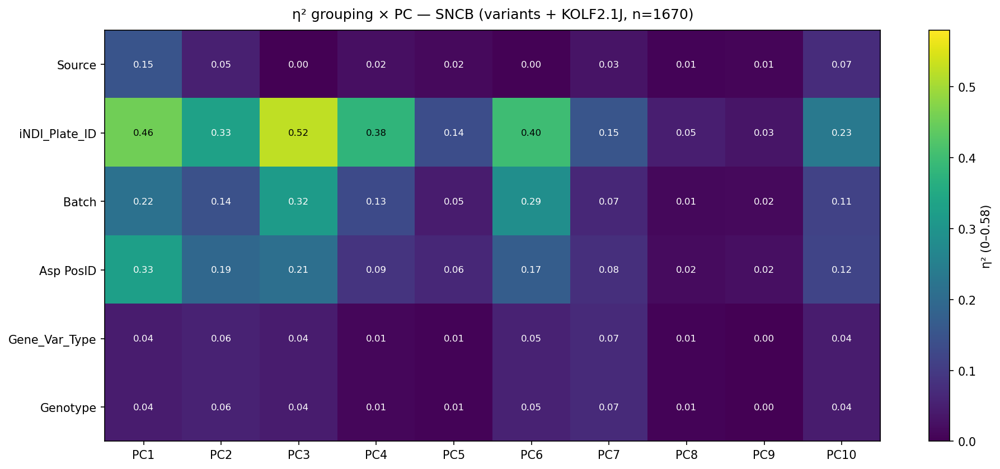

  TARDBP: 539 variant + 1448 KOLF rows


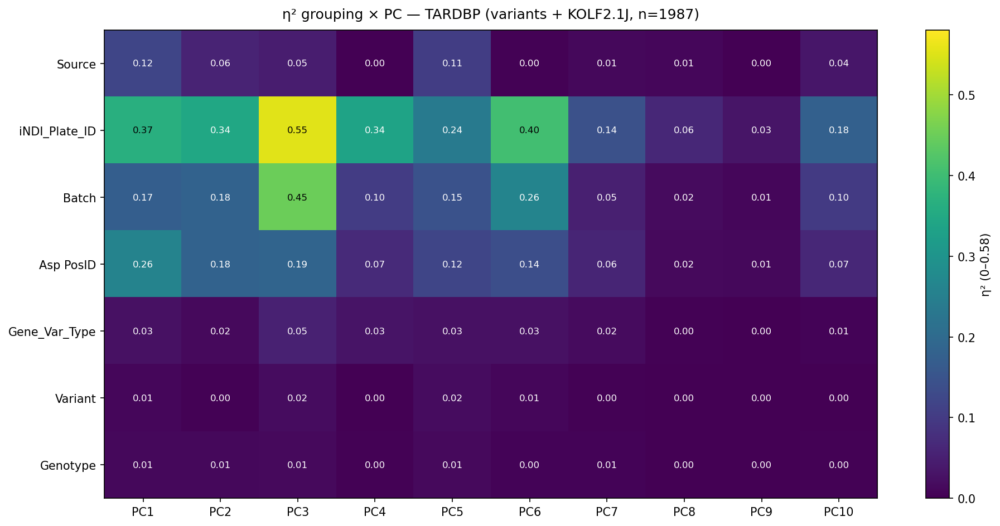

  TBK1: 268 variant + 1448 KOLF rows


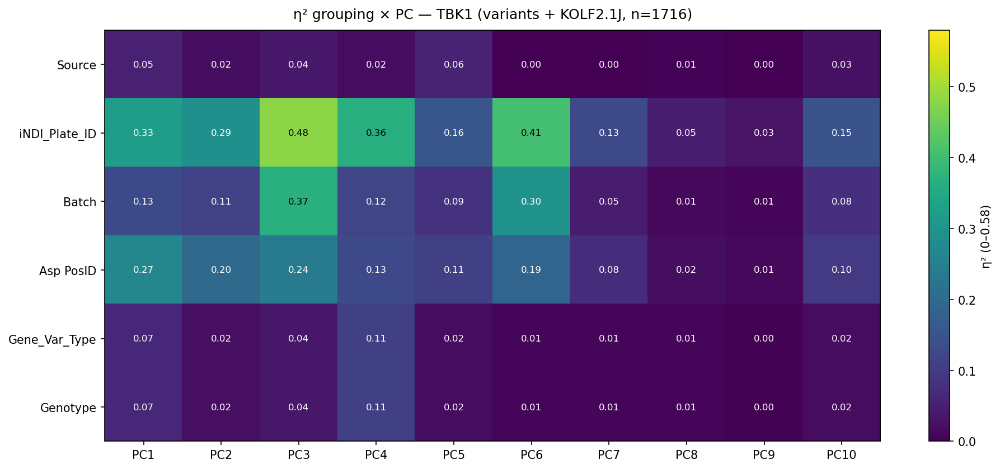

  TIA1: 144 variant + 1448 KOLF rows


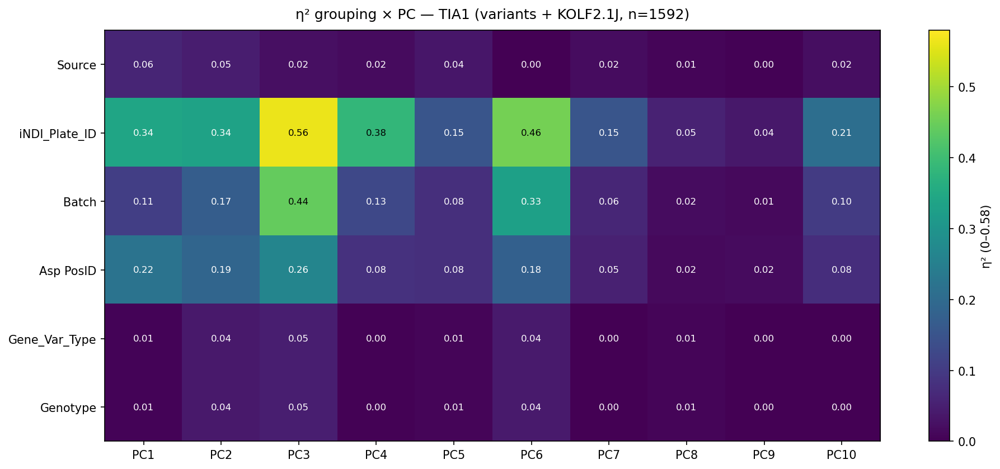

  UBQLN2: 84 variant + 1448 KOLF rows


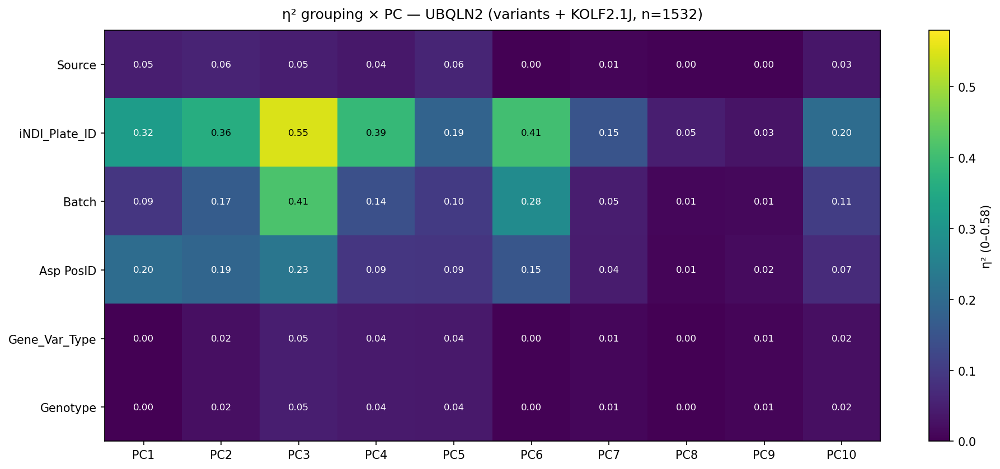

  VCP: 228 variant + 1448 KOLF rows


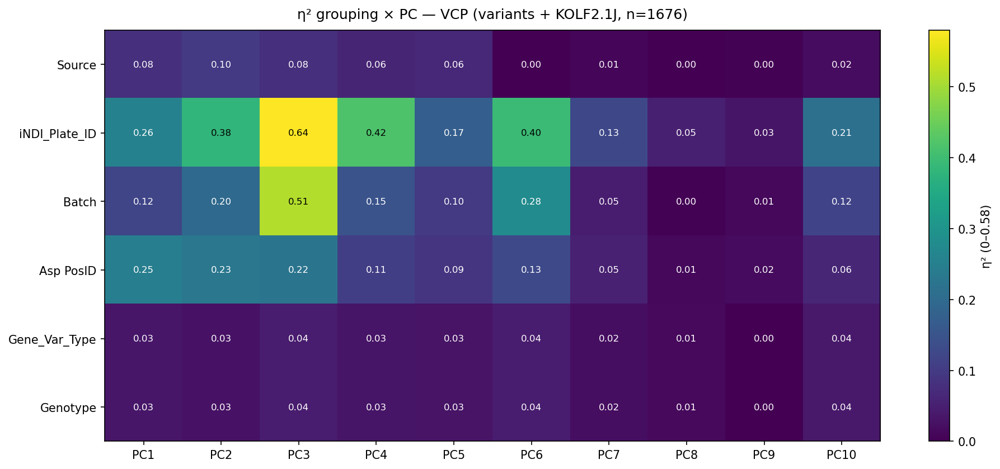

[facet] 16 genes; 1448 total KOLF2.1J rows (plate-matched per facet)
  APOE: 224 variant + 181 KOLF rows on 3 plate(s)


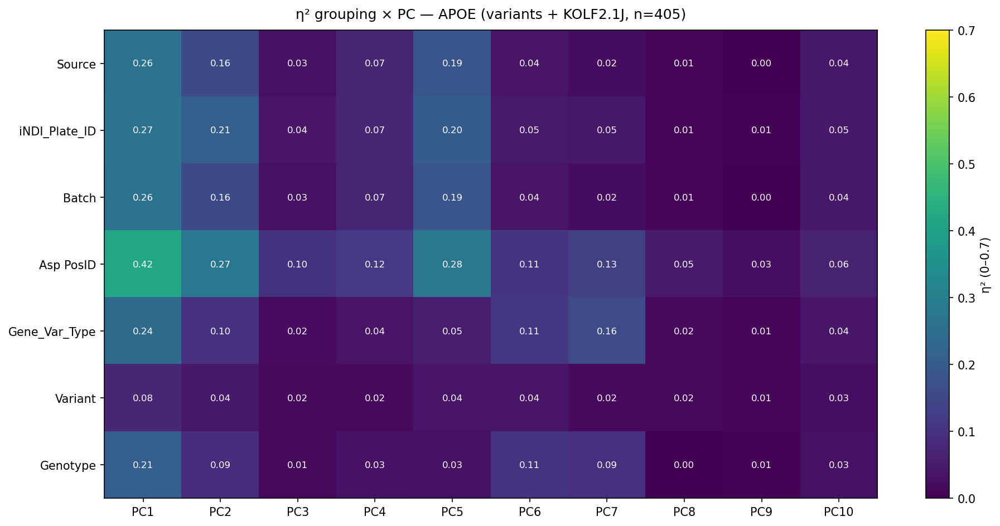

  APP: 572 variant + 337 KOLF rows on 5 plate(s)


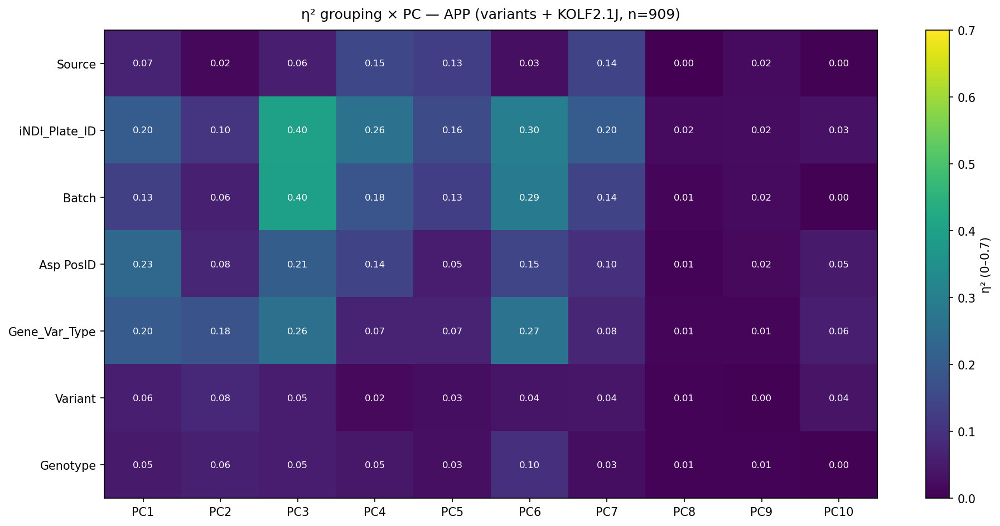

  FUS: 481 variant + 426 KOLF rows on 6 plate(s)


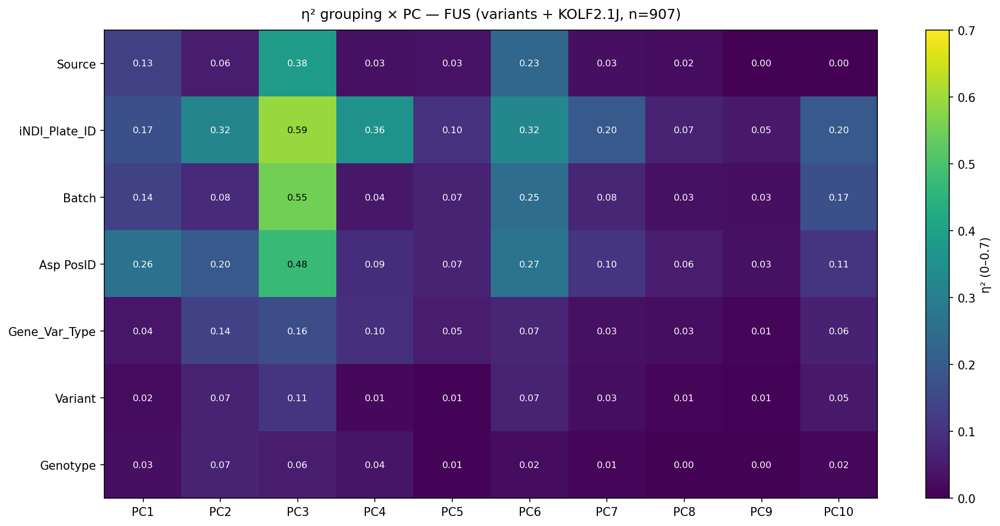

  GRN: 260 variant + 224 KOLF rows on 4 plate(s)


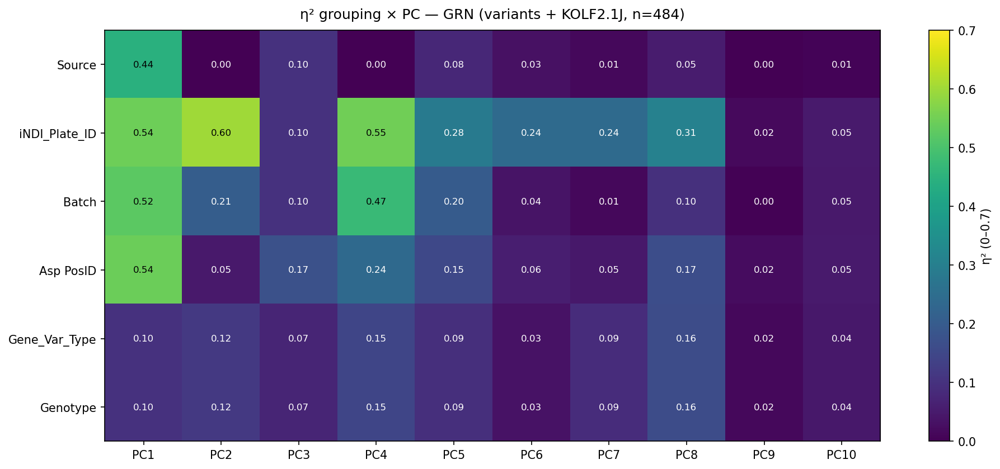

  HNRNPA1: 262 variant + 152 KOLF rows on 3 plate(s)


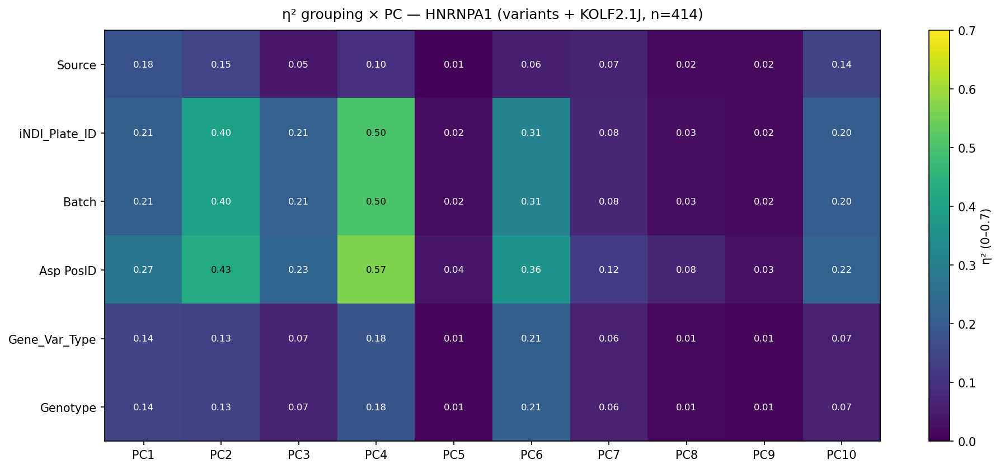

  MAPT: 255 variant + 178 KOLF rows on 3 plate(s)


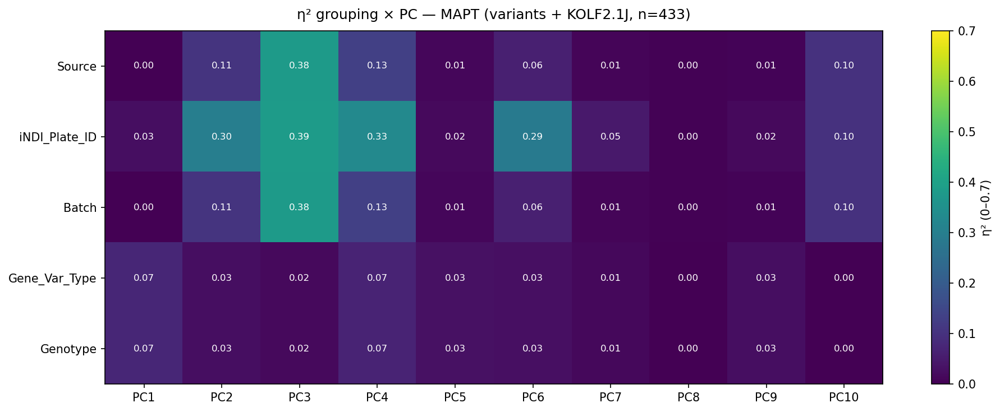

  PFN1: 268 variant + 180 KOLF rows on 3 plate(s)


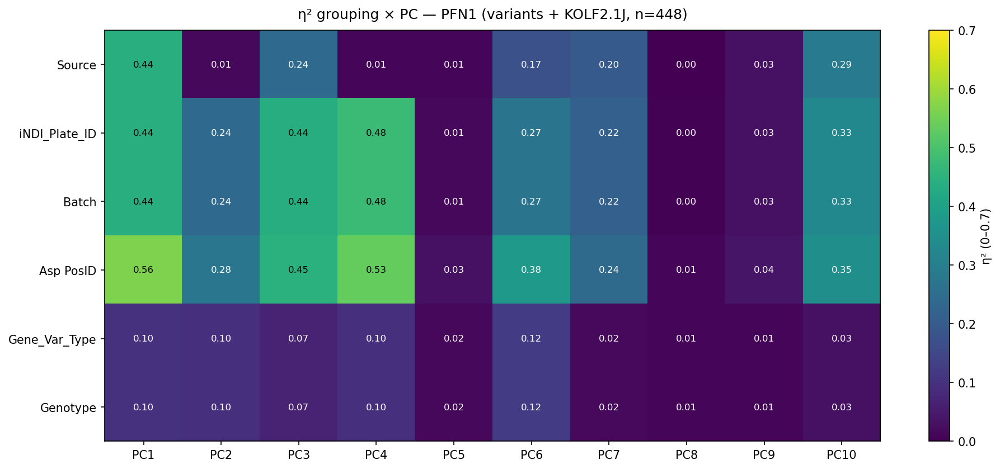

  PSEN1: 95 variant + 191 KOLF rows on 2 plate(s)


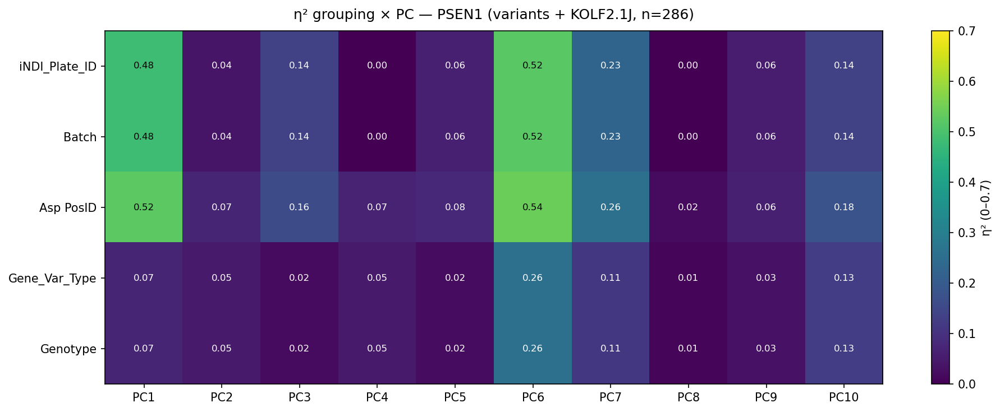

  PSEN2: 222 variant + 205 KOLF rows on 3 plate(s)


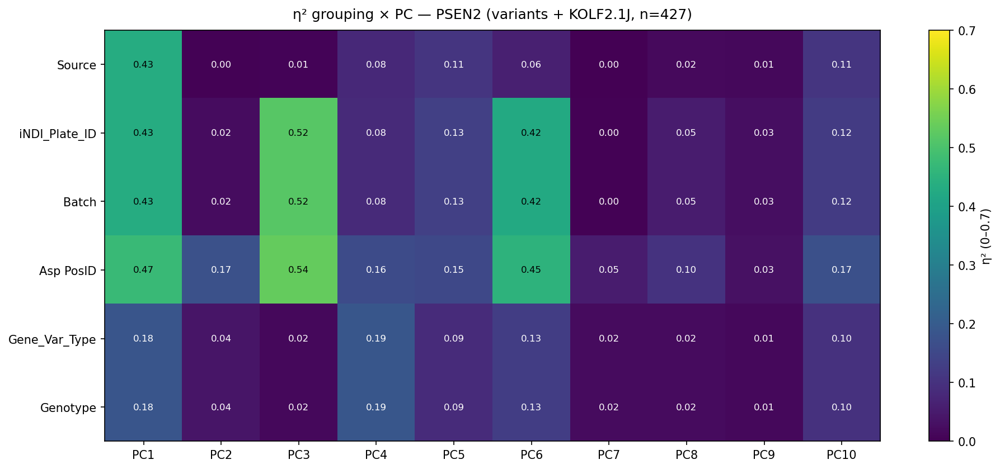

  SNCA: 318 variant + 258 KOLF rows on 4 plate(s)


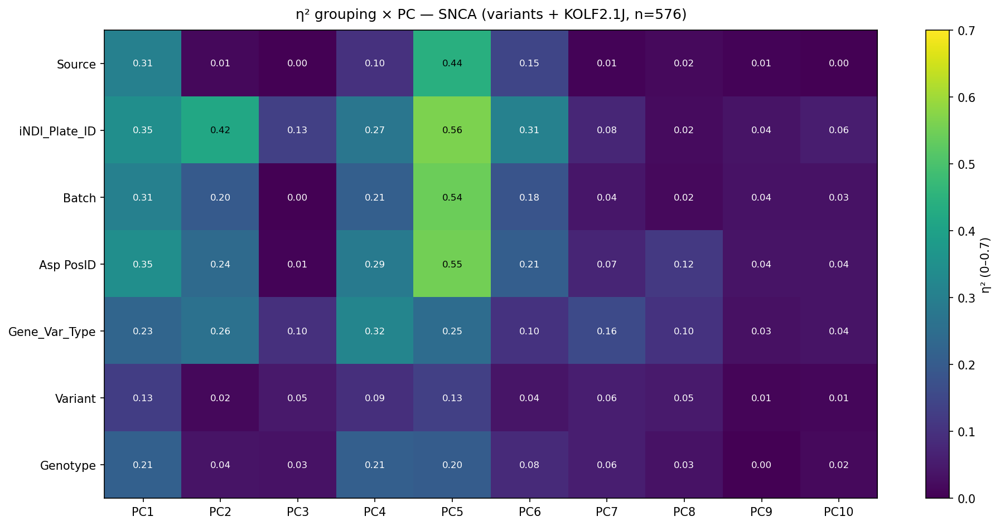

  SNCB: 222 variant + 138 KOLF rows on 2 plate(s)


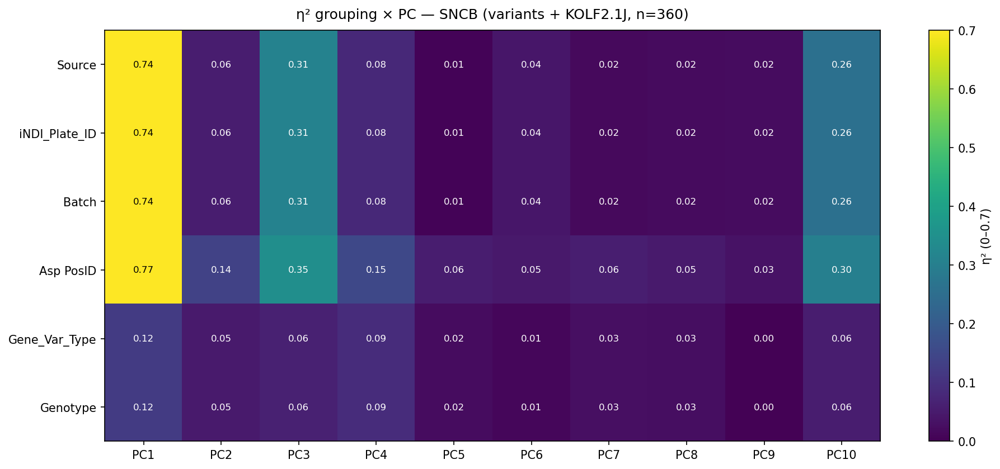

  TARDBP: 539 variant + 360 KOLF rows on 6 plate(s)


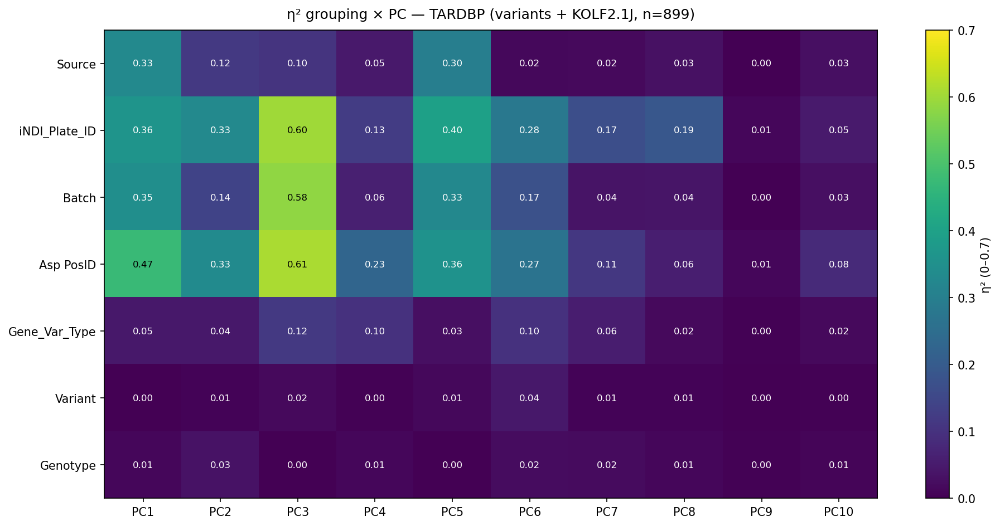

  TBK1: 268 variant + 180 KOLF rows on 3 plate(s)


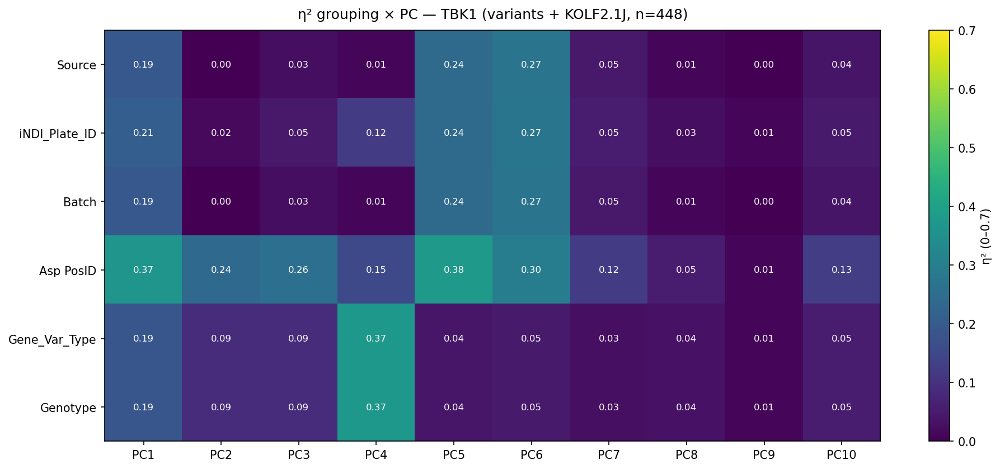

  TIA1: 144 variant + 192 KOLF rows on 2 plate(s)


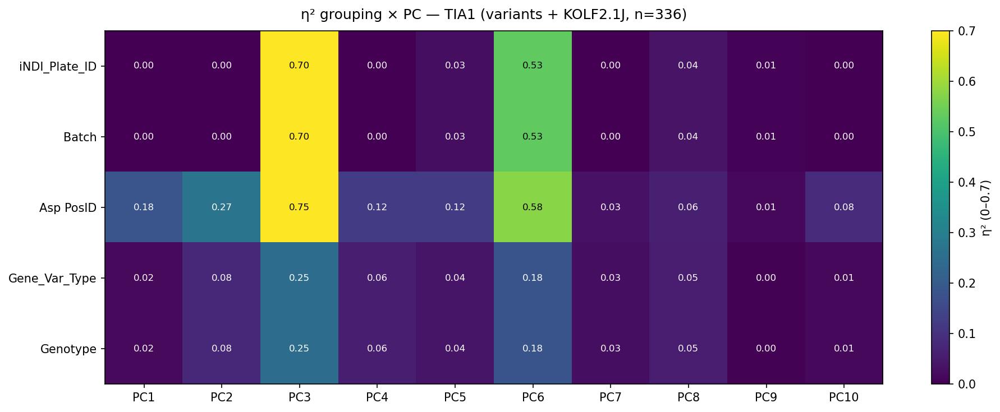

  UBQLN2: 84 variant + 42 KOLF rows on 1 plate(s)


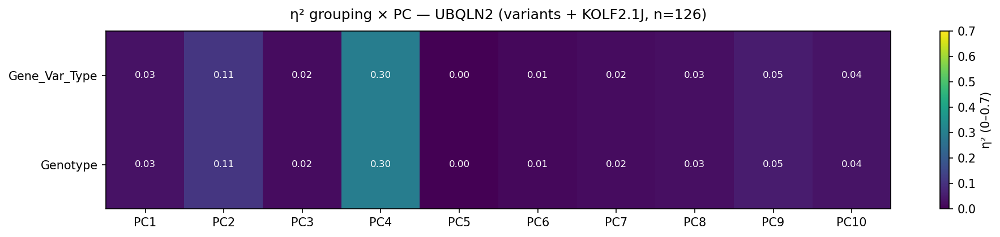

  VCP: 228 variant + 123 KOLF rows on 2 plate(s)


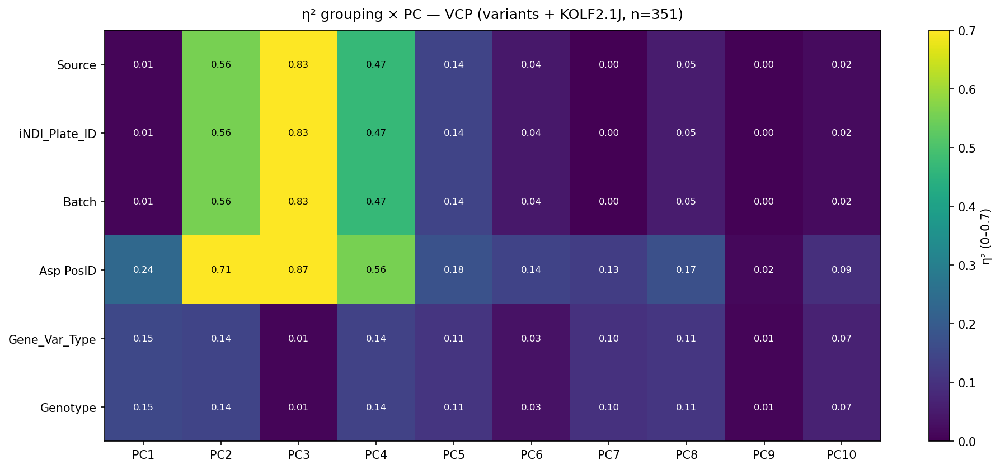

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene: ONE SEPARATE FIGURE per gene --------------------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, vmax=0.2, annot=True,
                      drop_constant=True):
    """Draw a single grouping x PC η² heatmap for one gene's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} (variants + KOLF2.1J, n={len(sub)})",
                 pad=10)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene(data, group_cols, n_pcs=10,
                  gene_col="Gene", vmax=0.2, annot=True,
                  include_wt=True, drop_constant=True,
                  plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per gene. Each gene's subset is that
    gene's variant rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that gene's variants actually occupy, removing the plate confound
    that arises when controls span all plates but a gene sits on only a few.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]
    genes = sorted(pd.unique(edited[gene_col].dropna()))
    print(f"[facet] {len(genes)} genes; {len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    facet_groups = [g for g in group_cols if g != gene_col]

    mats = {}
    for gene in genes:
        gene_rows = edited[edited[gene_col] == gene]
        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                gene_plates = set(gene_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(gene_plates)]
            sub = pd.concat([gene_rows, wt_use], ignore_index=True)
            print(f"  {gene}: {len(gene_rows)} variant + {len(wt_use)} KOLF rows"
                  f"{f' on {len(set(gene_rows[plate_col].dropna().unique()))} plate(s)' if plate_match else ''}")
        else:
            sub = gene_rows
        mats[gene] = plot_gene_heatmap(sub, facet_groups, pc_cols, gene,
                                       vmax=vmax, annot=annot,
                                       drop_constant=drop_constant)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene(well_level, GROUP_COLS, n_pcs=10, vmax=0.58, plate_match=False)
mats = facet_by_gene(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

### Genotype faceted PCAs


MANUAL (2196 wells)


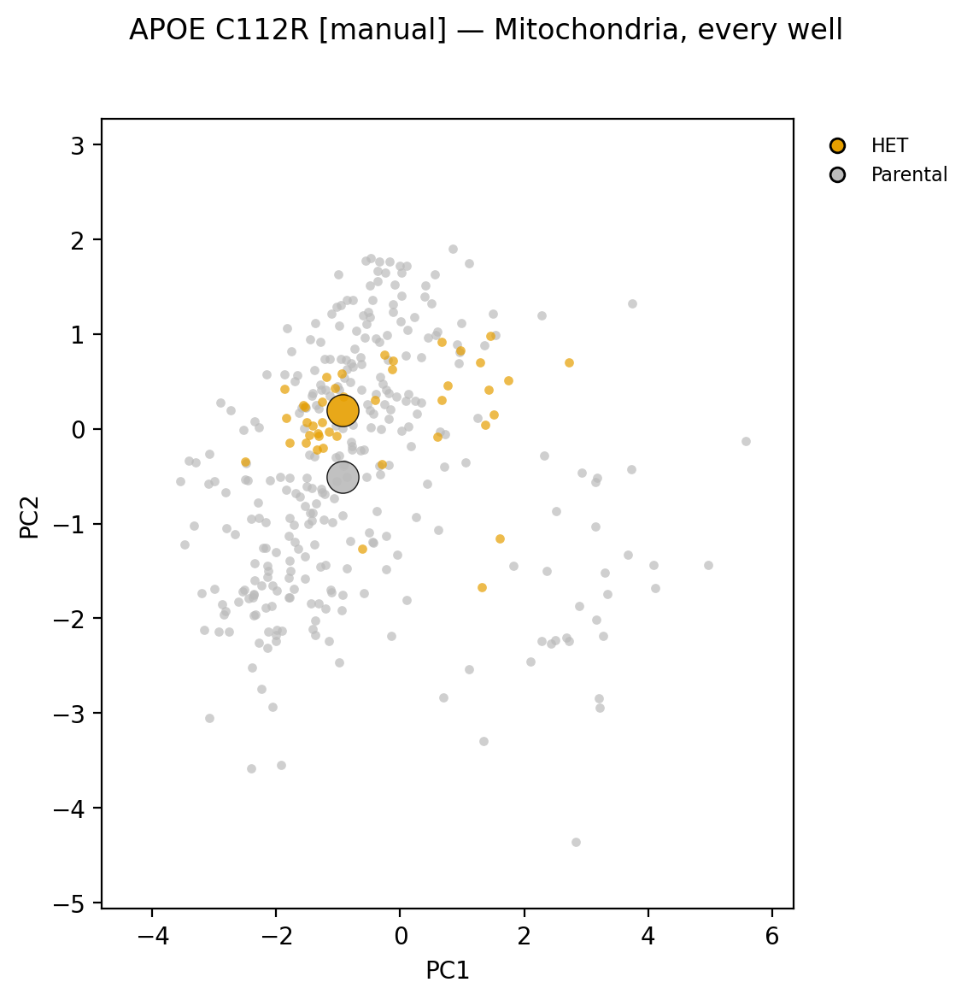

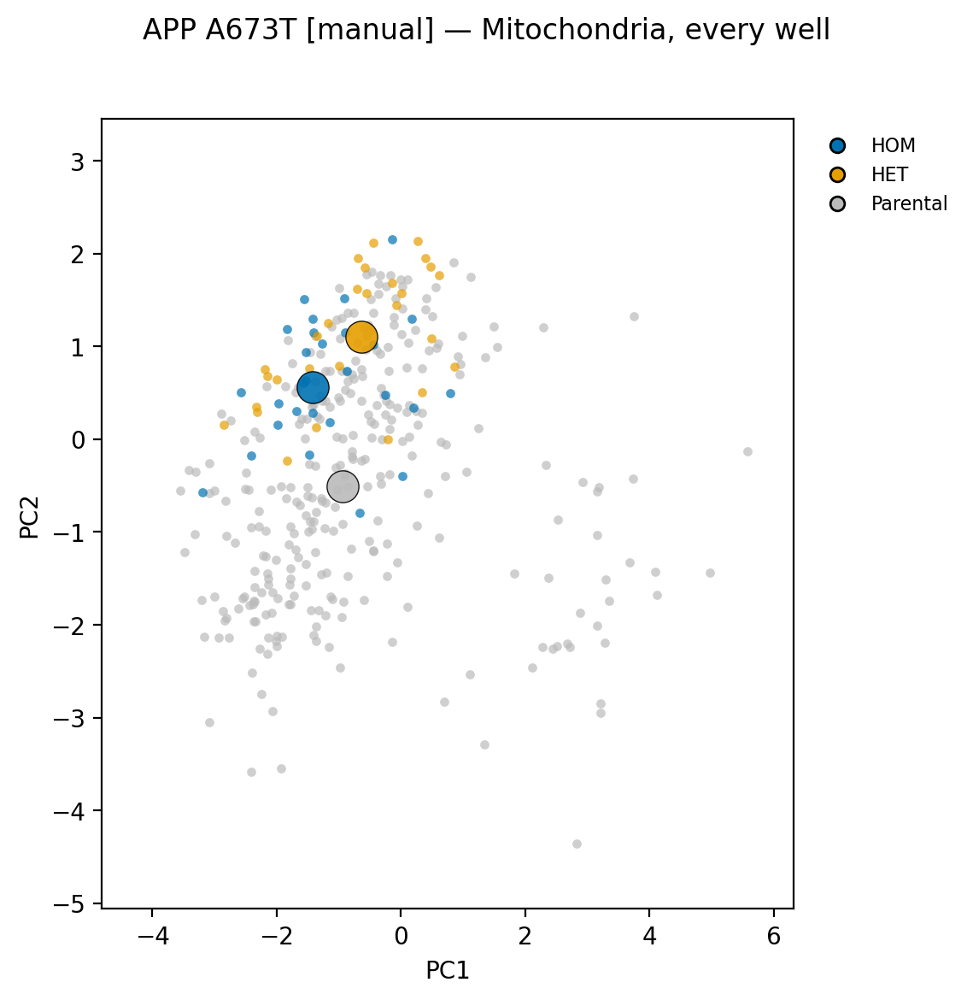

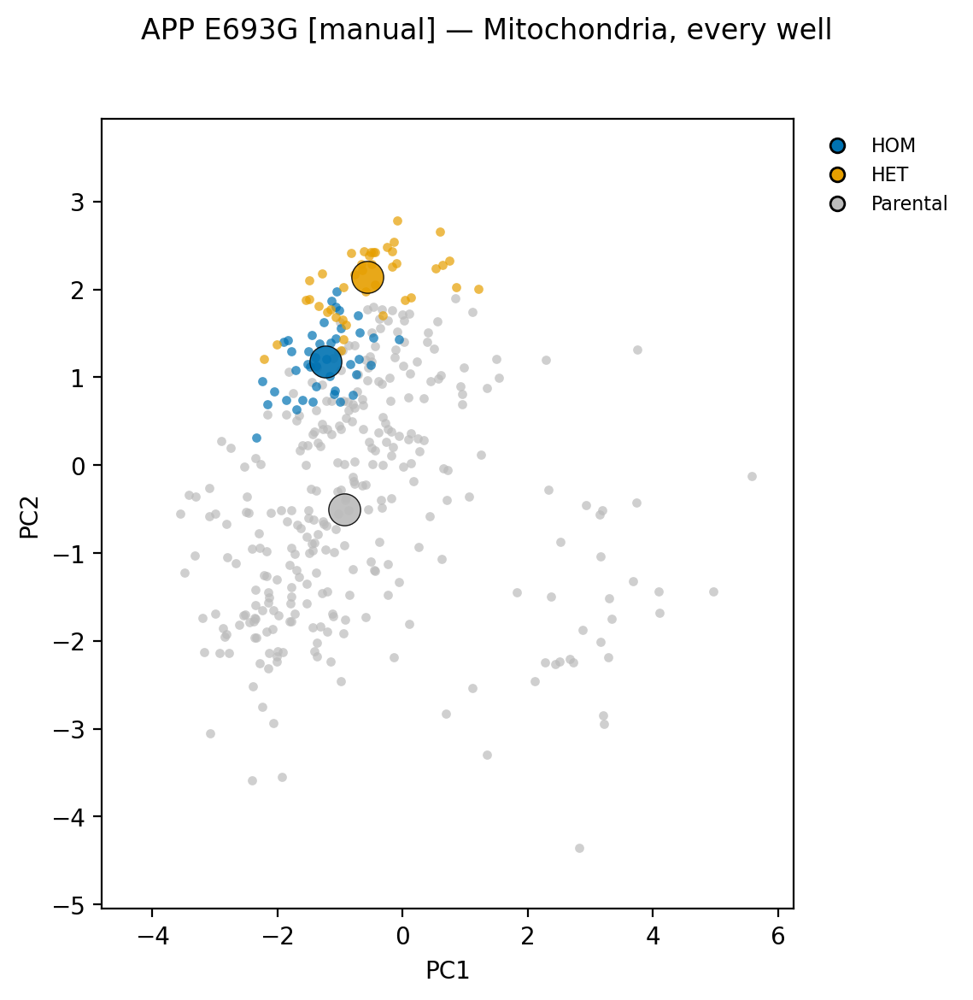

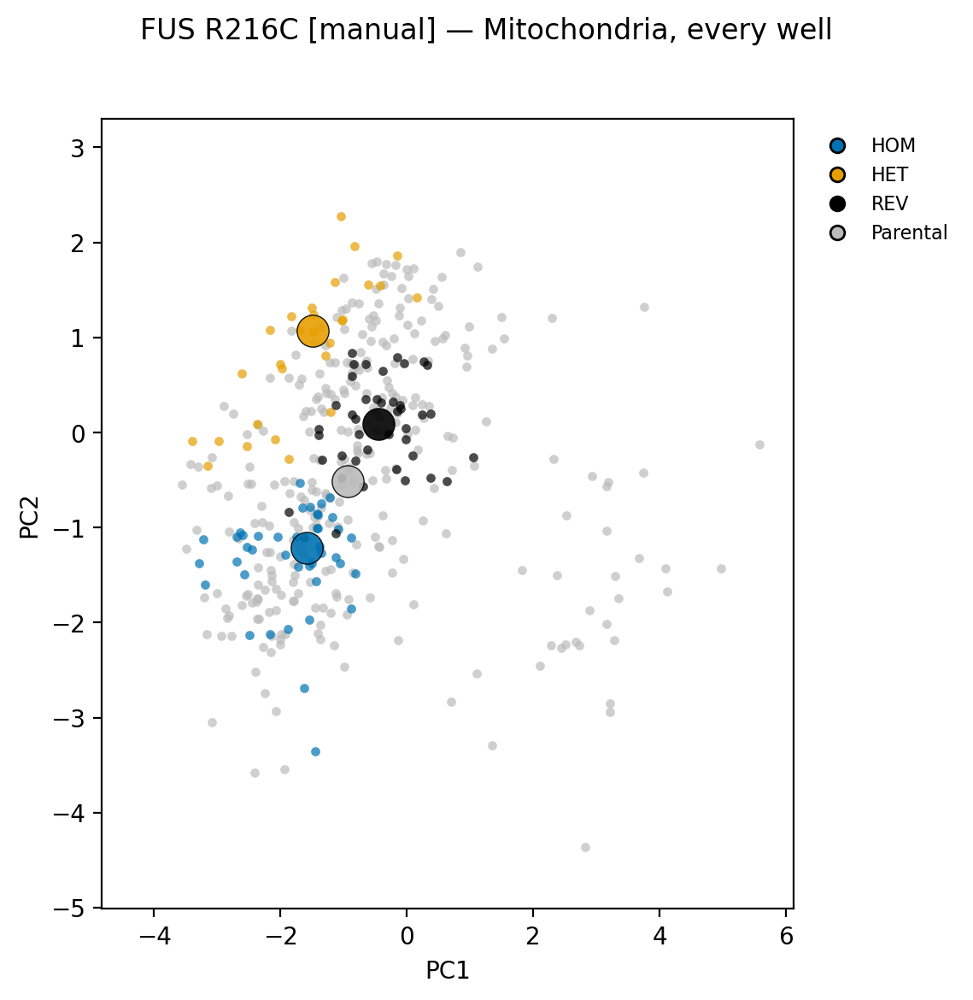

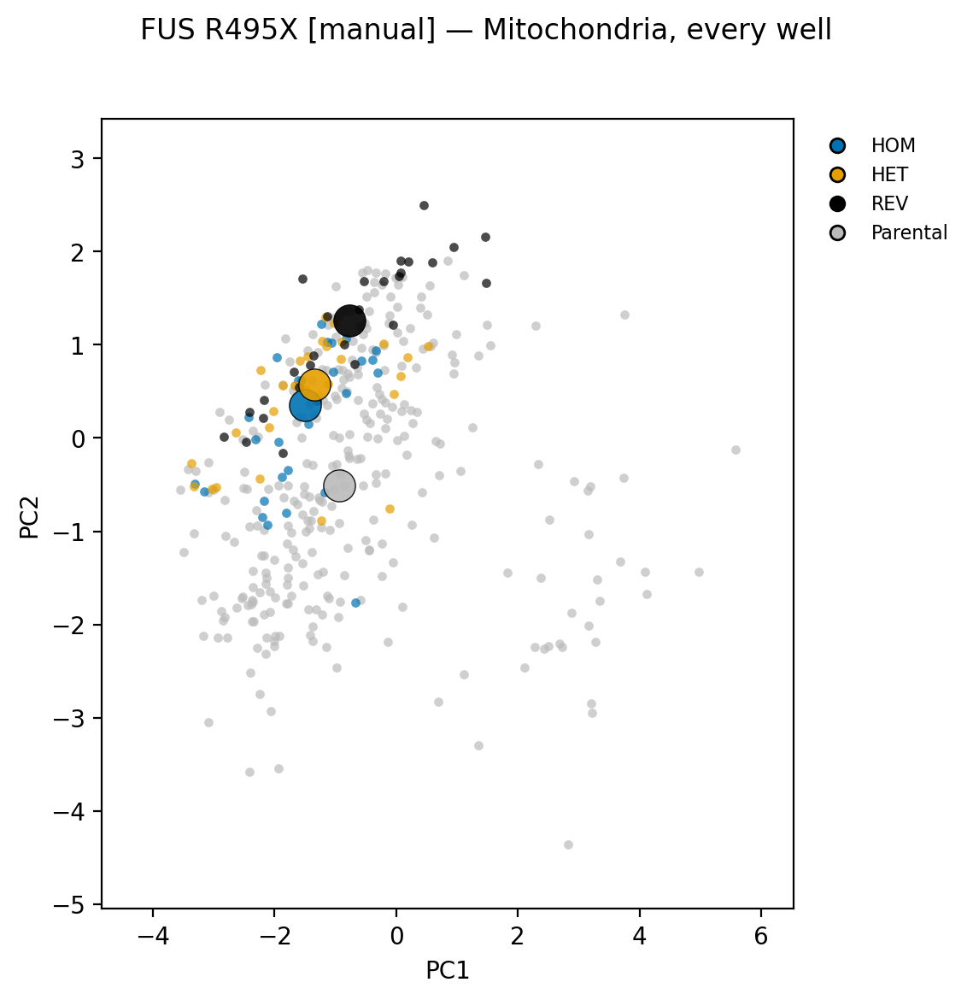

...

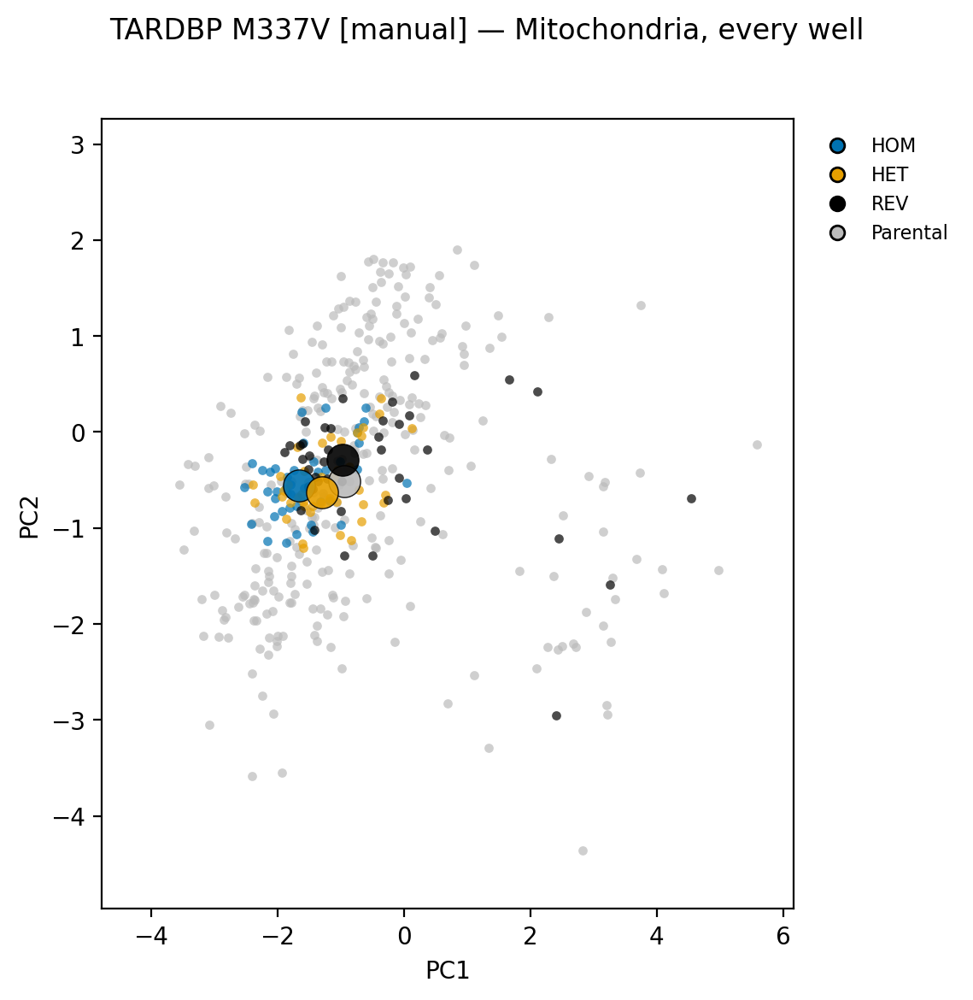

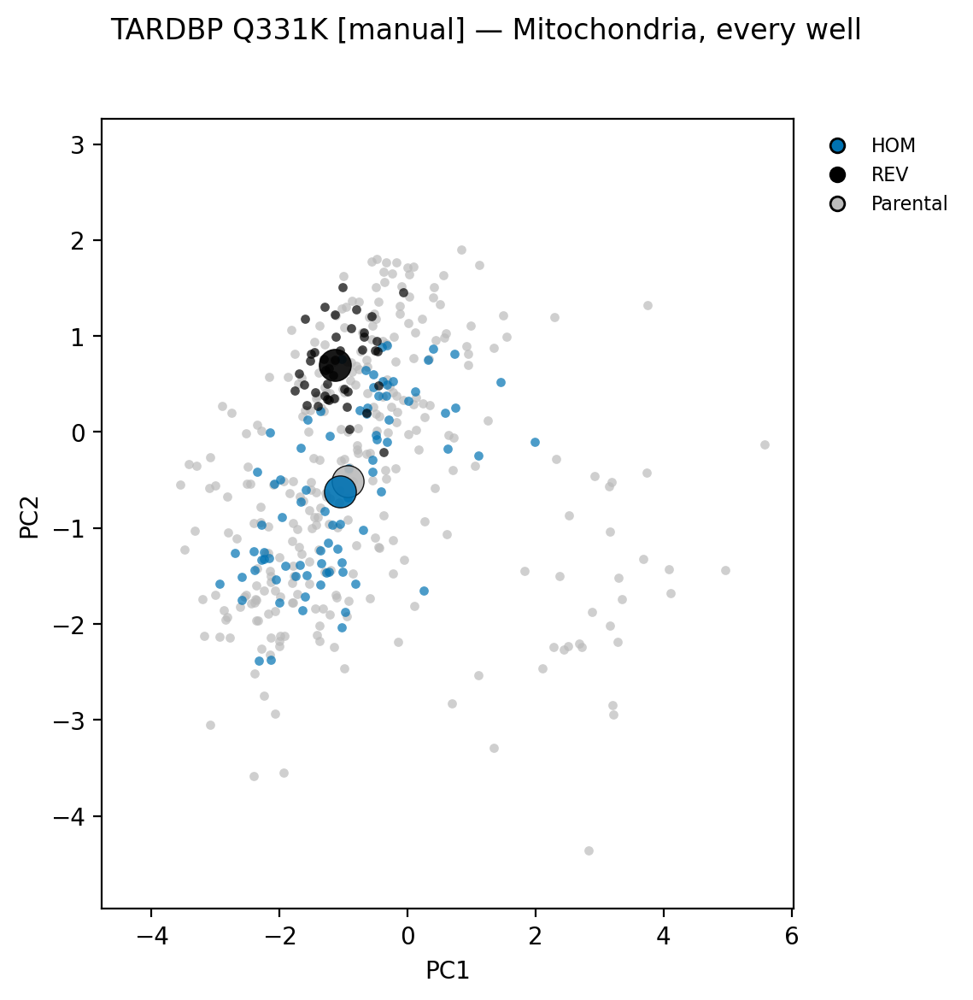

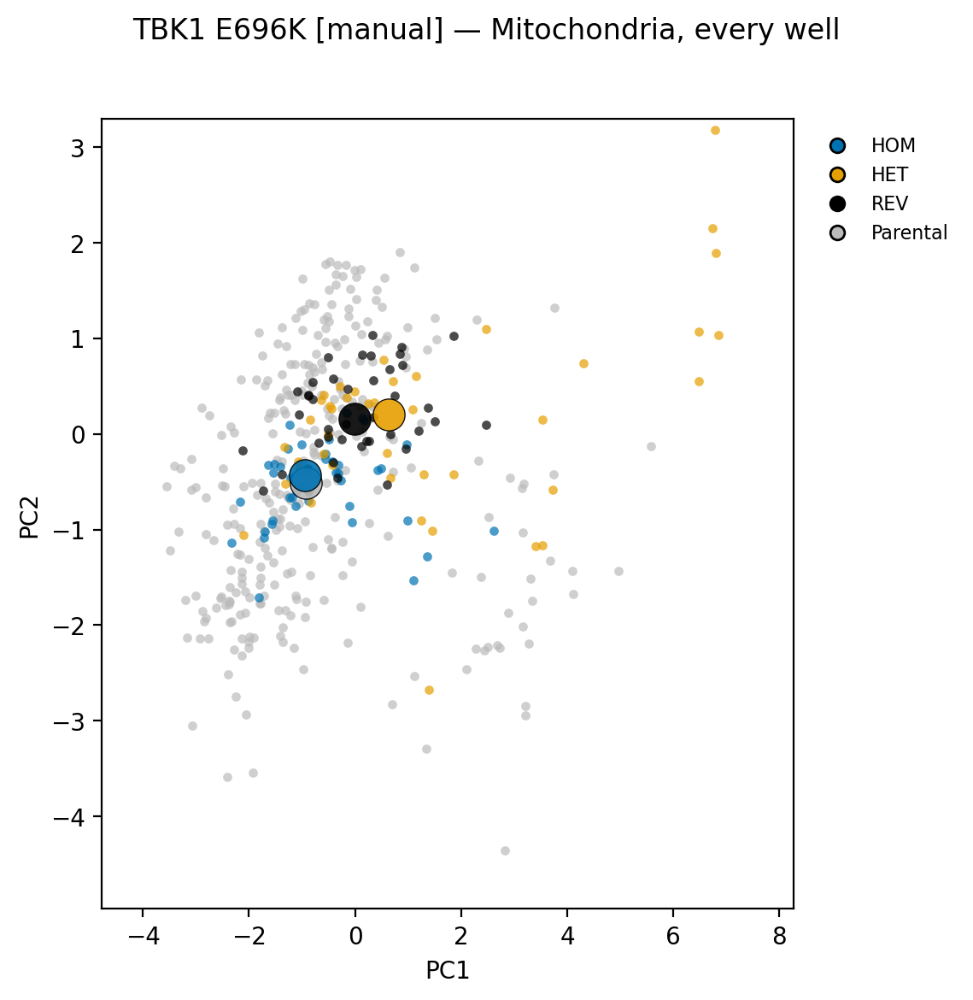

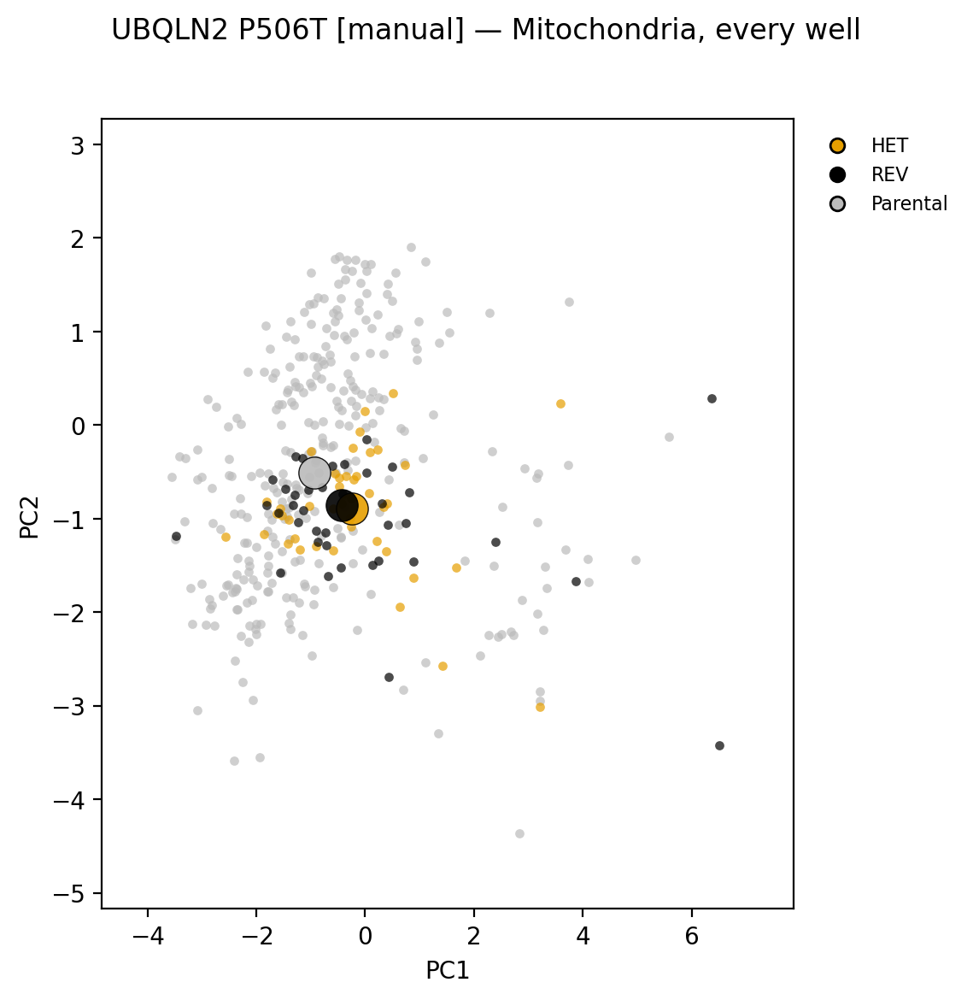

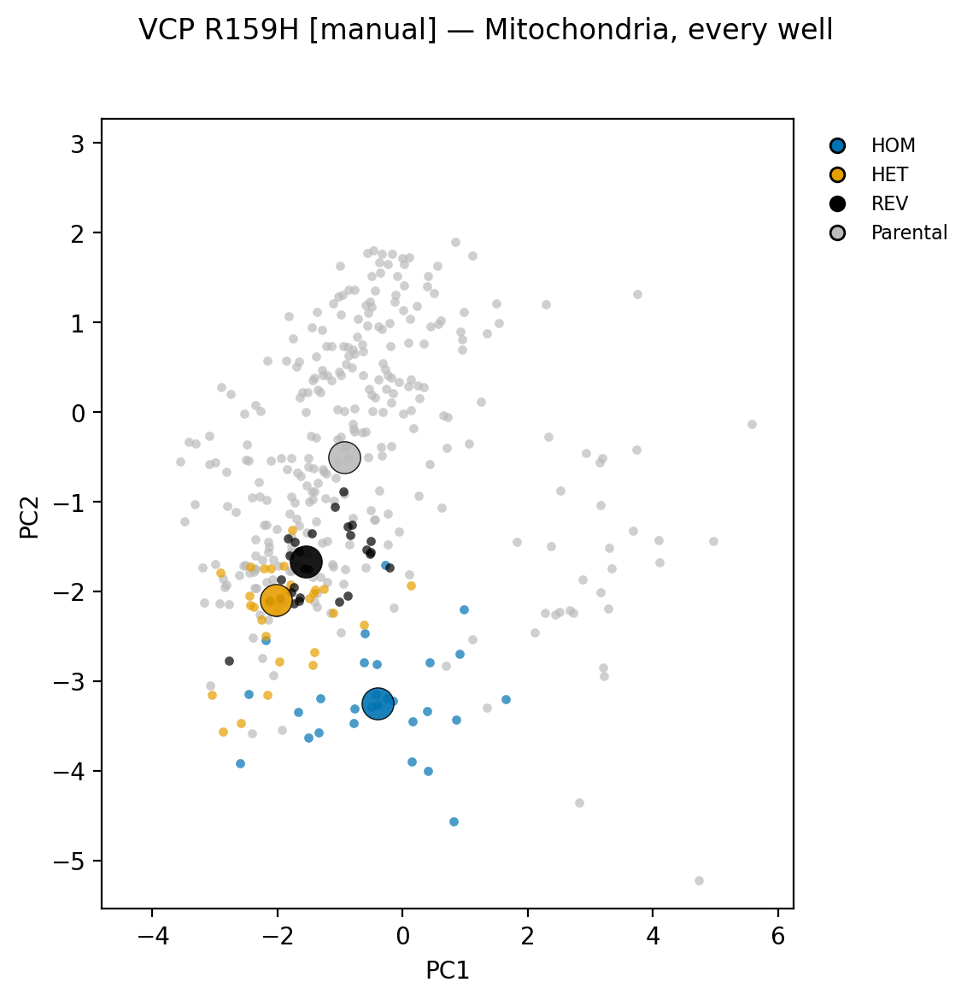


AUTOMATED (3740 wells)


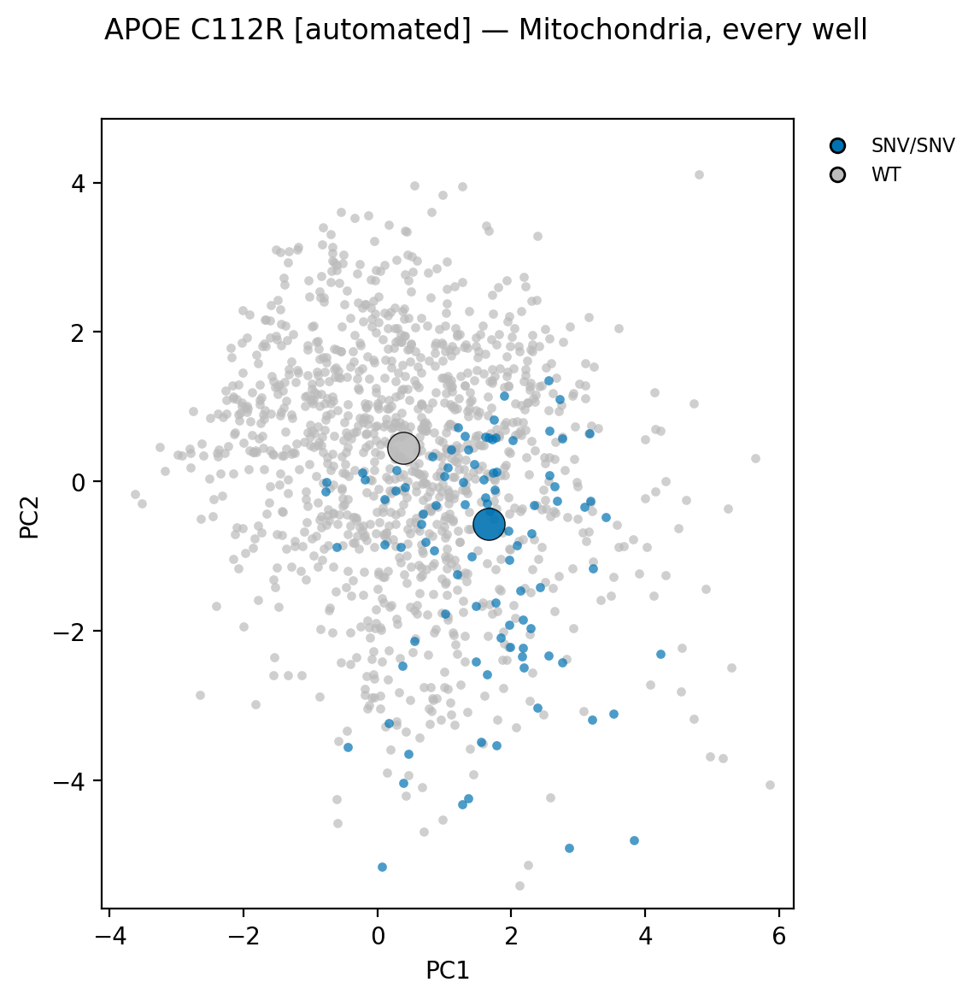

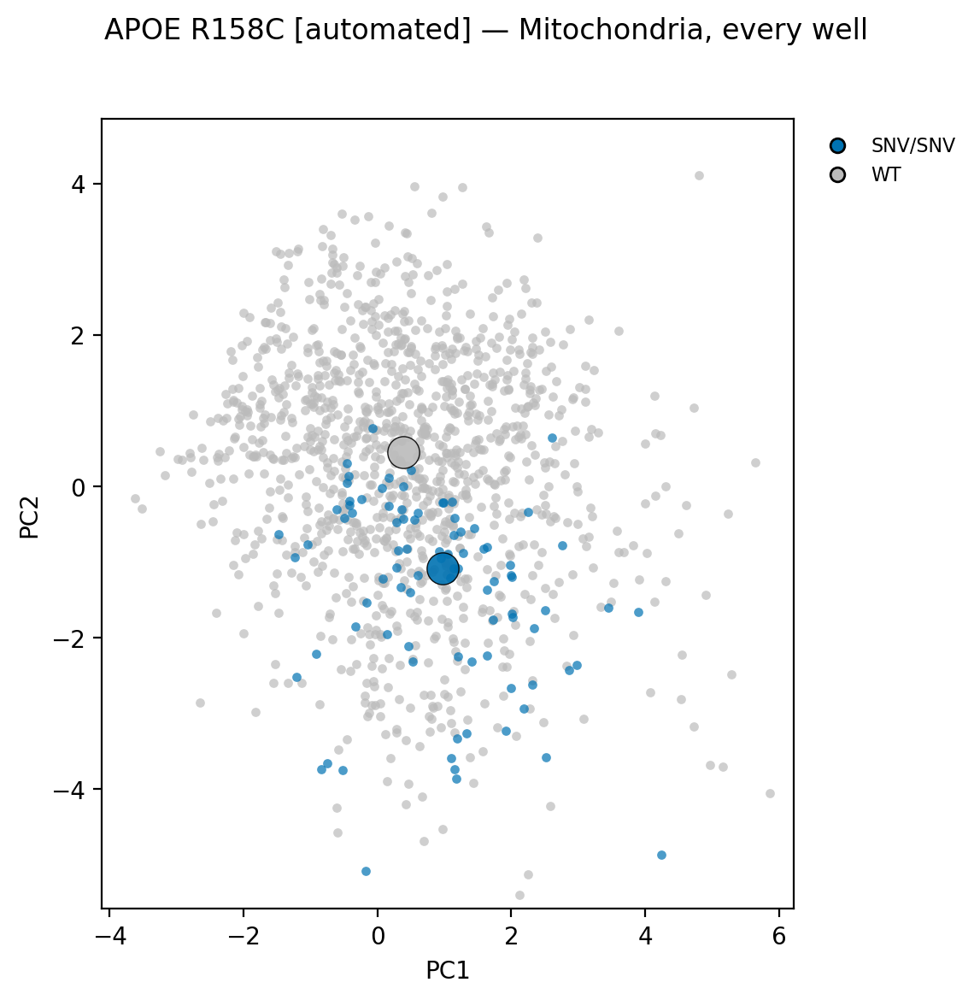

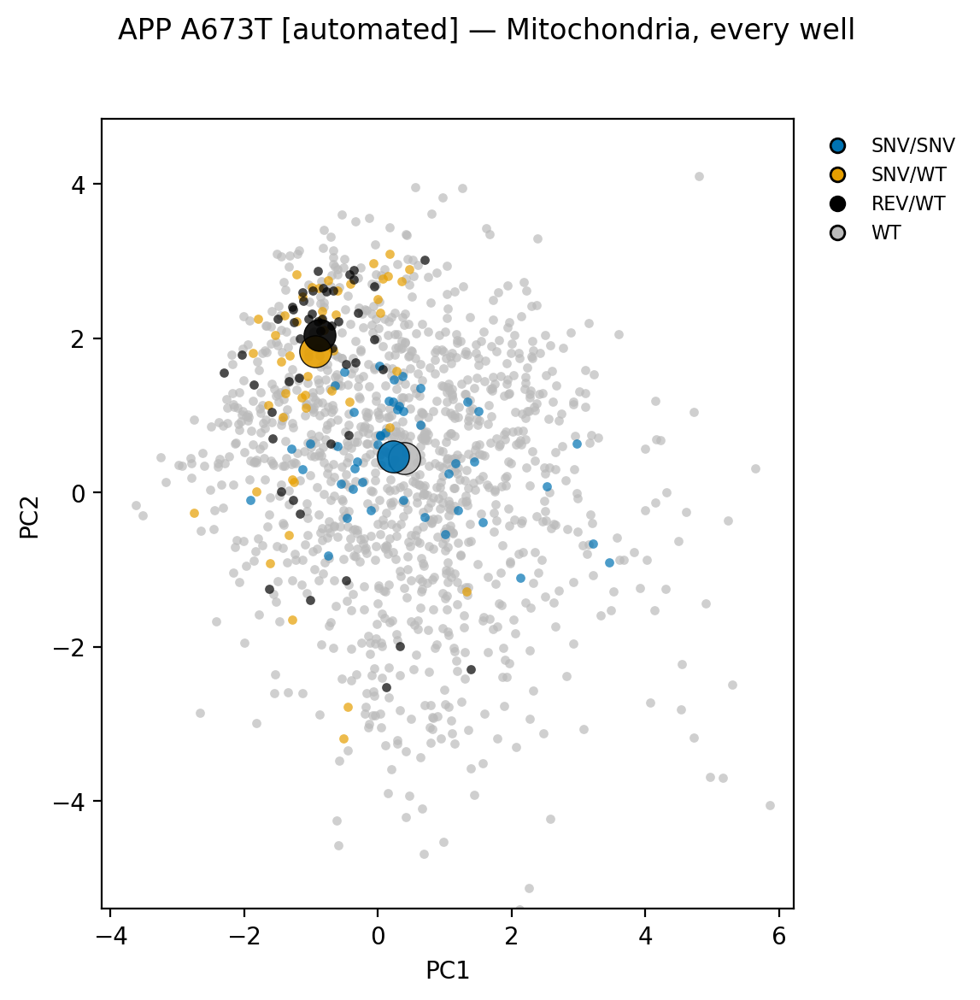

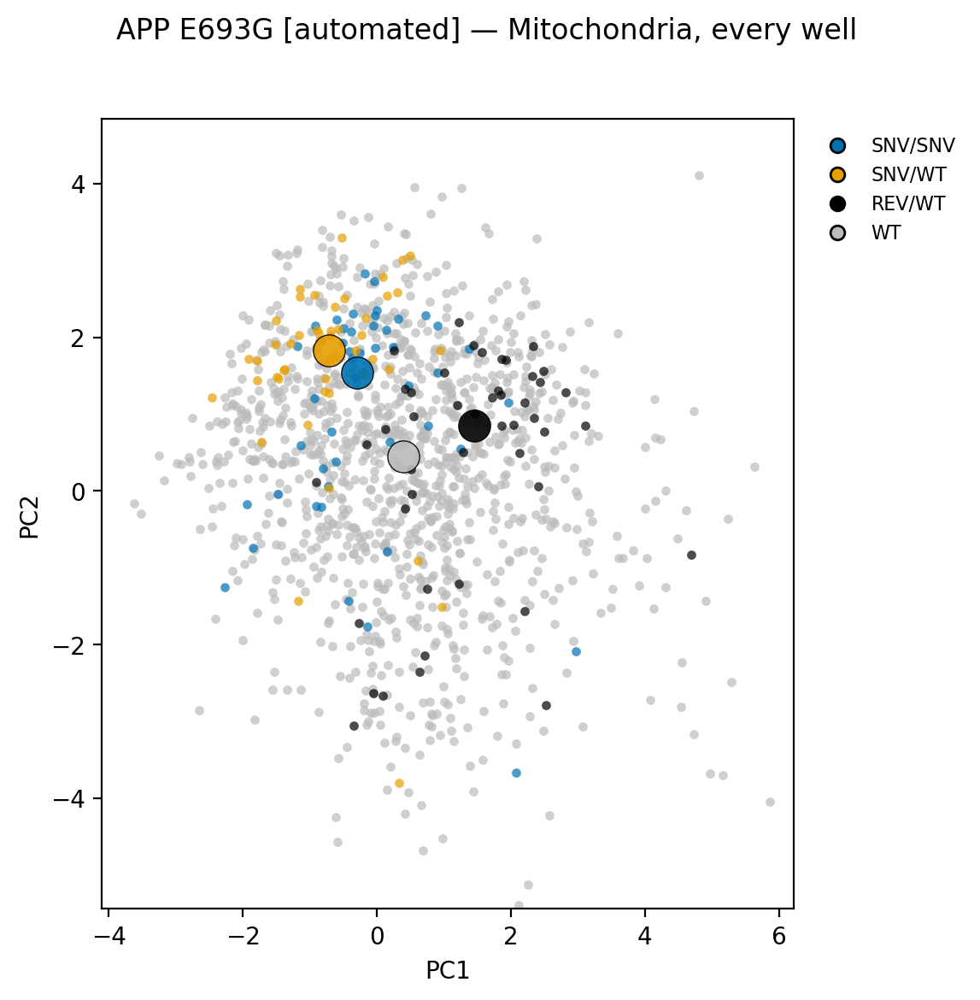

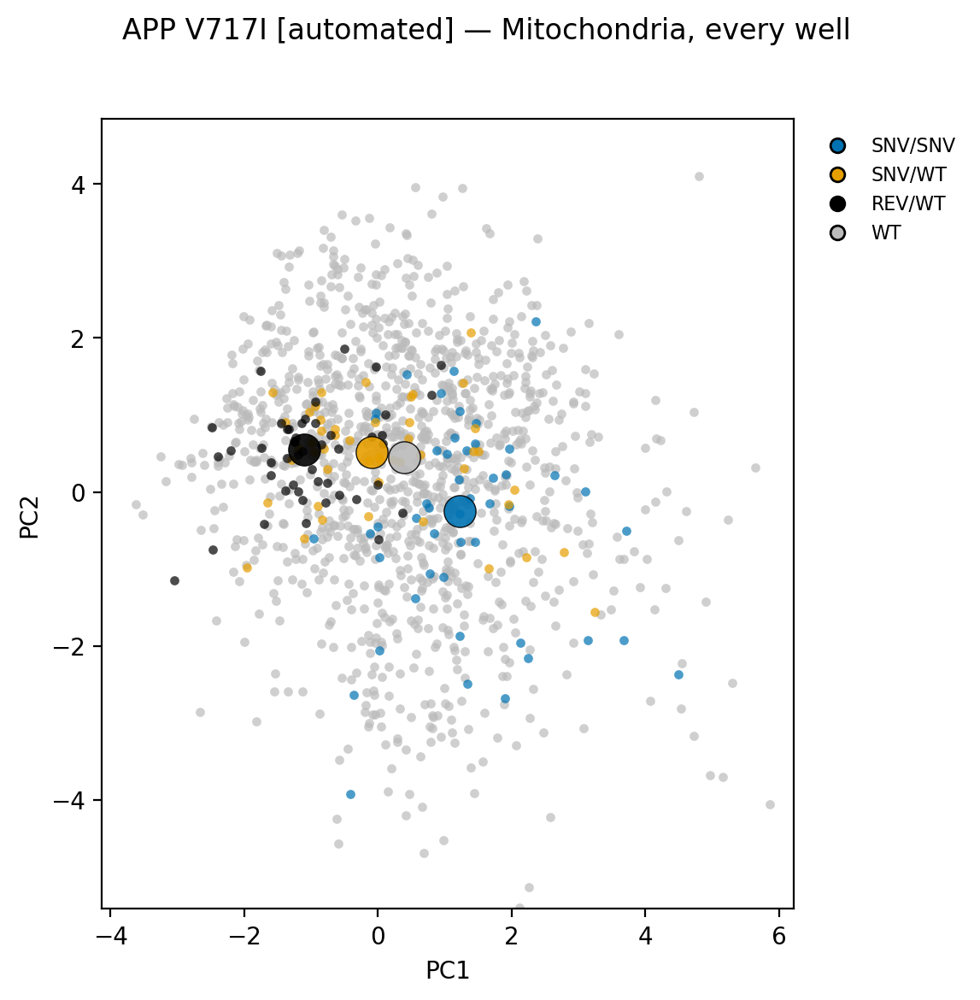

...

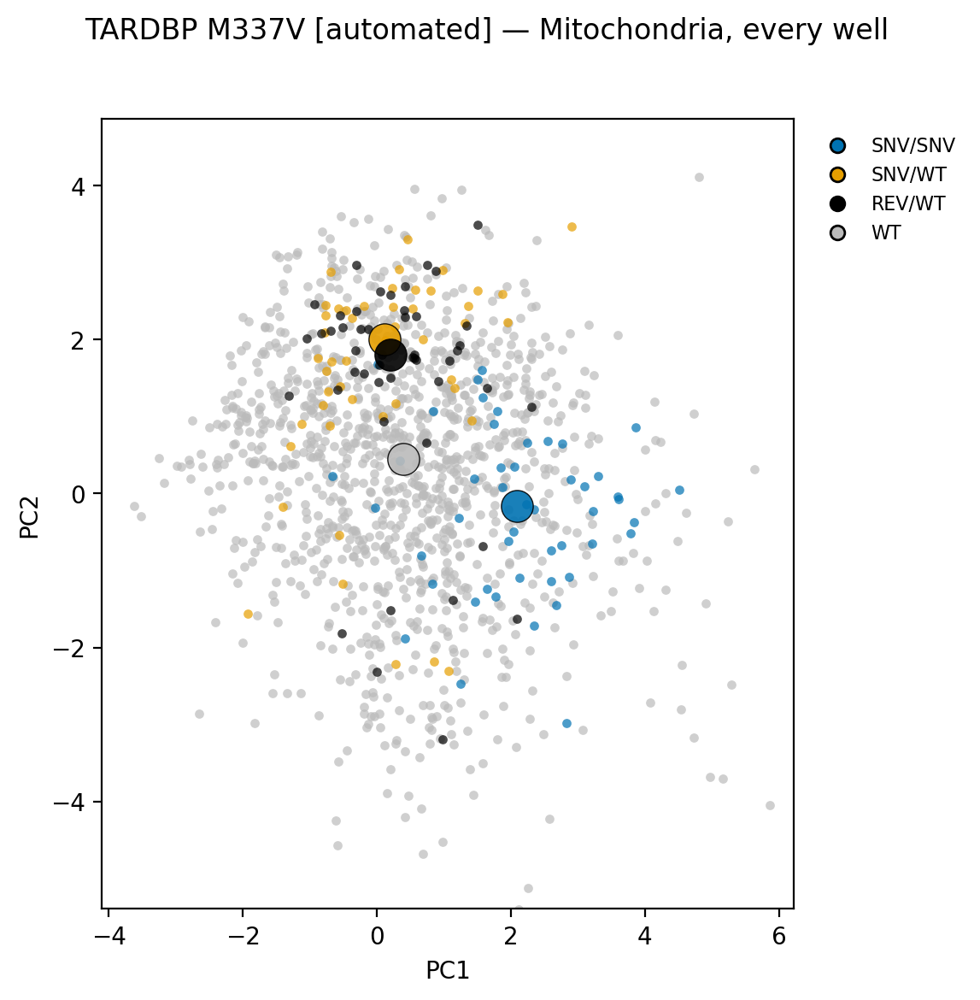

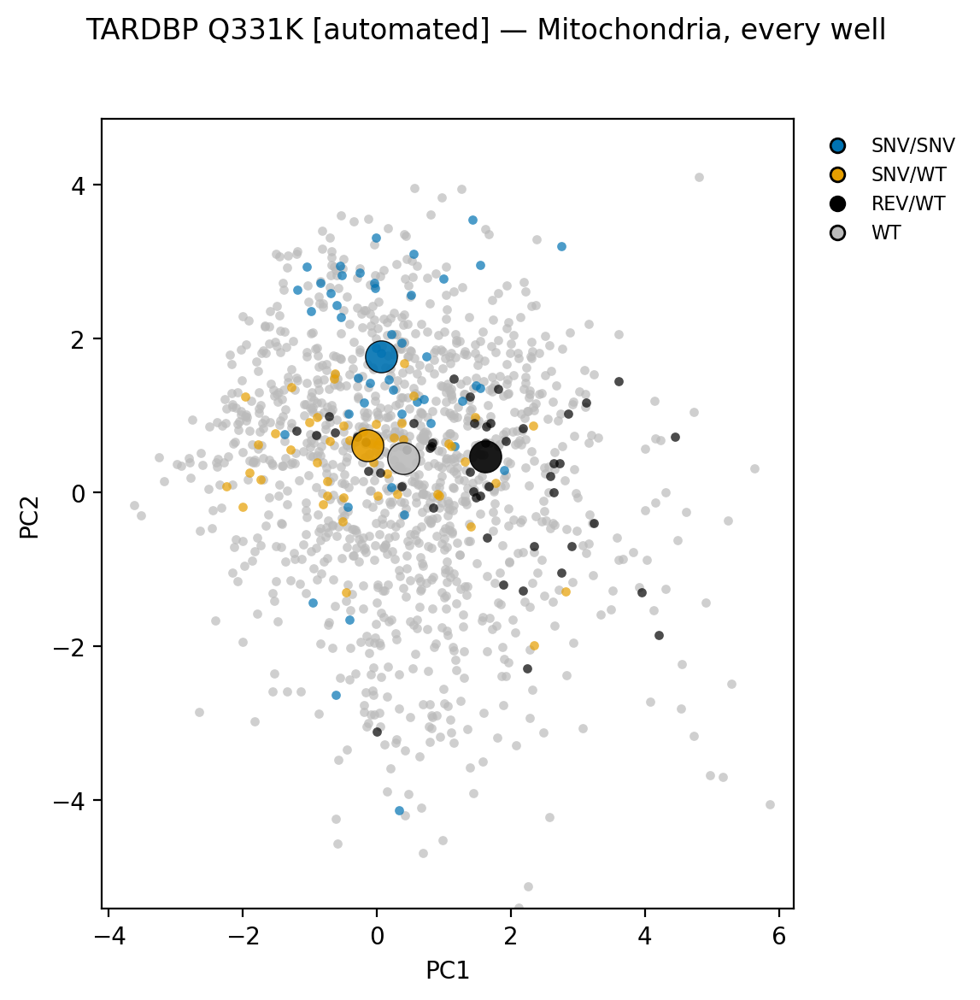

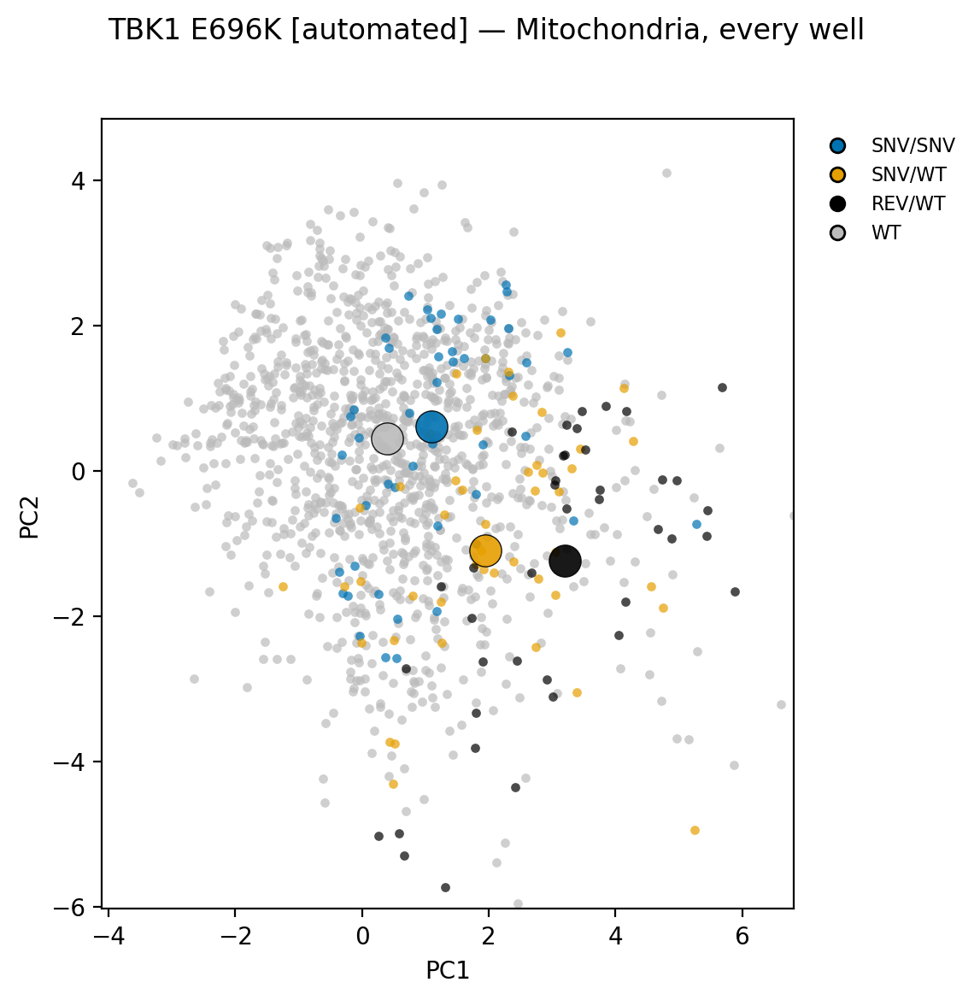

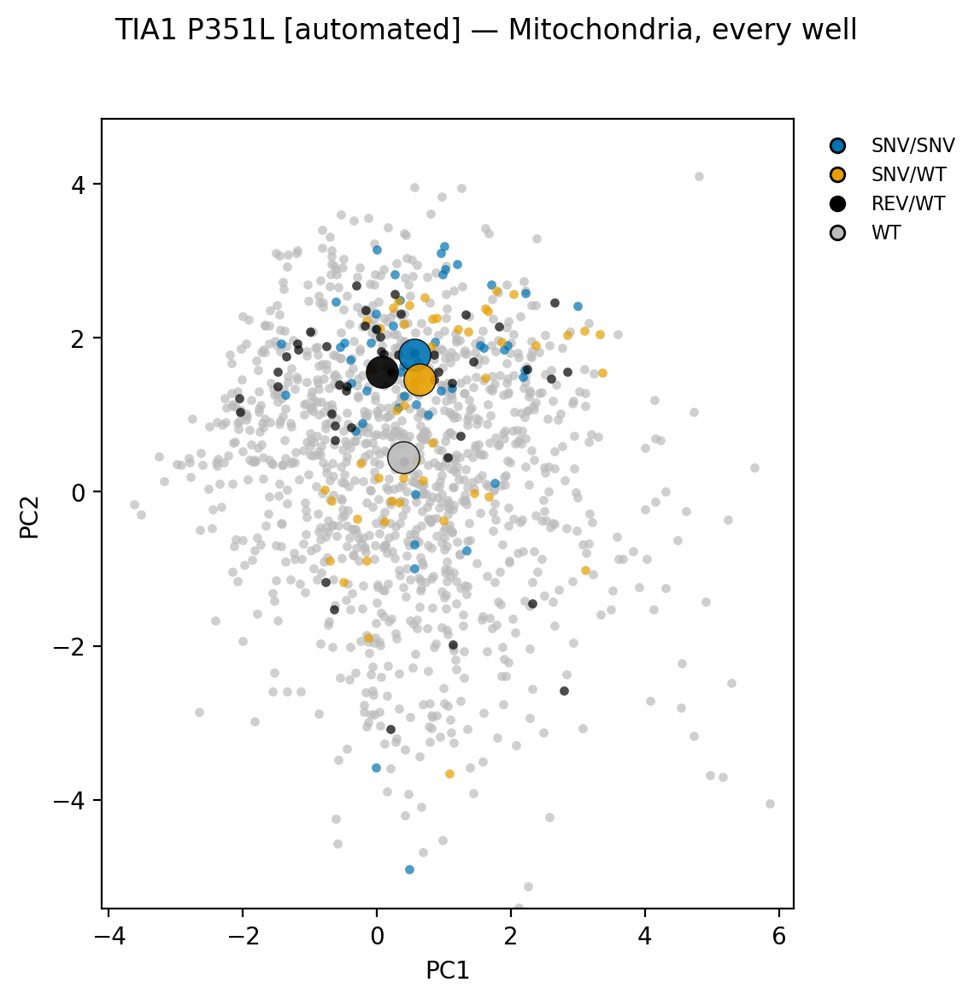

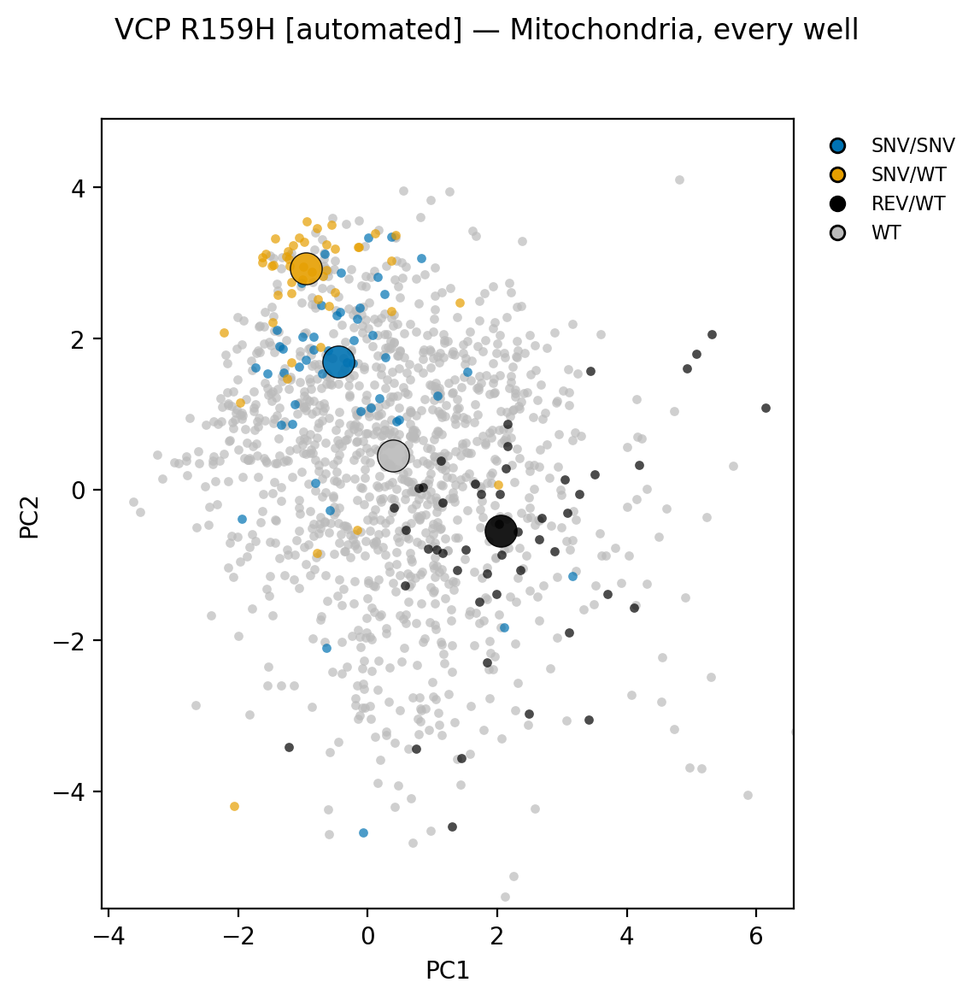

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================================
# Prep split
# ==========================================================================
PREP_COL = "Source"          # column tagging each well's prep
AUTOMATED_VAL = "automated"
MANUAL_VAL = "manual"

# ==========================================================================
# Group-specific schemes
# ==========================================================================
# --- Manual: parental by Genotype_Name == "Parental"; genotype is the trailing
#     token of Genotype_Name (HOM / HET / REV). -----------------------------
MANUAL_PARENTAL_NAME = "Parental"
MANUAL_COLORS = {
    "Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
    "REV": "#000000", "OTHER": "#F0E442",
}
MANUAL_ORDER = ["HOM", "HET", "REV", "Parental"]
MANUAL_PARENTAL_KEY = "Parental"

def _manual_is_parental(df):
    return (df["Genotype_Name"].astype(str).str.strip().str.upper()
            == MANUAL_PARENTAL_NAME.upper())

def _manual_color_key(df):
    name = df["Genotype_Name"].astype(str).str.strip()
    zyg = name.str.split().str[-1].str.upper()        # HOM / HET / REV
    return np.where(_manual_is_parental(df), MANUAL_PARENTAL_KEY, zyg)

def _manual_has_mutant(nonpar_keys):
    return nonpar_keys.isin(["HOM", "HET"]).any()

# --- Automated: parental by Gene == "KOLF2.1J"; genotype from the Genotype
#     column (SNV/SNV, SNV/WT, SNV/Y, ...). ---------------------------------
AUTO_WT_GENE = "KOLF2.1J"
AUTO_COLORS = {
    "WT": "#BBBBBB", "SNV/WT": "#E69F00", "SNV/SNV": "#0072B2",
    "REV/WT": "#000000", "SNV/Y": "#009E73", "REV/Y": "#CC79A7",
    "OTHER": "#F0E442",
}
AUTO_ORDER = ["SNV/SNV", "SNV/WT", "SNV/Y", "REV/WT", "REV/Y", "WT"]
AUTO_PARENTAL_KEY = "WT"

def _auto_is_parental(df):
    return (df["Gene"].astype(str).str.strip().str.upper()
            == AUTO_WT_GENE.upper())

def _auto_color_key(df):
    return np.where(_auto_is_parental(df), AUTO_PARENTAL_KEY,
                    df["Genotype"].astype(str).str.strip())

def _auto_has_mutant(nonwt_keys):
    return nonwt_keys.str.startswith("SNV").any()

SCHEMES = {
    "manual": {
        "label": "manual", "is_parental": _manual_is_parental,
        "color_key": _manual_color_key, "colors": MANUAL_COLORS,
        "order": MANUAL_ORDER, "parental_key": MANUAL_PARENTAL_KEY,
        "has_mutant": _manual_has_mutant,
    },
    "automated": {
        "label": "automated", "is_parental": _auto_is_parental,
        "color_key": _auto_color_key, "colors": AUTO_COLORS,
        "order": AUTO_ORDER, "parental_key": AUTO_PARENTAL_KEY,
        "has_mutant": _auto_has_mutant,
    },
}


# ==========================================================================
# Figure: single-panel PCA for one allele (nucleus-level, no faceting)
# ==========================================================================
def variant_pca(
    df, gene, variant, scheme, pcx="PC1", pcy="PC2", title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=(6, 6),
):
    """Single PCA panel for one (gene, variant), using `scheme` for color keys,
    palette, and ordering. `parental` is the pooled parental reference."""
    colors = scheme["colors"]
    order = scheme["order"]
    par_key = scheme["parental_key"]

    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] ({scheme['label']}) no rows for {gene} {variant}")
        return None

    src["_ckey"] = scheme["color_key"](src)

    nonpar = src.loc[src["_ckey"] != par_key, "_ckey"]
    has_mutant = scheme["has_mutant"](nonpar)
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] ({scheme['label']}) no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in colors]
    if unknown:
        print(f"[warning] ({scheme['label']}) {gene} {variant}: genotype(s) "
              f"not in palette, drawn as OTHER: {unknown}")
    keys_present = ([k for k in order if k in all_keys]
                    + [k for k in all_keys if k not in order])
    draw_order = ([k for k in keys_present if k == par_key]
                  + [k for k in keys_present if k != par_key])

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.80)

    for k in draw_order:                        # clouds: parental bottom
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=colors.get(k, colors["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw_order:                         # centroids
        gg = src[src["_ckey"] == k]
        if gg.empty:
            continue
        ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                   color=colors.get(k, colors["OTHER"]),
                   edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)

    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=colors.get(k, colors["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)

    fig.suptitle((title or f"{gene} {variant} [{scheme['label']}] — Mitochondria, "
                  f"every well") + mutant_note, y=0.98)
    plt.show()
    return fig


# ==========================================================================
# Driver: run each prep group independently with its own scheme.
# ==========================================================================
def run_group(well_df, scheme):
    print(f"\n{'=' * 60}\n{scheme['label'].upper()} ({len(well_df)} wells)\n{'=' * 60}")

    is_par = scheme["is_parental"](well_df)
    parental_all = well_df[is_par].copy()

    variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
                .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

    for gene, variant in variants.itertuples(index=False):
        variant_pca(well_df, gene, variant, scheme, parental=parental_all)


well_df = well_level

# Manual-only fixup from the previous manual driver.
well_df.loc[
    well_df["Genotype_Name"].astype(str).str.strip() == "TBK1 E696K HOM",
    "Variant",
] = "E696K"

prep = well_df[PREP_COL].astype(str).str.strip().str.lower()

run_group(well_df[prep == MANUAL_VAL.lower()].copy(),    SCHEMES["manual"])
run_group(well_df[prep == AUTOMATED_VAL.lower()].copy(), SCHEMES["automated"])

## Automated analysis
### Feature assessment and loadings

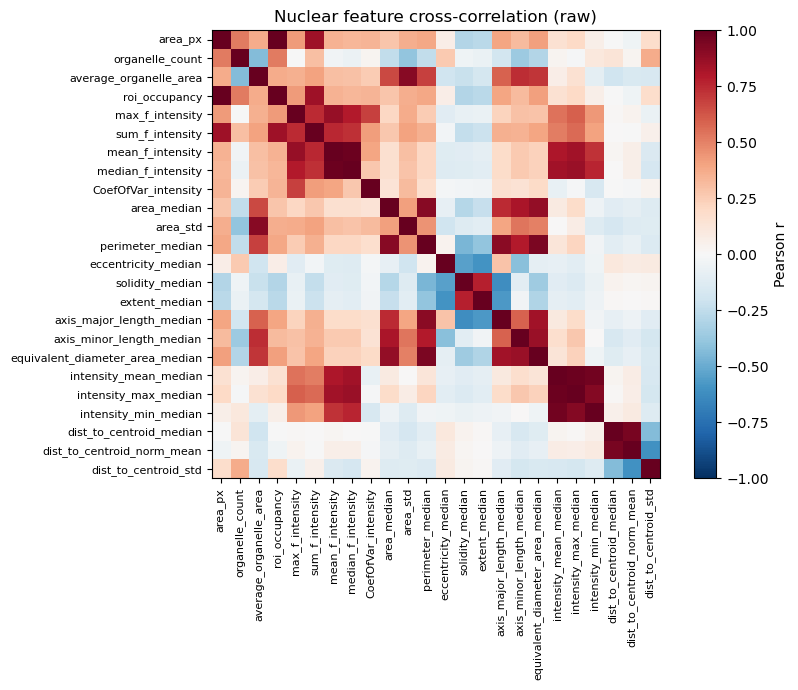

Highly correlated pairs (|r| > 0.9):
  +1.000  area_px                roi_occupancy
  +0.983  intensity_mean_median  intensity_max_median
  +0.980  mean_f_intensity       median_f_intensity
  +0.962  intensity_mean_median  intensity_min_median
  +0.947  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.939  perimeter_median       equivalent_diameter_area_median
  +0.916  intensity_max_median   intensity_min_median
  +0.912  average_organelle_area area_std
  +0.912  area_median            perimeter_median
  +0.902  perimeter_median       axis_major_length_median
[full] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full] dropped 0 rows with NaN/inf; 580831 remain
[full] EVR: [0.29  0.192 0.177 0.115 0.09  0.063 0.025 0.022 0.02  0.006 0.   ]
[full] cumulative: [0.29  0.482 0.659 0.774 0

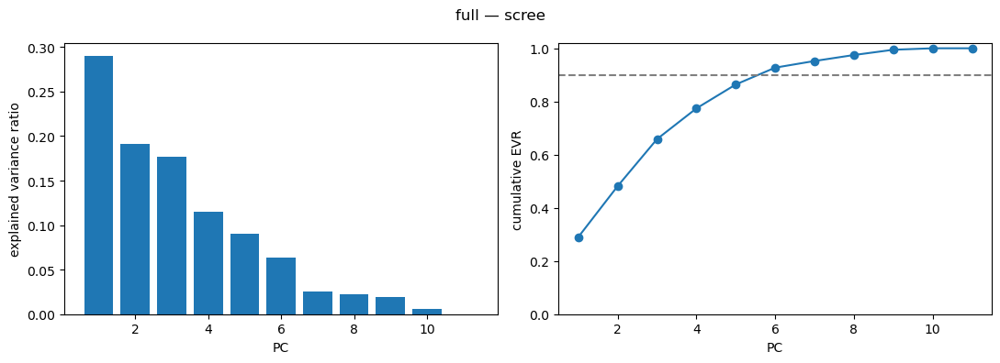

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.487  0.085  0.218  0.195  0.010 -0.320  0.149   
organelle_count             0.286 -0.155  0.313  0.342 -0.412  0.354 -0.087   
roi_occupancy               0.487  0.085  0.218  0.195  0.010 -0.320  0.149   
mean_f_intensity            0.278  0.511 -0.132 -0.262 -0.031  0.264  0.009   
CoefOfVar_intensity         0.214  0.206  0.118  0.058  0.786  0.392 -0.082   
eccentricity_median         0.213 -0.438 -0.282  0.039 -0.035  0.512  0.547   
solidity_median            -0.333  0.275  0.373  0.180 -0.079  0.217  0.330   
extent_median              -0.330  0.303  0.376  0.157 -0.080  0.117  0.213   
intensity_max_median        0.210  0.447 -0.212 -0.319 -0.427  0.148 -0.003   
dist_to_centroid_norm_mean -0.029  0.162 -0.361  0.667 -0.086  0.175 -0.478   
dist_to_centroid_std        0.107 -0.269  0.490 -0.359 -0.090  0.268 -0.509   

                              PC8    PC9   PC10   P

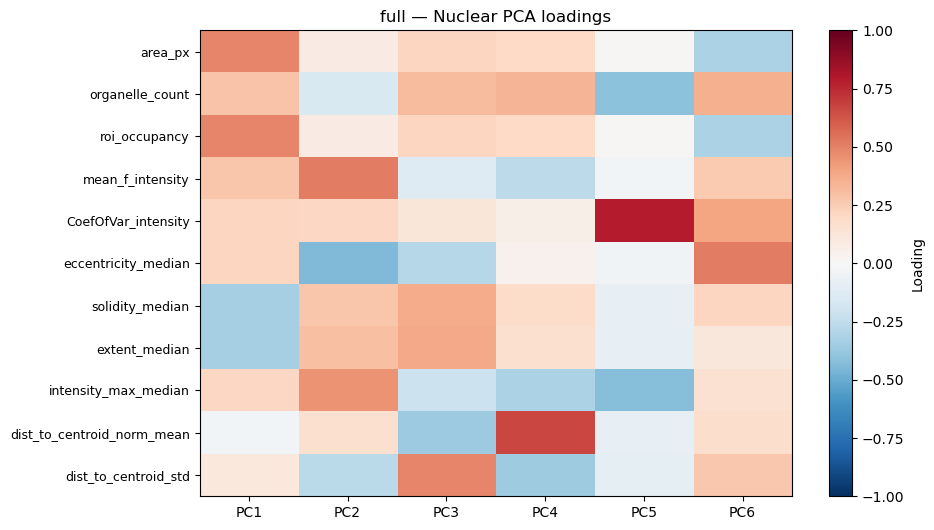

In [14]:
df_auto = df[df["Source"] == "automated"]
feature_correlation(df_auto)
df_auto, pca, FEATURES = fit_pca(df_auto, label="full")

### PCA plots - ROI-level

All 13 iNDI_Plate_ID values have a color.


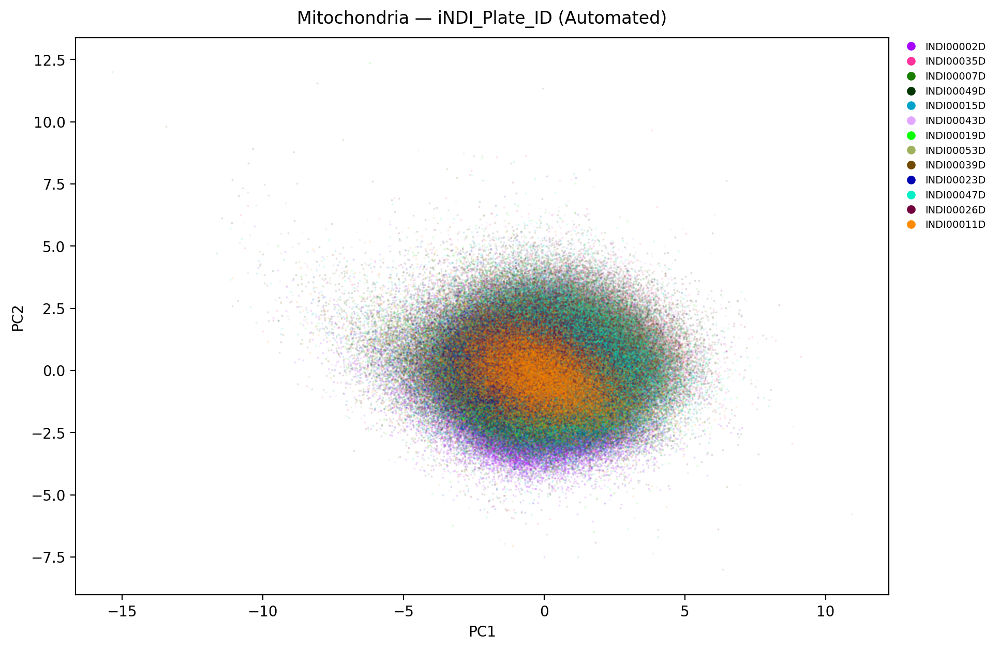

All 4 Batch values have a color.


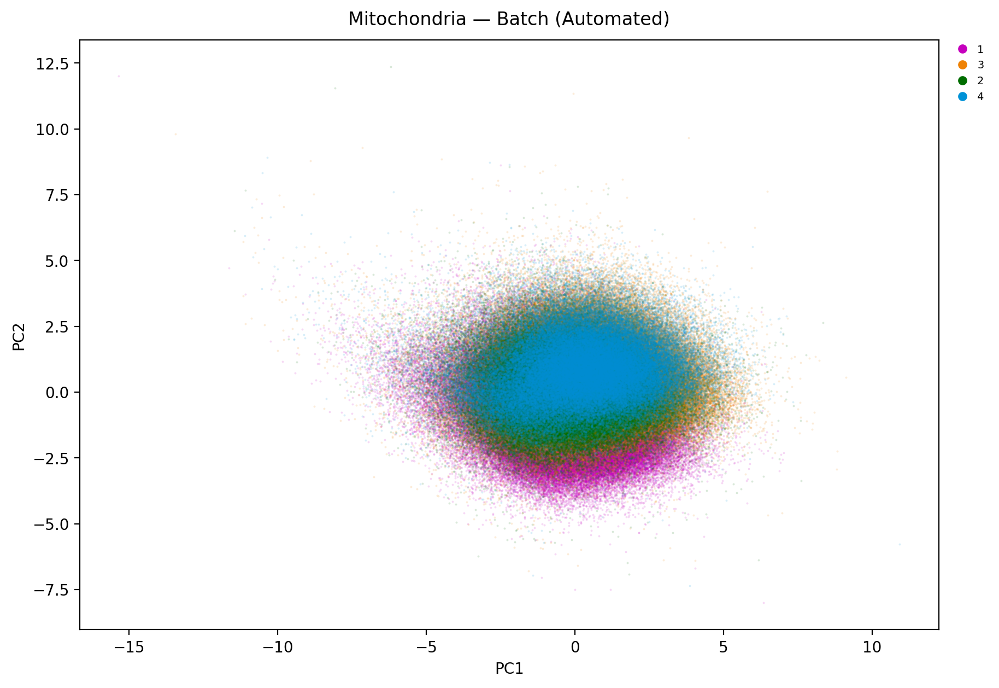

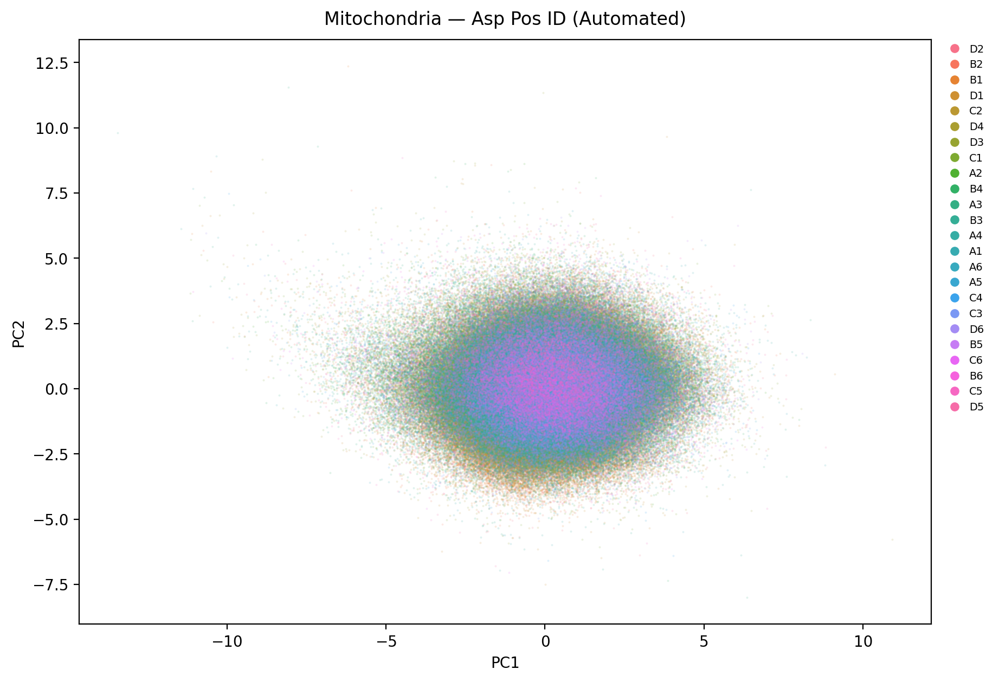

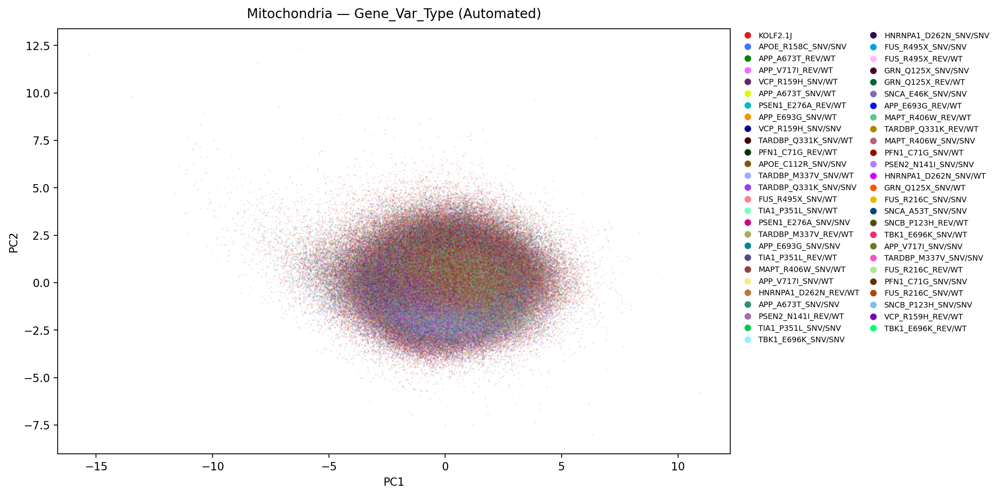

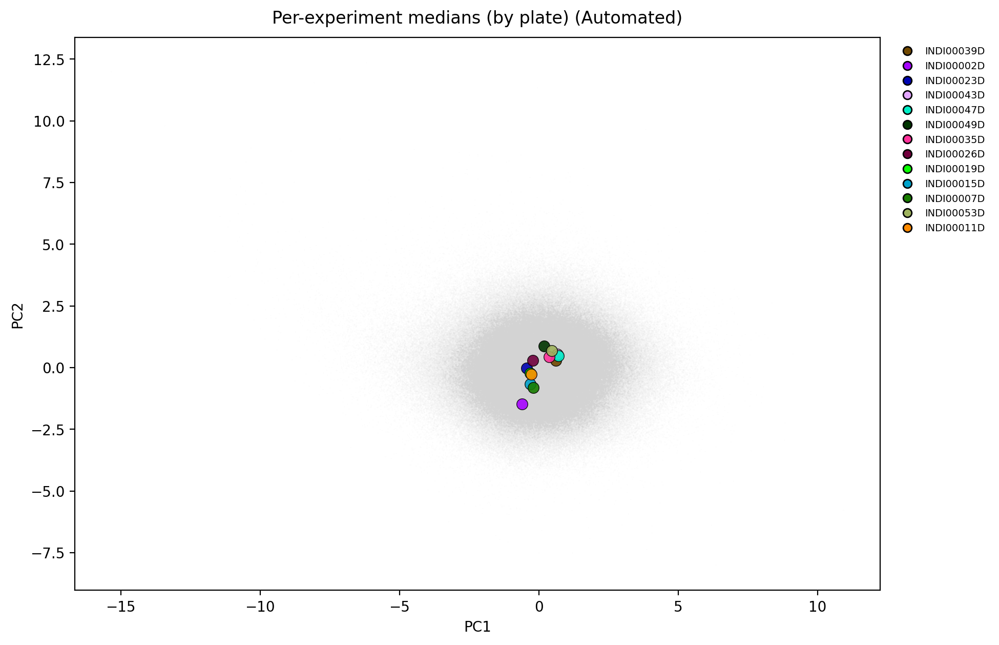

Std of per-experiment centroids (batch magnitude):
PC1    0.462
PC2    0.673
PC3    0.374
dtype: float64


In [15]:
plate_pal = make_palette(df_auto["iNDI_Plate_ID"])
check_palette_coverage(df_auto, "iNDI_Plate_ID", plate_pal)
pca_scatter(df_auto, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Mitochondria — iNDI_Plate_ID (Automated)")

batch_palette = make_palette(df_auto["Batch"])
check_palette_coverage(df_auto, "Batch", batch_palette)
pca_scatter(df_auto, "Batch", palette=batch_palette, figsize=(12, 7),title="Mitochondria — Batch (Automated)")

pca_scatter(df_auto, "Asp PosID", figsize=(12, 7),title="Mitochondria — Asp Pos ID (Automated)")

pca_scatter(df_auto, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Mitochondria — Gene_Var_Type (Automated)")

centroid_overlay(df_auto, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate) (Automated)")
cent = df_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 119421 rows (13440 images)
[full] well-level: 3740 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 3740 remain
[full well] EVR: [0.273 0.24  0.205 0.14  0.074 0.043 0.013 0.006 0.004 0.001 0.   ]
[full well] cumulative: [0.273 0.513 0.719 0.859 0.932 0.975 0.989 0.995 0.999 1.    1.   ]


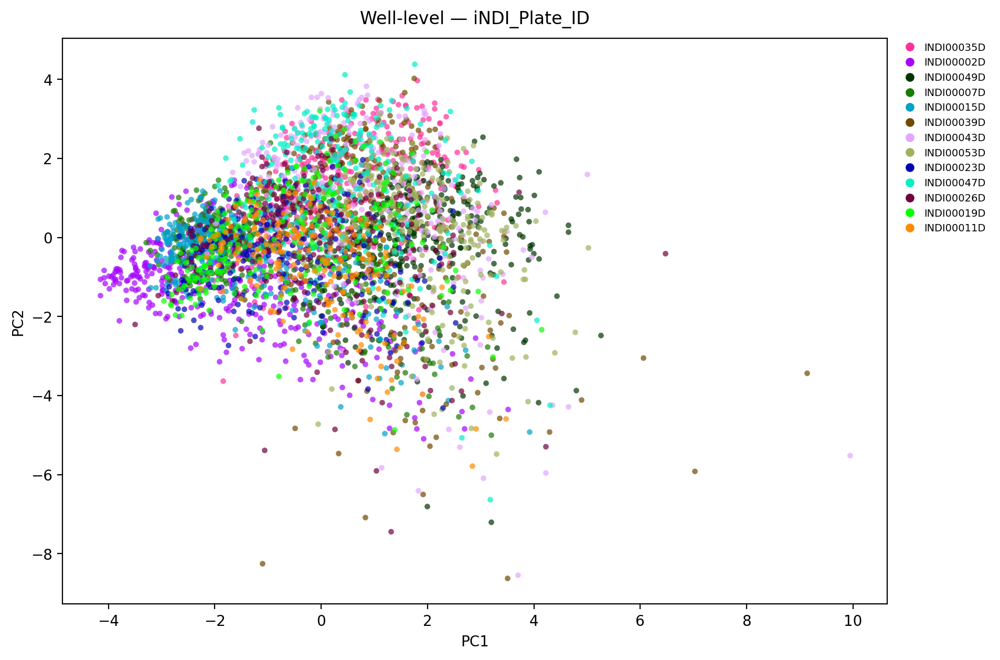

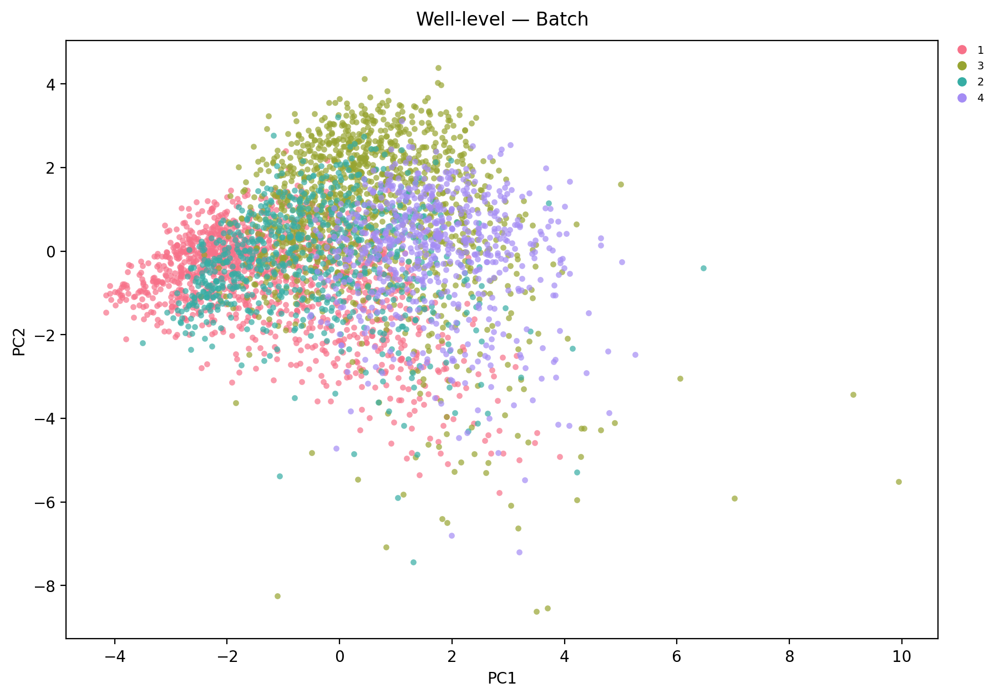

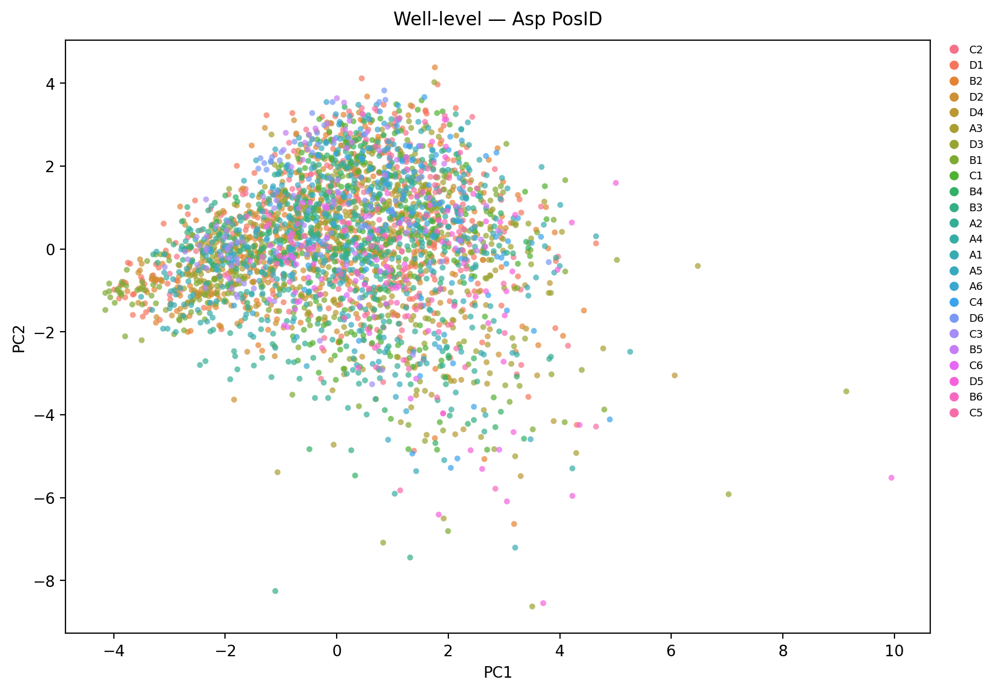

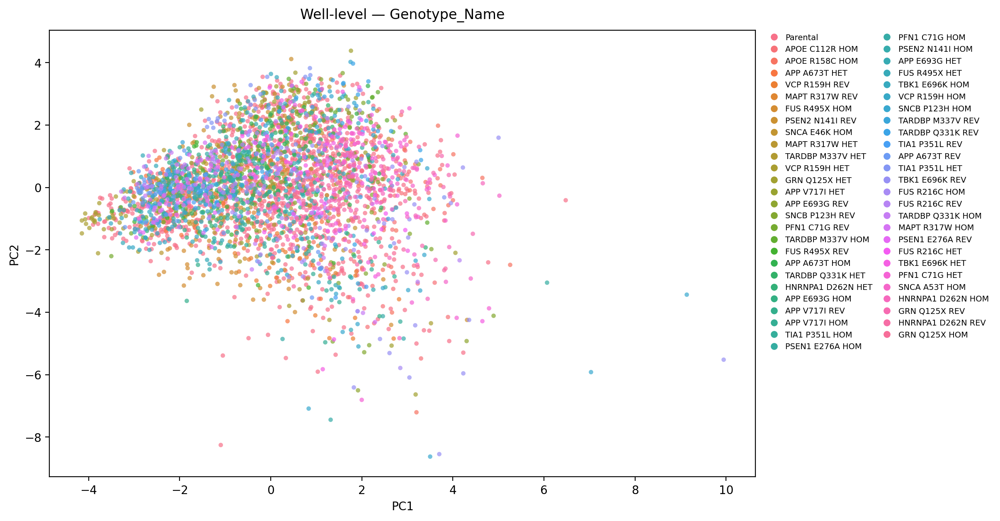

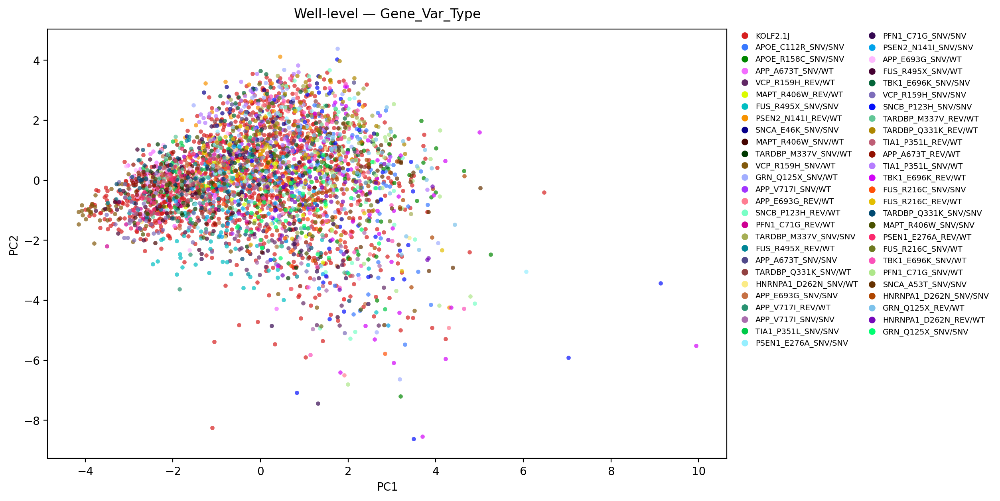

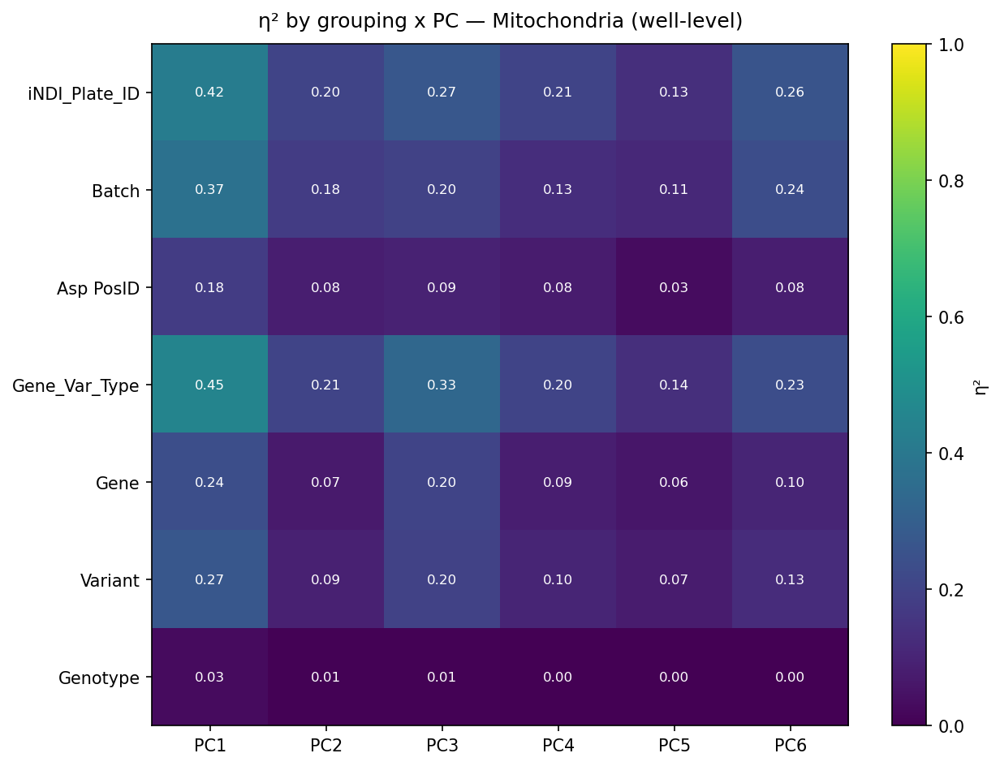

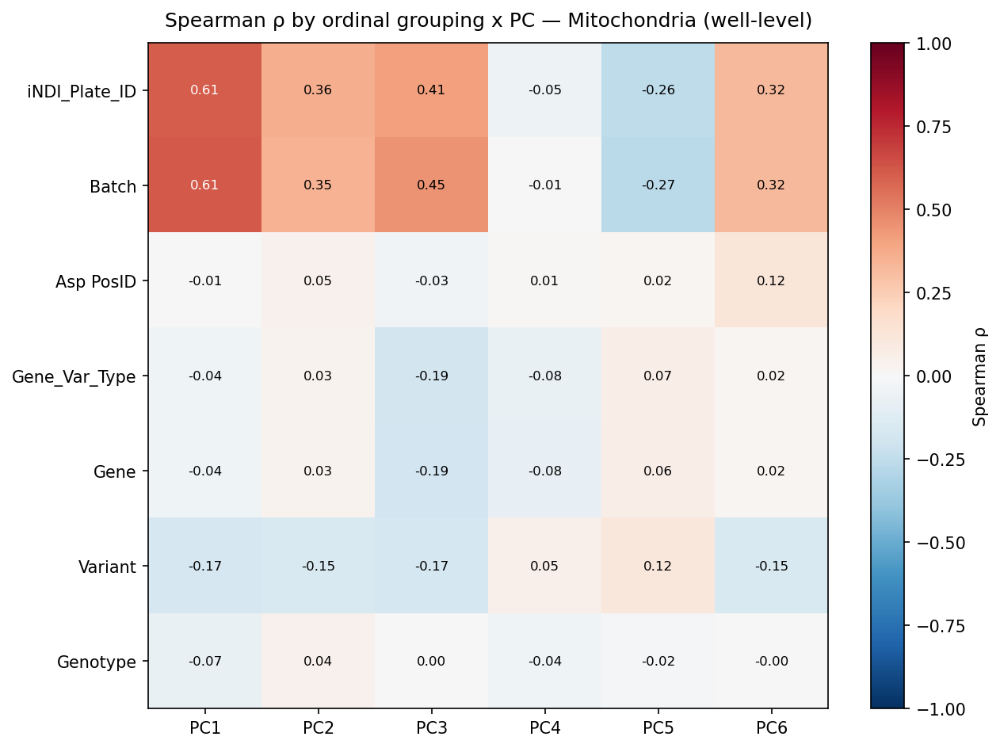

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.607597,0.359685,0.411838,-0.052937,-0.257025,0.322124
Batch,0.611978,0.346352,0.446276,-0.005471,-0.270165,0.322131
Asp PosID,-0.007696,0.045132,-0.034260,0.014569,0.022983,0.121796
Gene_Var_Type,-0.042965,0.033454,-0.185759,-0.077080,0.066492,0.021008
Gene,-0.041468,0.034496,-0.187816,-0.078632,0.064915,0.017182
Variant,-0.169566,-0.151480,-0.172728,0.051249,0.116087,-0.151723
Genotype,-0.071056,0.042233,0.002905,-0.040238,-0.015602,-0.000587


In [16]:
well_level = aggregate_wells(df_auto, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — Mitochondria (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Mitochondria (well-level)")

## Manual analysis
### Feature assessment and loadings

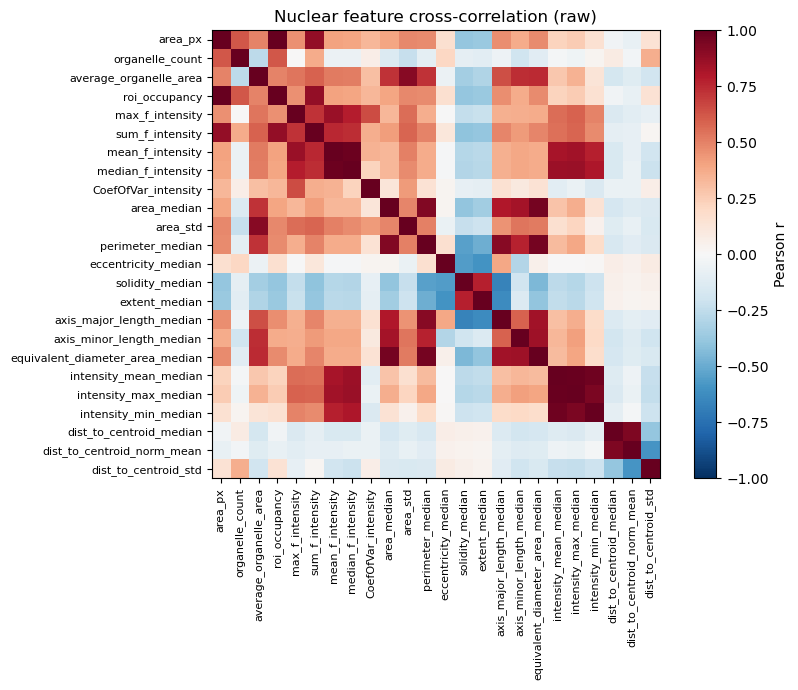

Highly correlated pairs (|r| > 0.9):
  +0.989  intensity_mean_median  intensity_max_median
  +0.981  mean_f_intensity       median_f_intensity
  +0.973  intensity_mean_median  intensity_min_median
  +0.959  area_median            equivalent_diameter_area_median
  +0.955  perimeter_median       equivalent_diameter_area_median
  +0.944  intensity_max_median   intensity_min_median
  +0.932  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.924  area_median            perimeter_median
  +0.912  perimeter_median       axis_major_length_median
  +0.908  average_organelle_area area_std
[full] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full] dropped 0 rows with NaN/inf; 455816 remain
[full] EVR: [0.331 0.186 0.154 0.122 0.09  0.046 0.026 0.021 0.02  0.005 0.   ]
[full] cumulative: [0.331 0

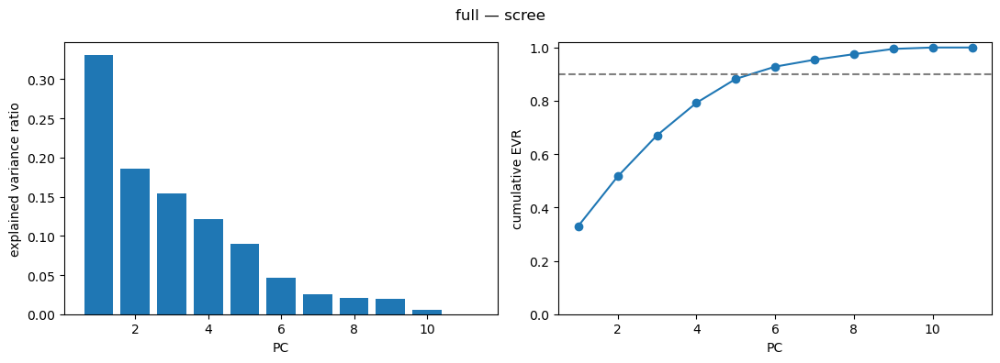

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.452  0.190 -0.182  0.225 -0.063 -0.236 -0.172   
organelle_count             0.260  0.429 -0.018  0.297 -0.324  0.339  0.090   
roi_occupancy               0.452  0.190 -0.182  0.225 -0.063 -0.236 -0.172   
mean_f_intensity            0.310 -0.356 -0.397 -0.193  0.051  0.275  0.083   
CoefOfVar_intensity         0.184  0.081 -0.235  0.064  0.860  0.185  0.072   
eccentricity_median         0.238 -0.015  0.562 -0.043  0.074  0.593 -0.439   
solidity_median            -0.366  0.179 -0.374  0.131 -0.054  0.332 -0.274   
extent_median              -0.364  0.167 -0.402  0.128 -0.064  0.215 -0.214   
intensity_max_median        0.252 -0.414 -0.296 -0.241 -0.363  0.265  0.086   
dist_to_centroid_norm_mean -0.063 -0.288  0.121  0.709 -0.006  0.212  0.518   
dist_to_centroid_std        0.053  0.544  0.017 -0.417 -0.035  0.204  0.576   

                              PC8    PC9   PC10   P

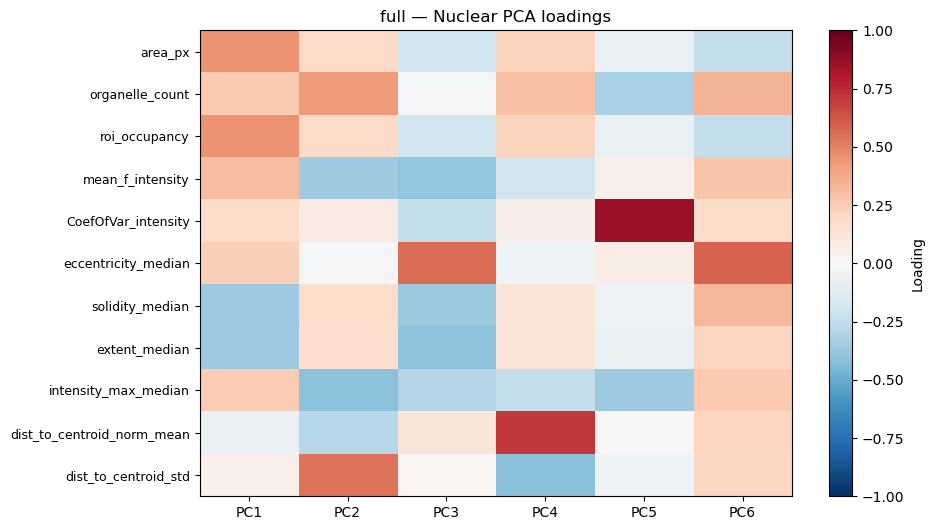

In [17]:
df_manual = df[df["Source"] == "manual"]
feature_correlation(df_manual)
df_manual, pca, FEATURES = fit_pca(df_manual, label="full")

### PCA plots - ROI-level

All 8 iNDI_Plate_ID values have a color.


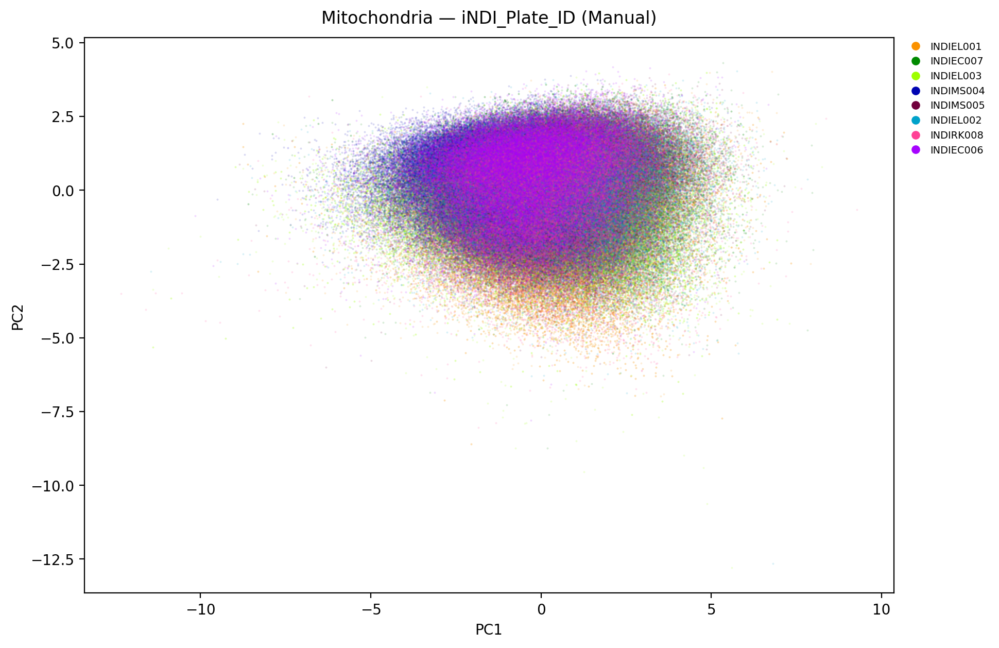

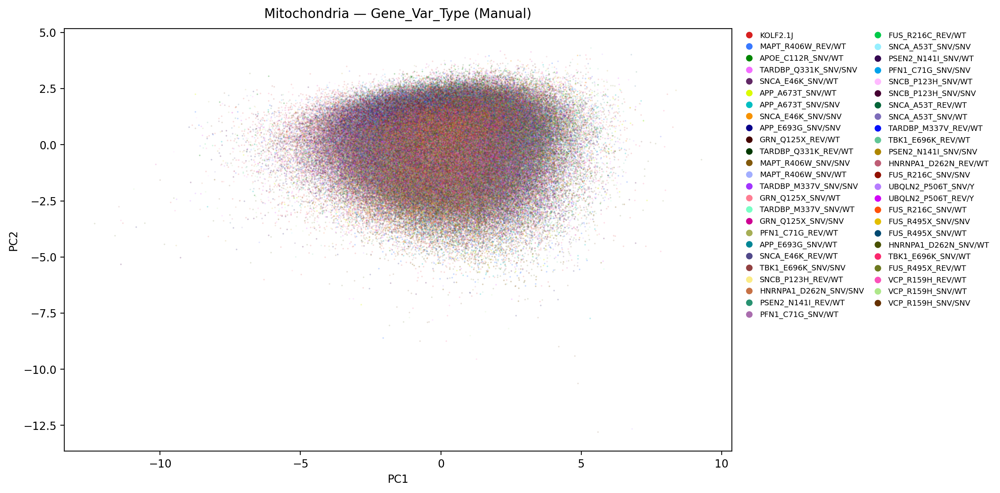

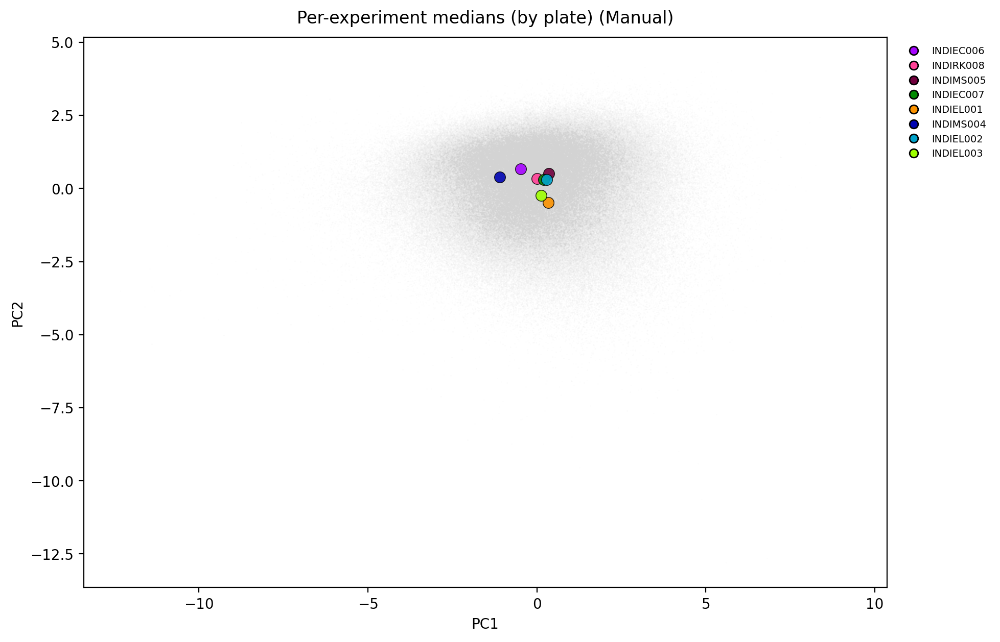

Std of per-experiment centroids (batch magnitude):
PC1    0.505
PC2    0.384
PC3    0.525
dtype: float64


In [18]:
plate_pal = make_palette(df_manual["iNDI_Plate_ID"])
check_palette_coverage(df_manual, "iNDI_Plate_ID", plate_pal)
pca_scatter(df_manual, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Mitochondria — iNDI_Plate_ID (Manual)")

pca_scatter(df_manual, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Mitochondria — Gene_Var_Type (Manual)")

centroid_overlay(df_manual, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate) (Manual)")
cent = df_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 74690 rows (11755 images)
[full] well-level: 2196 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 2196 remain
[full well] EVR: [0.314 0.215 0.182 0.145 0.083 0.036 0.013 0.008 0.003 0.001 0.   ]
[full well] cumulative: [0.314 0.529 0.711 0.855 0.939 0.975 0.988 0.996 0.999 1.    1.   ]


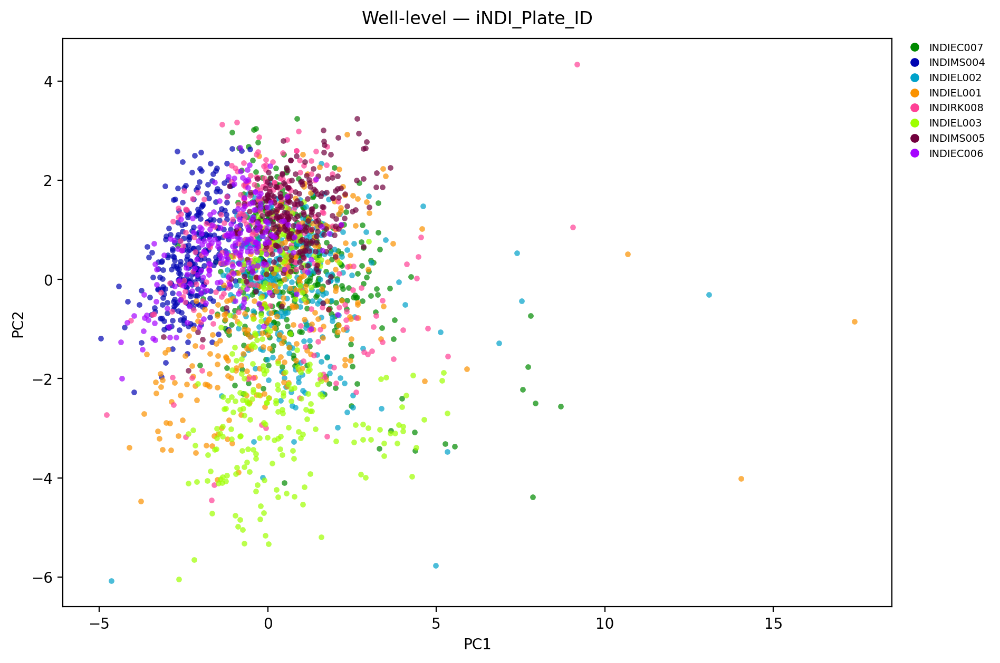

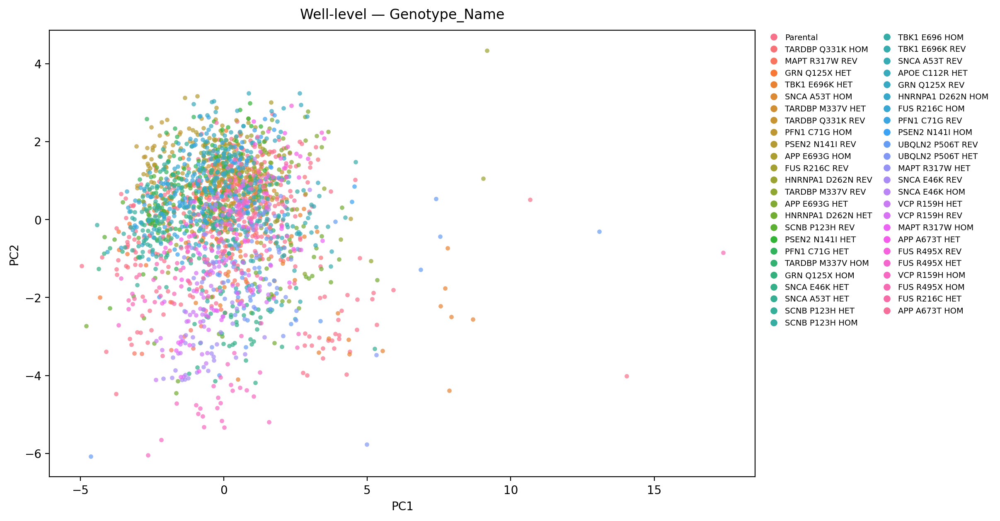

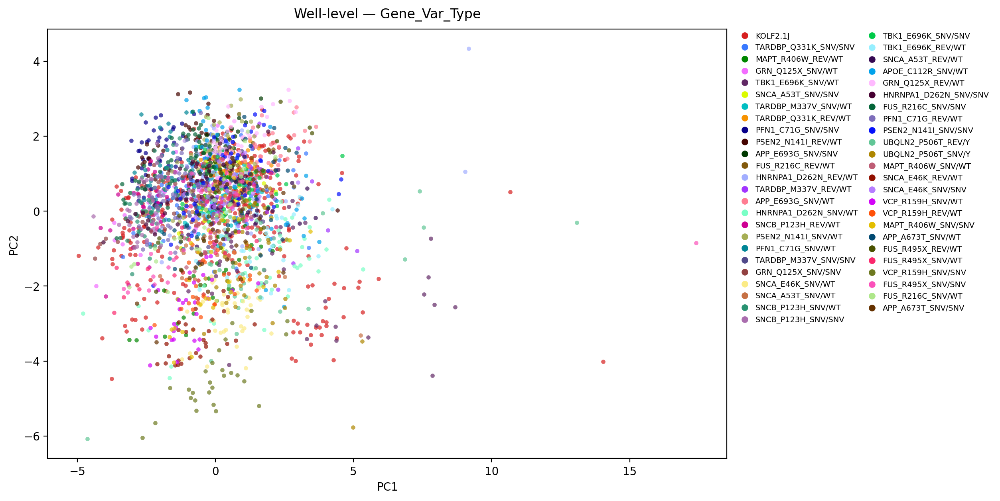

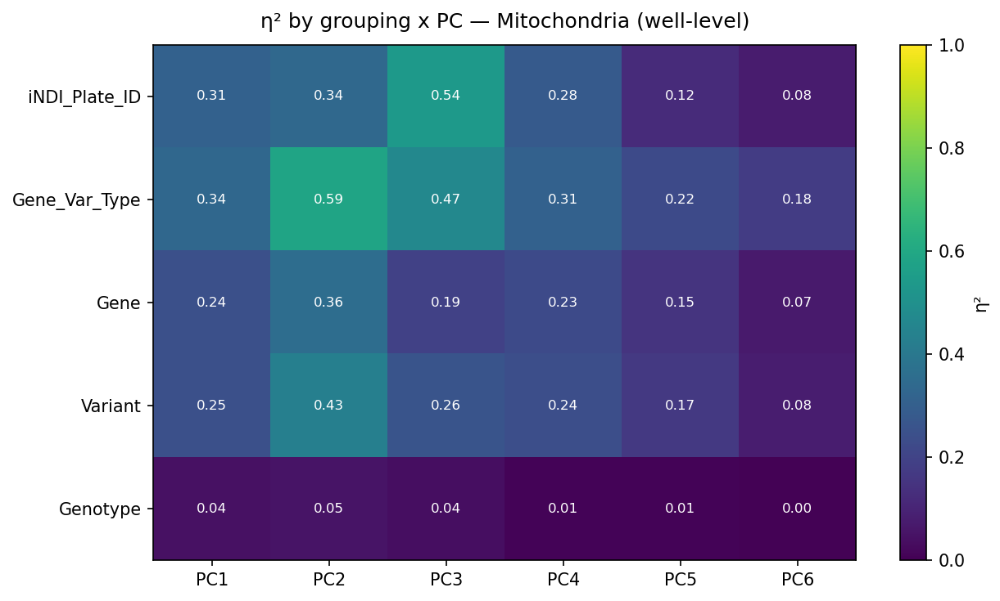

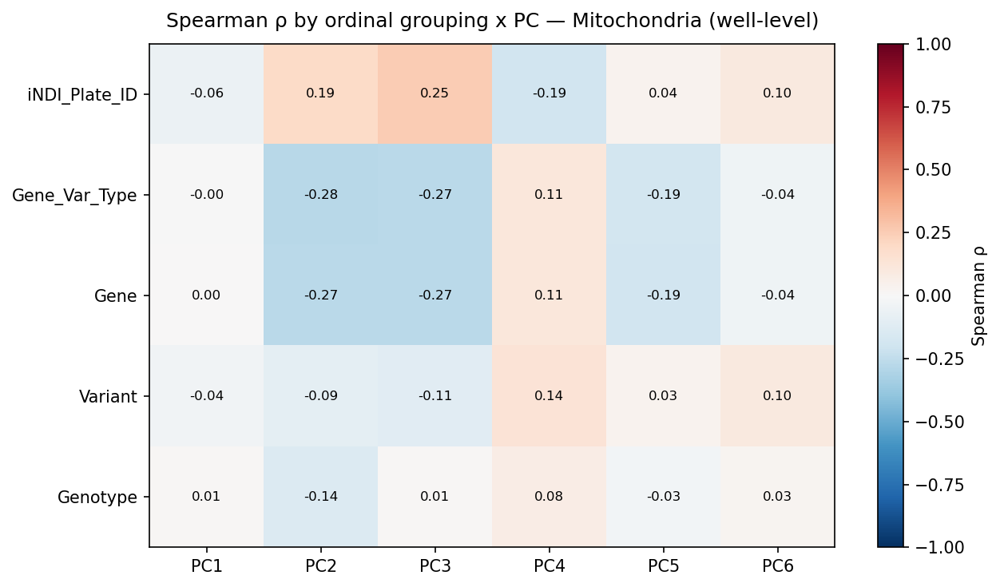

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.057858,0.189344,0.251509,-0.192407,0.035141,0.096329
Gene_Var_Type,-0.001016,-0.281200,-0.266910,0.113100,-0.186620,-0.039834
Gene,0.000586,-0.272232,-0.267373,0.112993,-0.188046,-0.044271
Variant,-0.036035,-0.093776,-0.114254,0.139197,0.033075,0.097610
Genotype,0.012903,-0.137078,0.011791,0.076742,-0.025586,0.026006


In [19]:
well_level = aggregate_wells(df_manual, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_level["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — Mitochondria (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Mitochondria (well-level)")

# Parental-only analysis

In [20]:
# filter for parentals
parental        = df[df["Gene_Var_Type"] == "KOLF2.1J"]
parental_auto   = df[(df["Gene_Var_Type"] == "KOLF2.1J") & (df["Source"] == "automated")]
parental_manual = df[(df["Gene_Var_Type"] == "KOLF2.1J") & (df["Source"] == "manual")]

## ROI level analysis
### Feature assessment and PCA loadings


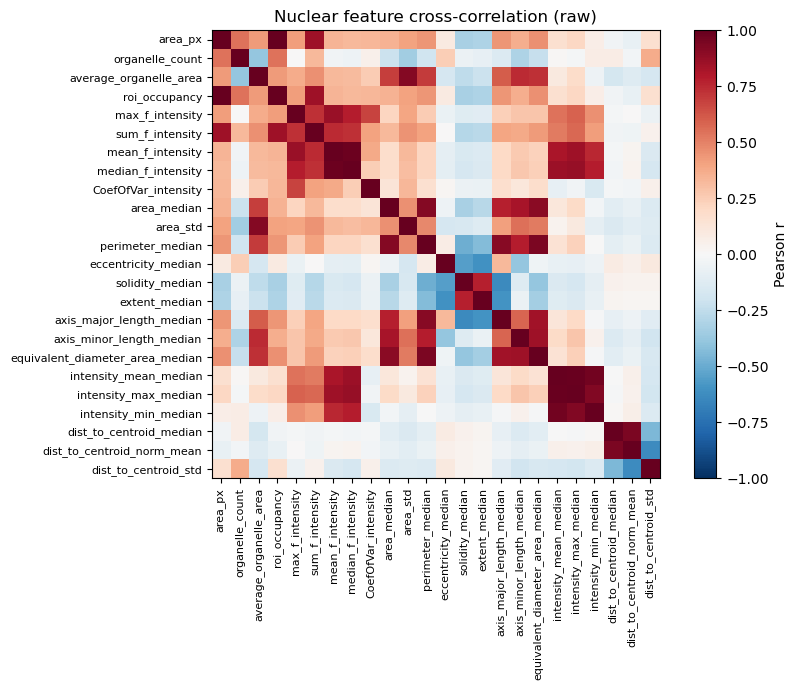

Highly correlated pairs (|r| > 0.9):
  +1.000  area_px                roi_occupancy
  +0.986  intensity_mean_median  intensity_max_median
  +0.980  mean_f_intensity       median_f_intensity
  +0.967  intensity_mean_median  intensity_min_median
  +0.945  perimeter_median       equivalent_diameter_area_median
  +0.943  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.929  intensity_max_median   intensity_min_median
  +0.917  average_organelle_area area_std
  +0.917  area_median            perimeter_median
  +0.910  perimeter_median       axis_major_length_median
  +0.901  area_median            equivalent_diameter_area_median
[full] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full] dropped 0 rows with NaN/inf; 236431 remain
[full] EVR: [0.301 0.186 0.174 0.116 0.09  0.061 0.025 0.022

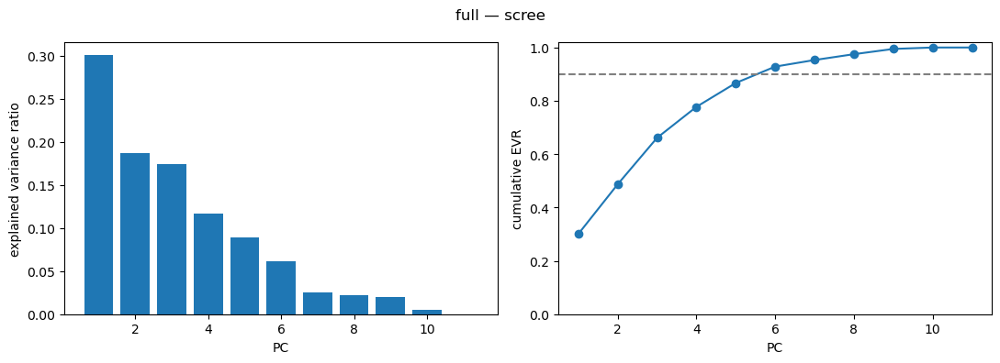

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.474 -0.032 -0.239  0.228 -0.034 -0.299  0.170   
organelle_count             0.283 -0.295 -0.206  0.317 -0.377  0.419 -0.155   
roi_occupancy               0.474 -0.032 -0.239  0.228 -0.034 -0.299  0.170   
mean_f_intensity            0.273  0.509 -0.164 -0.271  0.023  0.257  0.001   
CoefOfVar_intensity         0.206  0.094 -0.202  0.075  0.833  0.292 -0.098   
eccentricity_median         0.229 -0.230  0.473  0.002  0.014  0.524  0.556   
solidity_median            -0.350  0.032 -0.447  0.156 -0.051  0.246  0.347   
extent_median              -0.349  0.056 -0.464  0.140 -0.060  0.143  0.227   
intensity_max_median        0.211  0.500 -0.068 -0.330 -0.384  0.185 -0.012   
dist_to_centroid_norm_mean -0.057  0.323  0.235  0.648 -0.074  0.220 -0.449   
dist_to_centroid_std        0.100 -0.481 -0.278 -0.378 -0.044  0.237 -0.475   

                              PC8    PC9   PC10   P

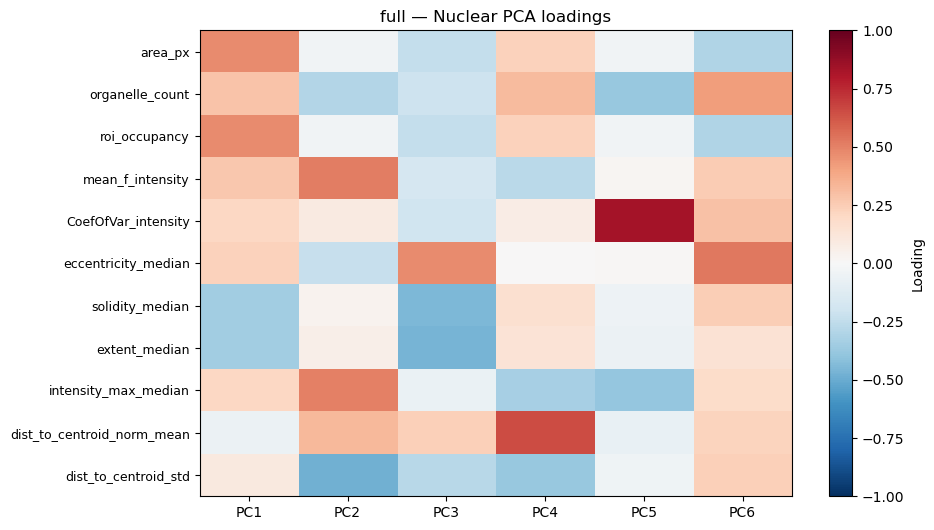

In [21]:
feature_correlation(parental)
parental, pca, FEATURES = fit_pca(parental, label="full")

### PCA plots
#### All parentals


All 21 iNDI_Plate_ID values have a color.


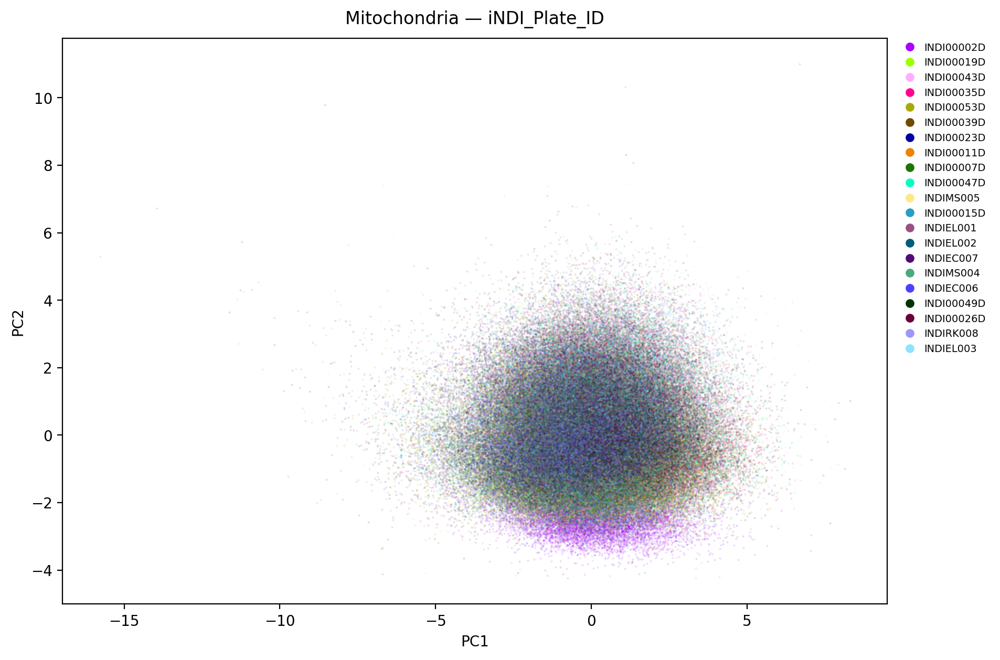

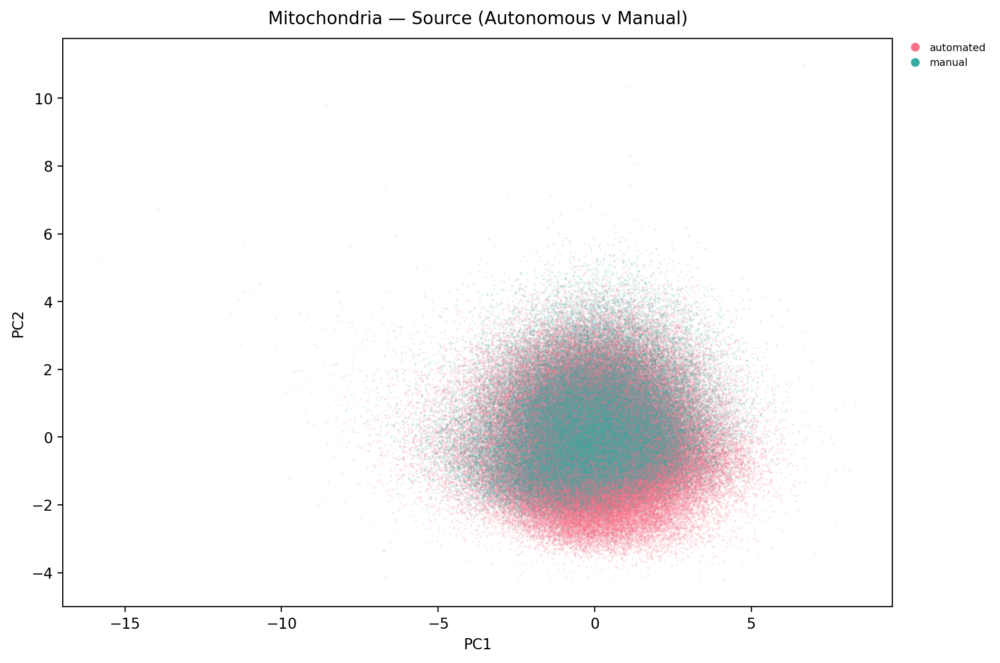

All 5 Batch values have a color.


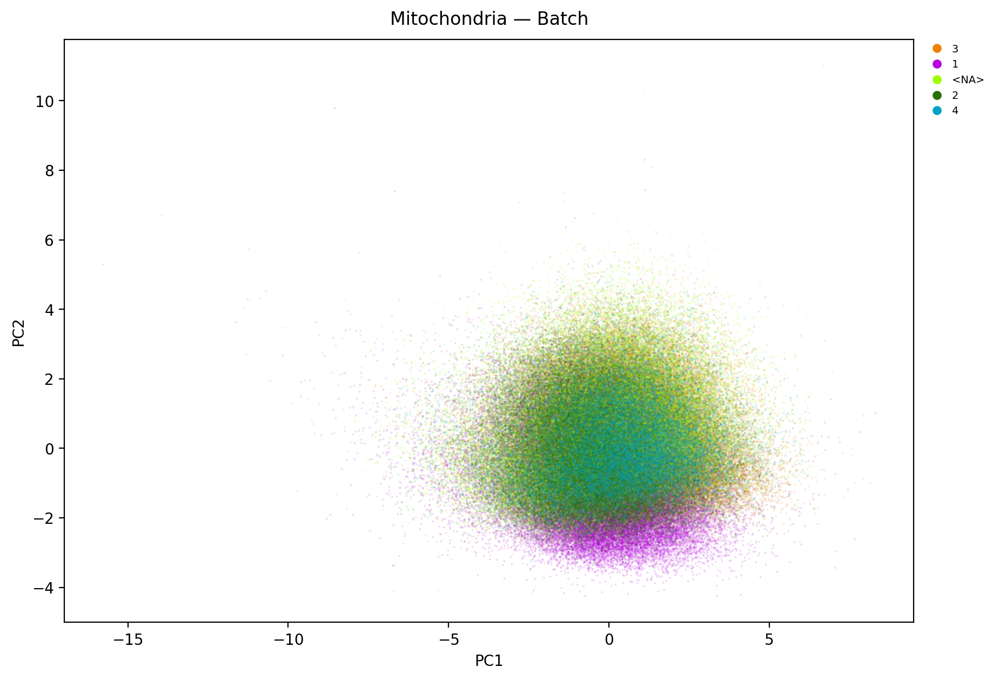

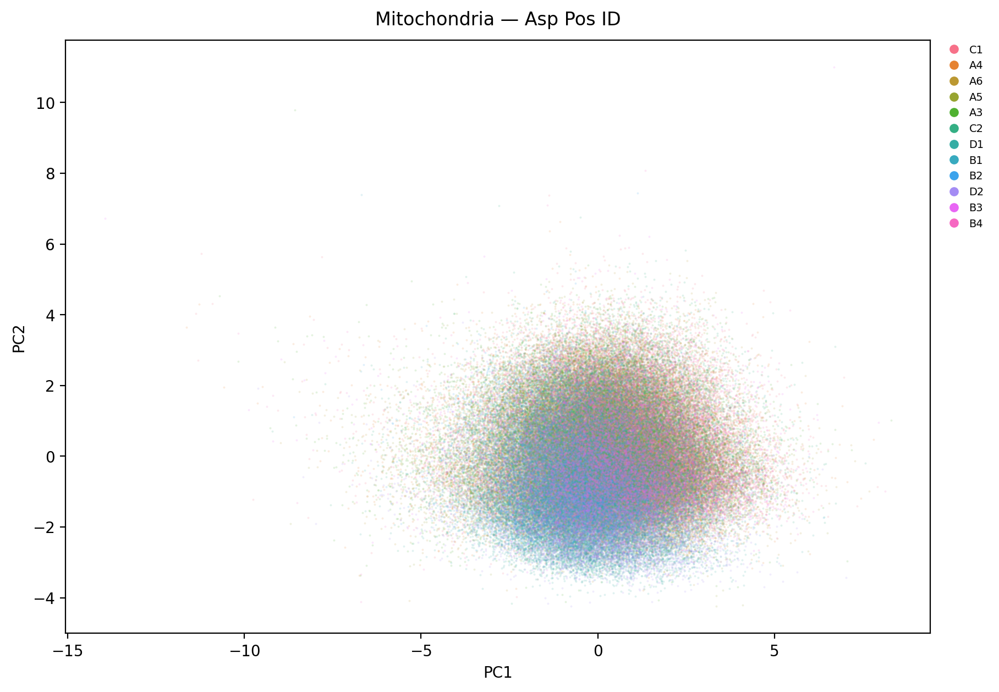

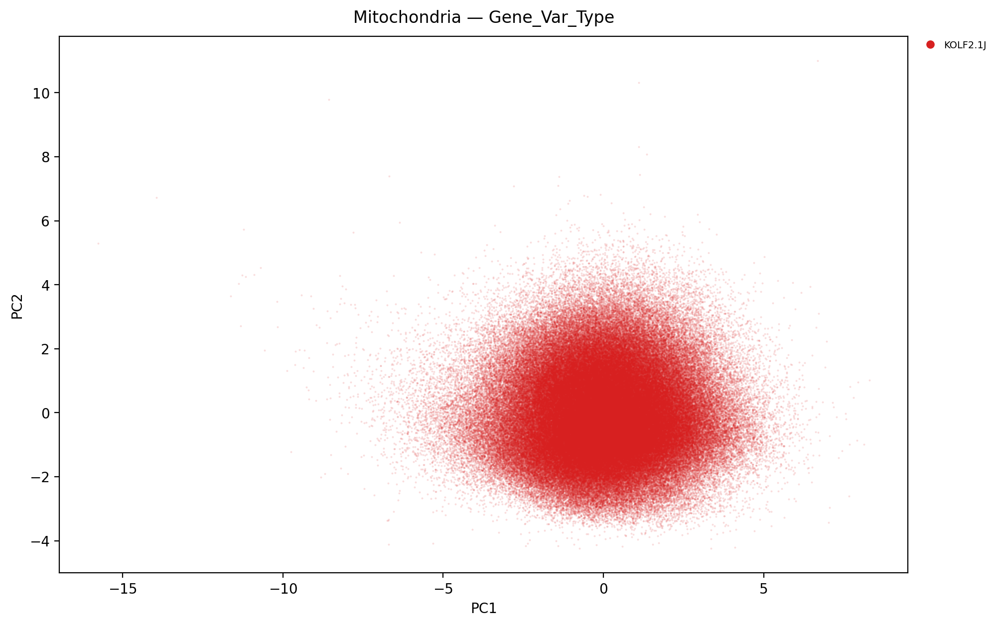

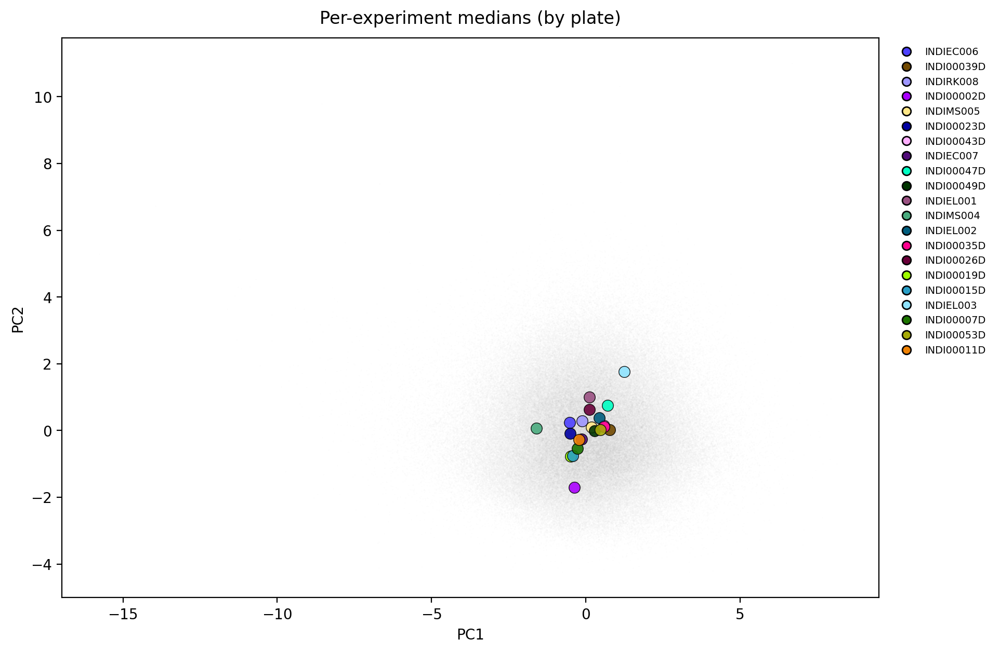

Std of per-experiment centroids (batch magnitude):
PC1    0.620
PC2    0.702
PC3    0.534
dtype: float64


In [22]:
plate_pal = make_palette(parental["iNDI_Plate_ID"])
check_palette_coverage(parental, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Mitochondria — iNDI_Plate_ID")

pca_scatter(parental, "Source", figsize=(12, 7),title="Mitochondria — Source (Autonomous v Manual)")

batch_palette = make_palette(parental["Batch"])
check_palette_coverage(parental, "Batch", batch_palette)
pca_scatter(parental, "Batch", palette=batch_palette, figsize=(12, 7),title="Mitochondria — Batch")

pca_scatter(parental, "Asp PosID", figsize=(12, 7),title="Mitochondria — Asp Pos ID")

pca_scatter(parental, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Mitochondria — Gene_Var_Type")

centroid_overlay(parental, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

#### Automated parentals

All 13 iNDI_Plate_ID values have a color.


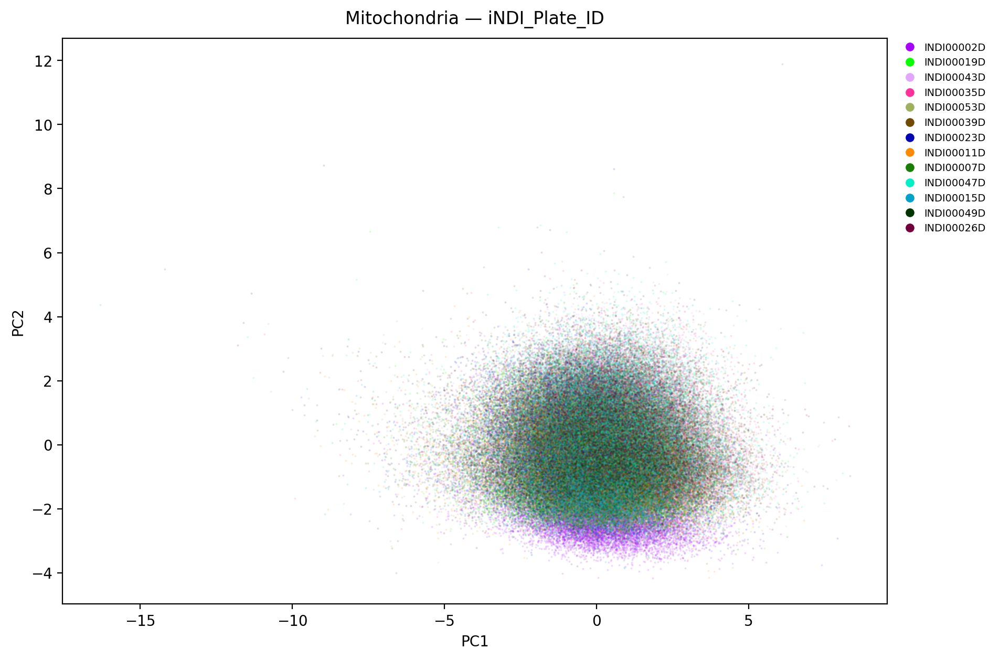

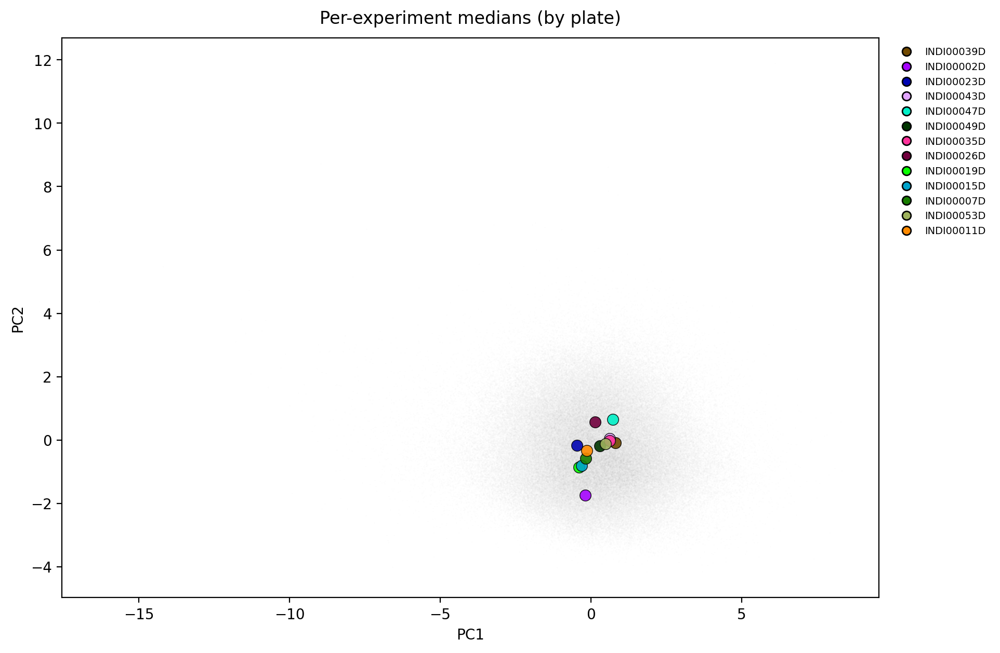

Std of per-experiment centroids (batch magnitude):
PC1    0.462
PC2    0.623
PC3    0.536
dtype: float64
All 4 Batch values have a color.


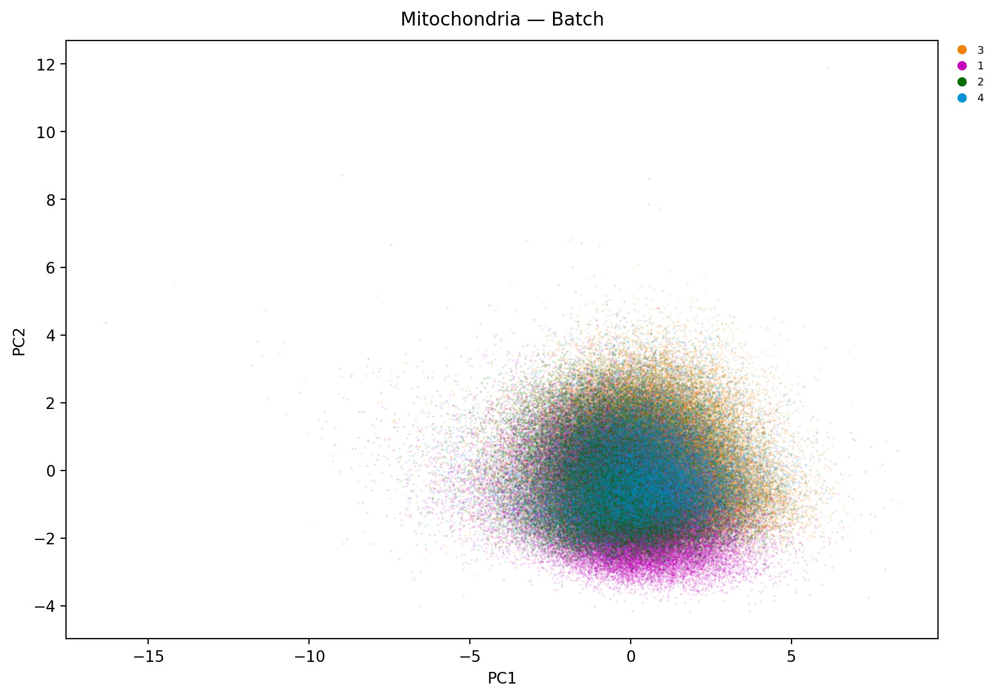

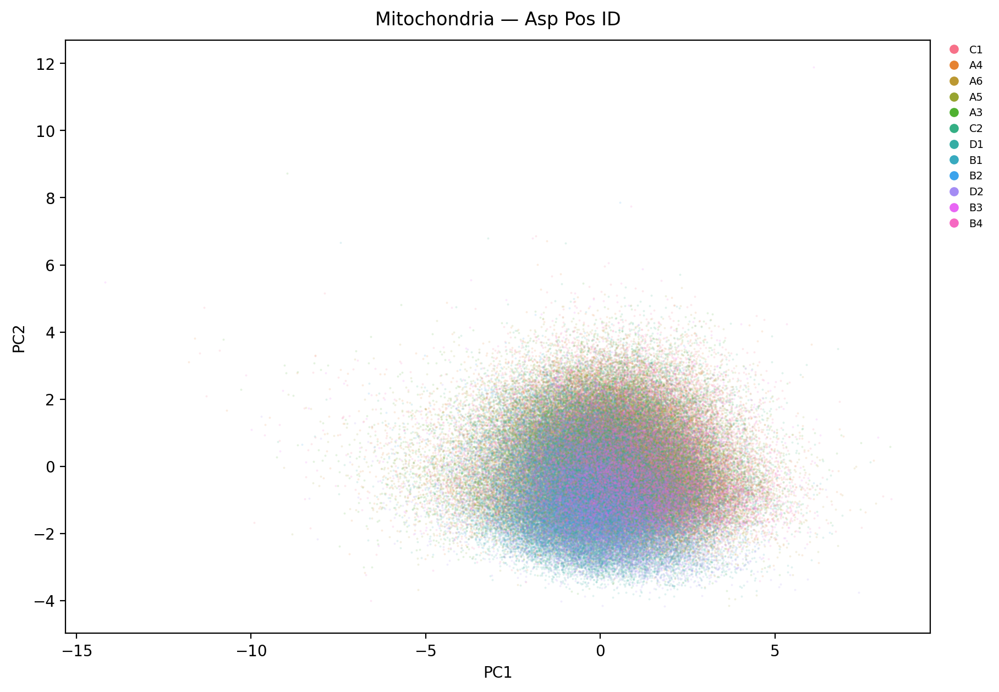

<Axes: title={'center': 'Mitochondria — Asp Pos ID'}, xlabel='PC1', ylabel='PC2'>

In [23]:
plate_pal = make_palette(parental_auto["iNDI_Plate_ID"])
check_palette_coverage(parental_auto, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental_auto, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Mitochondria — iNDI_Plate_ID")
centroid_overlay(parental_auto, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

batch_palette = make_palette(parental_auto["Batch"])
check_palette_coverage(parental_auto, "Batch", batch_palette)
pca_scatter(parental_auto, "Batch", palette=batch_palette, figsize=(12, 7),title="Mitochondria — Batch")

pca_scatter(parental_auto, "Asp PosID", figsize=(12, 7),title="Mitochondria — Asp Pos ID")

#### Manual parentals

All 8 iNDI_Plate_ID values have a color.


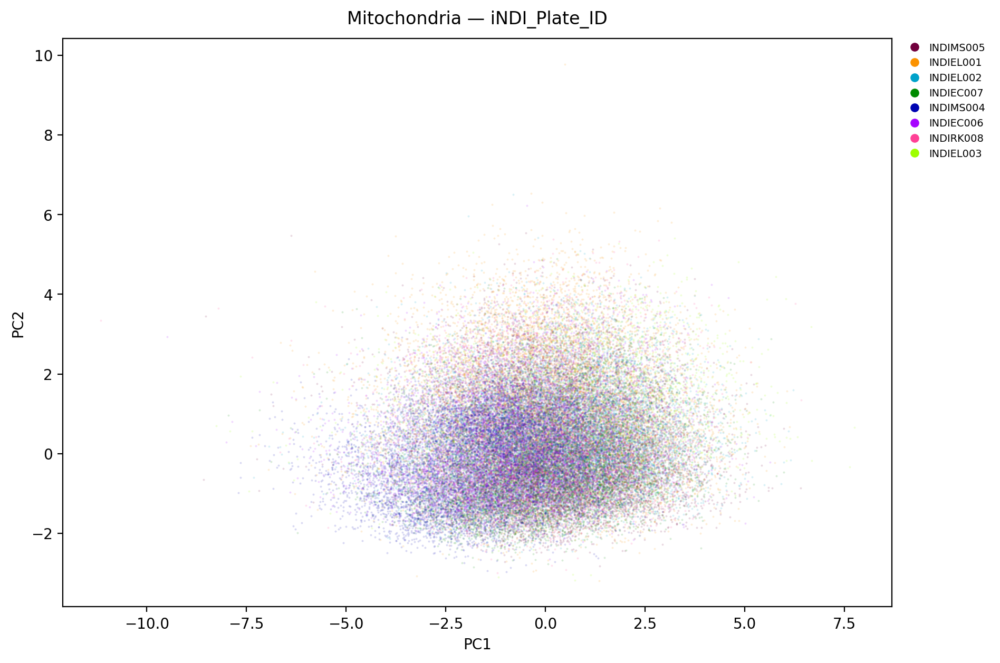

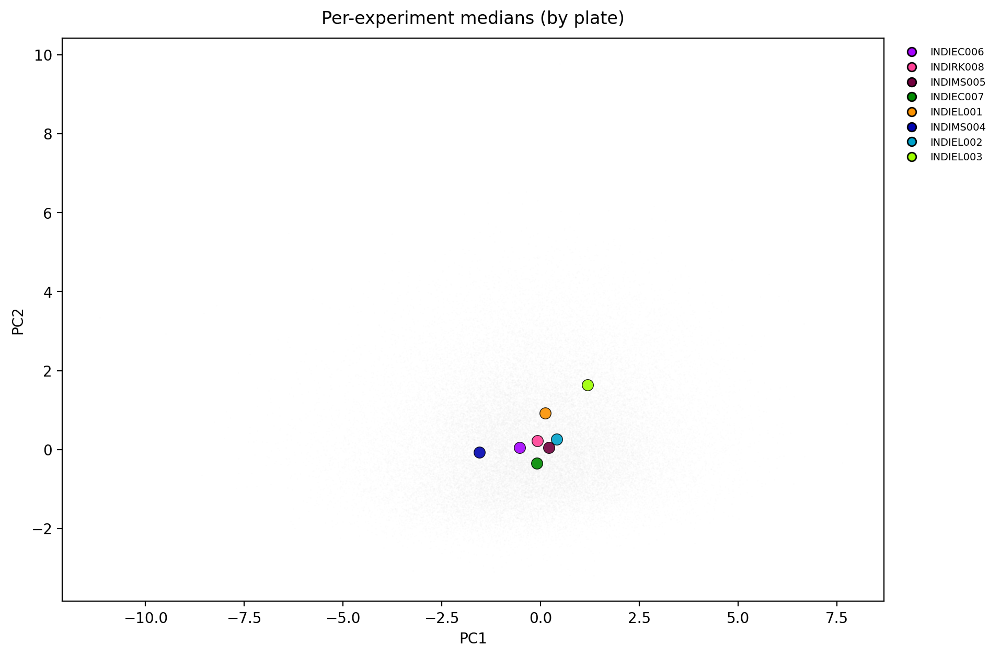

Std of per-experiment centroids (batch magnitude):
PC1    0.784
PC2    0.638
PC3    0.566
dtype: float64
All 1 Batch values have a color.


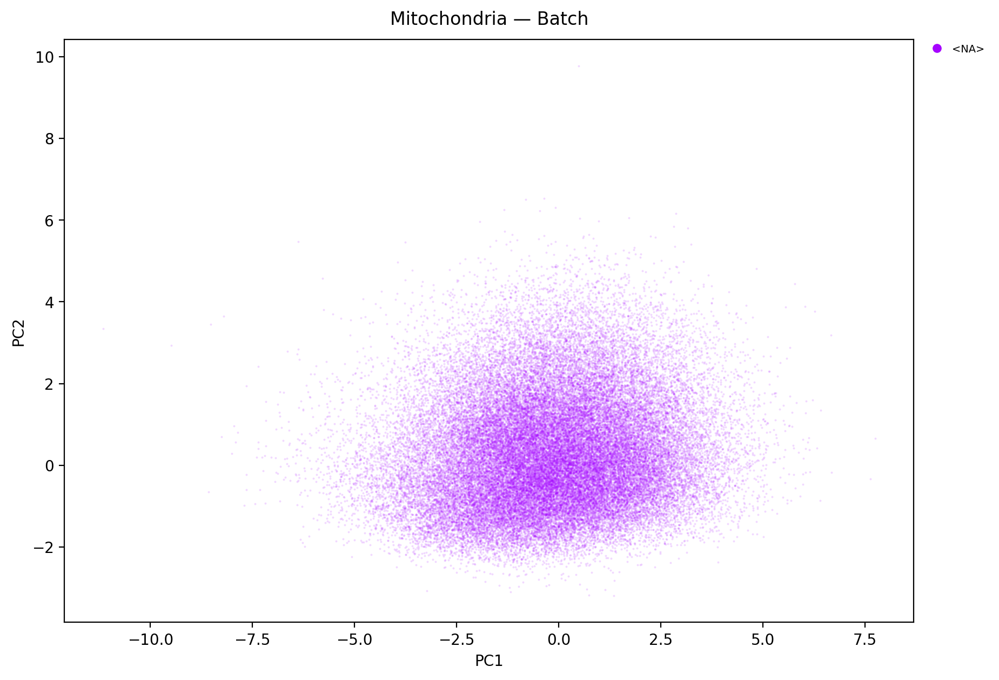

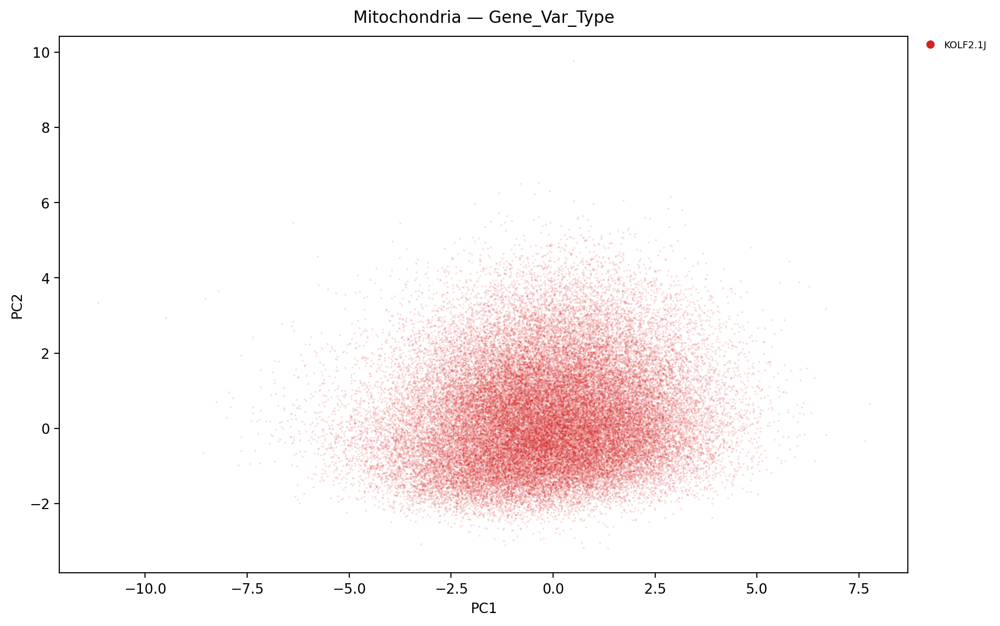

<Axes: title={'center': 'Mitochondria — Gene_Var_Type'}, xlabel='PC1', ylabel='PC2'>

In [24]:
plate_pal = make_palette(parental_manual["iNDI_Plate_ID"])
check_palette_coverage(parental_manual, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental_manual, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Mitochondria — iNDI_Plate_ID")
centroid_overlay(parental_manual, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

batch_palette = make_palette(parental_manual["Batch"])
check_palette_coverage(parental_manual, "Batch", batch_palette)
pca_scatter(parental_manual, "Batch", palette=batch_palette, figsize=(12, 7),title="Mitochondria — Batch")

pca_scatter(parental_manual, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Mitochondria — Gene_Var_Type")

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 47166 rows (13045 images)
[full] well-level: 1448 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 1448 remain
[full well] EVR: [0.265 0.225 0.207 0.146 0.083 0.048 0.012 0.011 0.003 0.001 0.   ]
[full well] cumulative: [0.265 0.49  0.697 0.842 0.926 0.974 0.986 0.996 0.999 1.    1.   ]


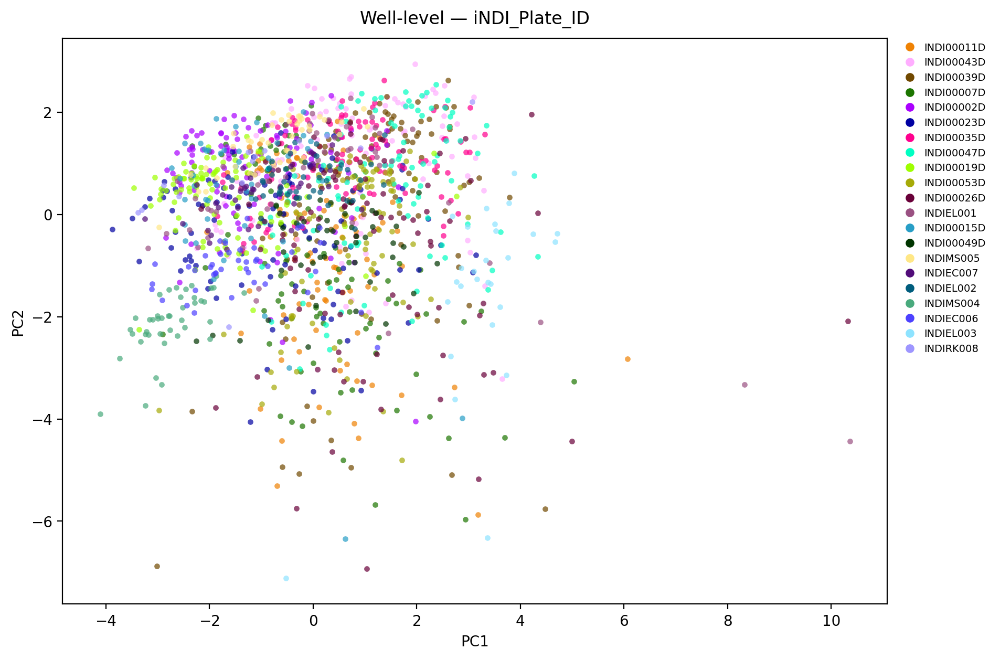

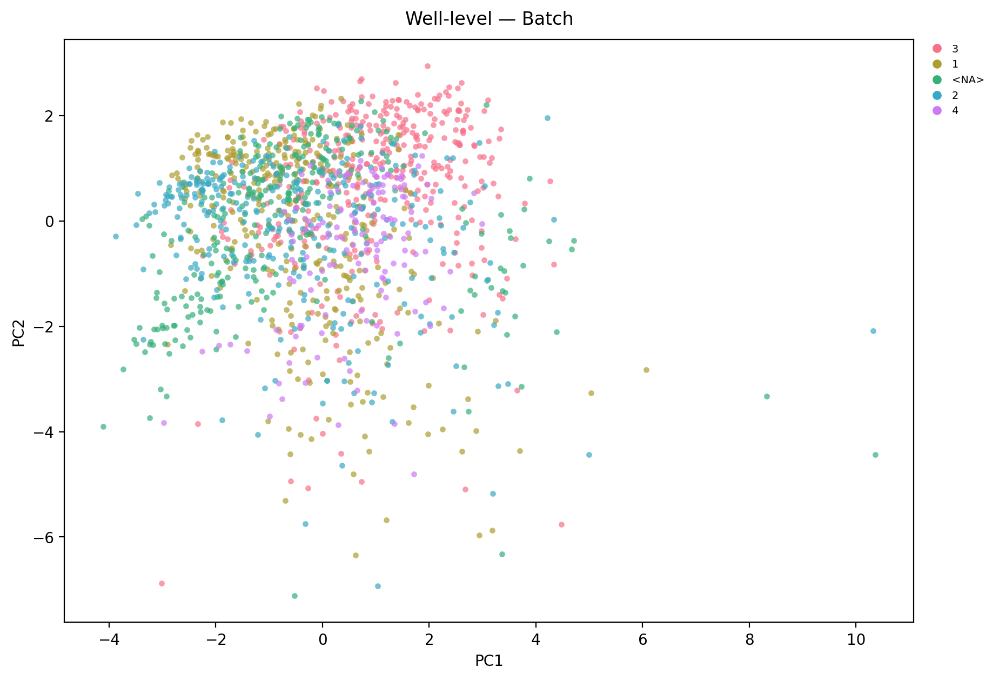

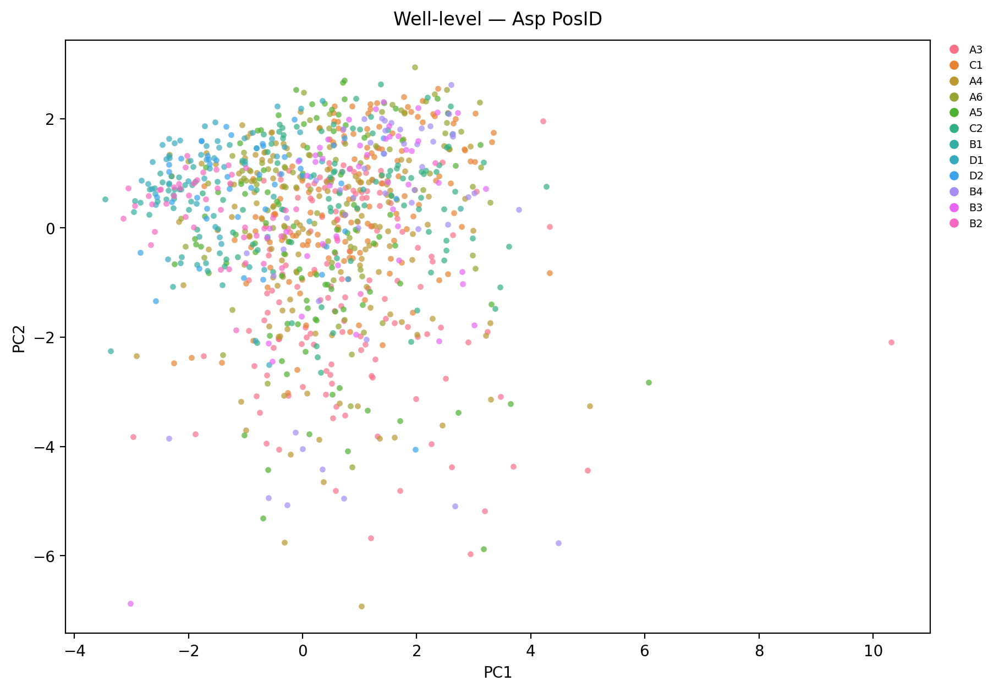

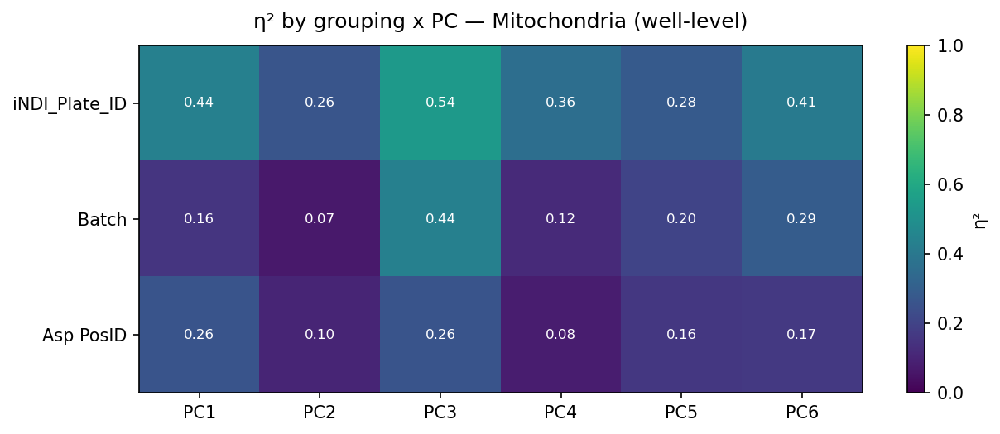

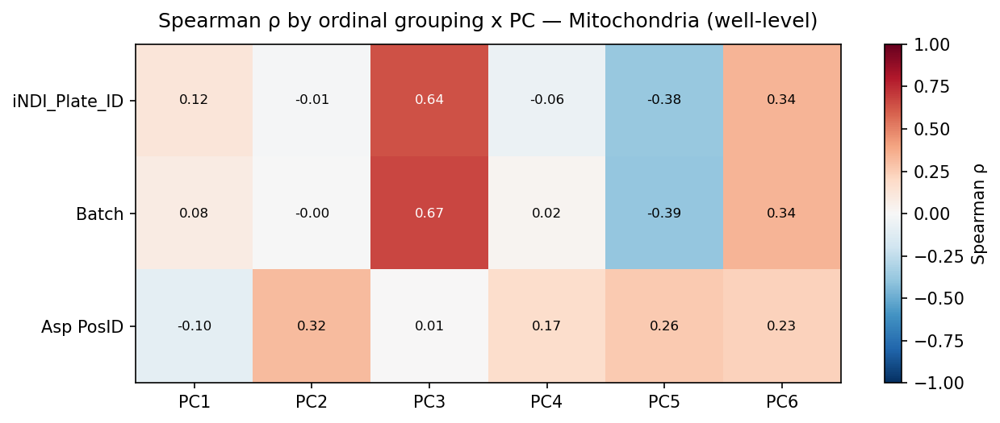

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.119489,-0.014866,0.639801,-0.056667,-0.378296,0.340651
Batch,0.084466,-0.000208,0.669437,0.024191,-0.385822,0.335994
Asp PosID,-0.099018,0.318544,0.007107,0.172578,0.260893,0.229632


In [25]:
well_level = aggregate_wells(parental, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — Mitochondria (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Mitochondria (well-level)")

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 36984 rows (12893 images)
[full] well-level: 1142 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 1142 remain
[full well] EVR: [0.266 0.241 0.209 0.142 0.075 0.046 0.011 0.006 0.003 0.001 0.   ]
[full well] cumulative: [0.266 0.508 0.716 0.858 0.933 0.979 0.99  0.996 0.999 1.    1.   ]


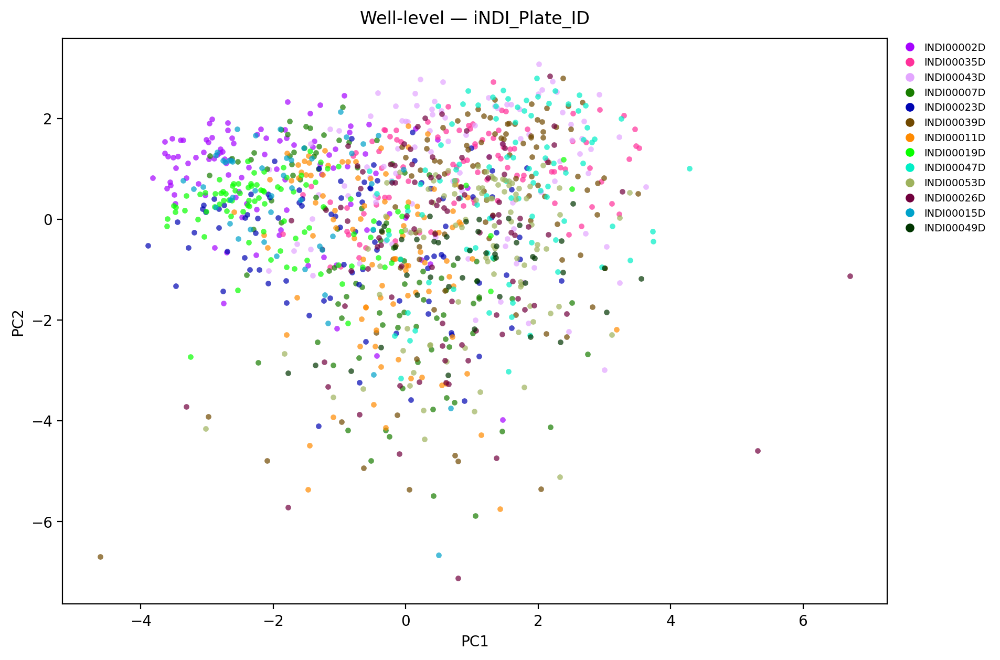

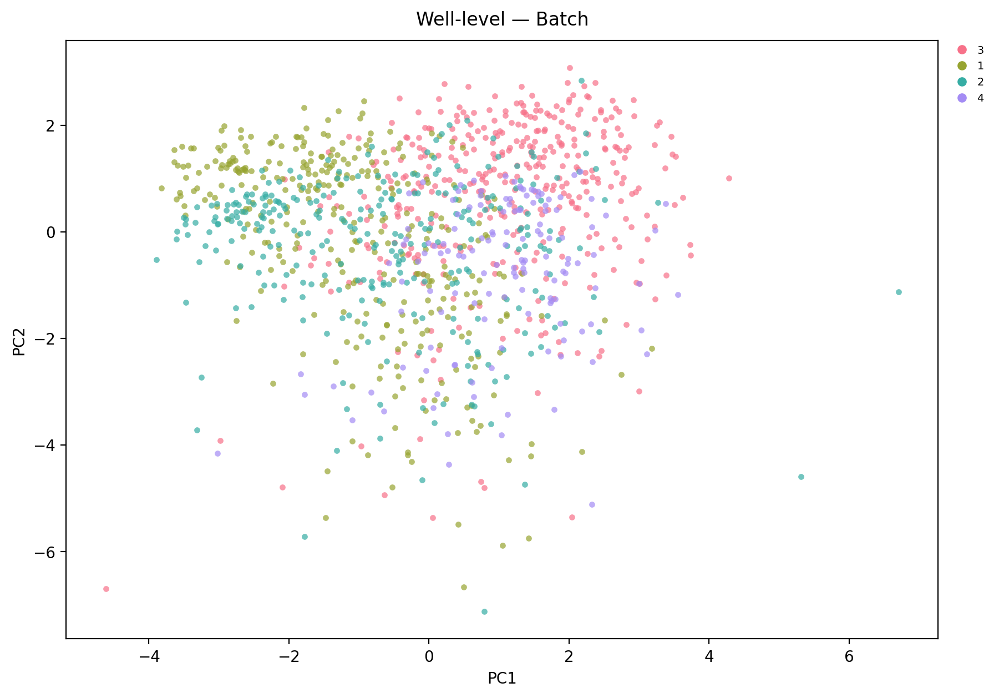

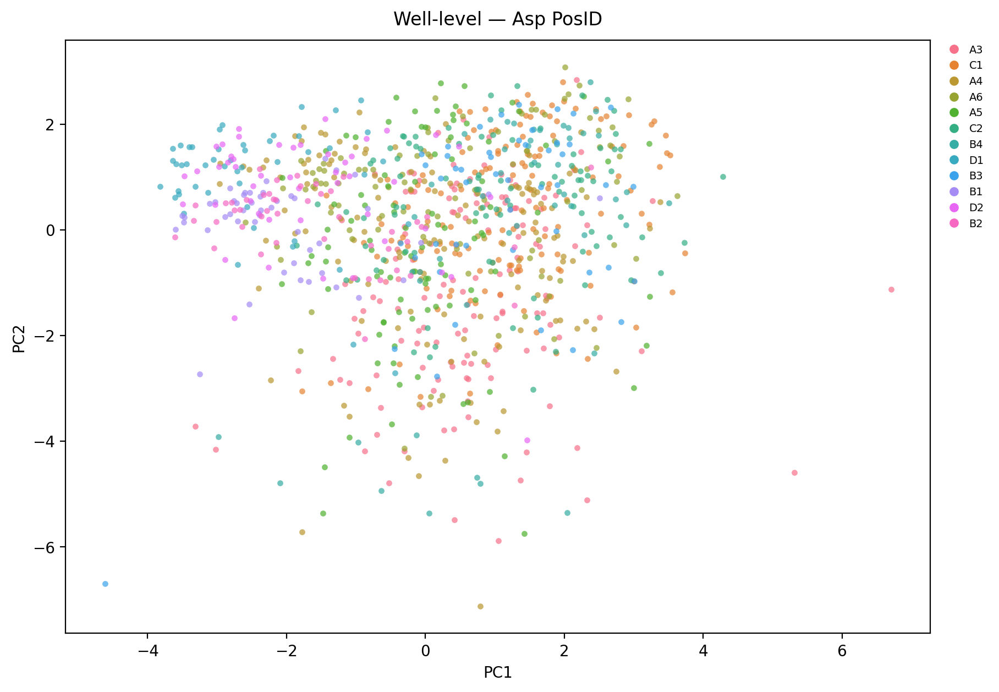

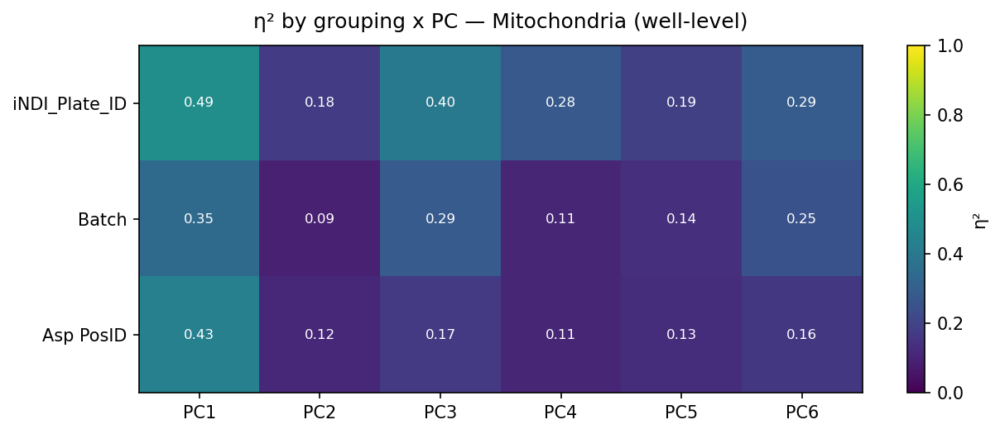

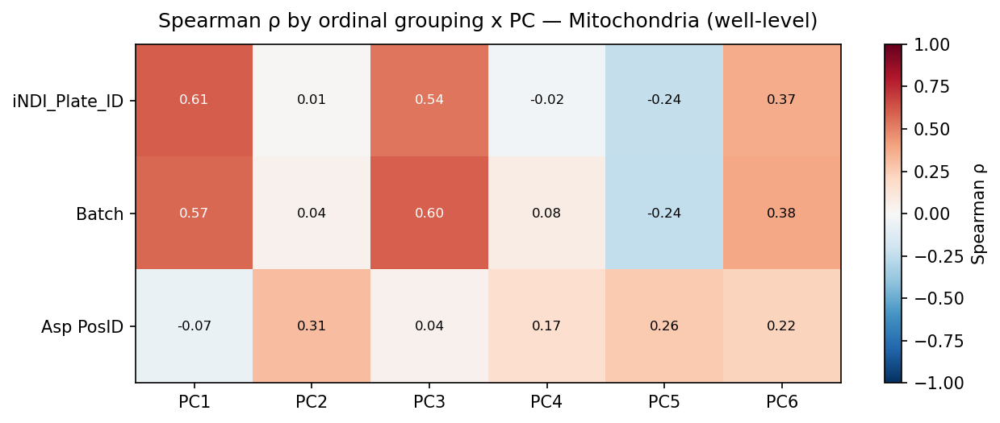

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.607205,0.013567,0.535997,-0.024881,-0.239496,0.368558
Batch,0.573210,0.043128,0.600226,0.075773,-0.243345,0.384502
Asp PosID,-0.066507,0.308980,0.039075,0.166670,0.260000,0.218905


In [26]:
well_level = aggregate_wells(parental_auto, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — Mitochondria (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Mitochondria (well-level)")

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 10182 rows (3747 images)
[full] well-level: 306 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 306 remain
[full well] EVR: [0.323 0.232 0.184 0.155 0.053 0.026 0.016 0.009 0.002 0.001 0.   ]
[full well] cumulative: [0.323 0.555 0.739 0.894 0.947 0.973 0.989 0.997 0.999 1.    1.   ]


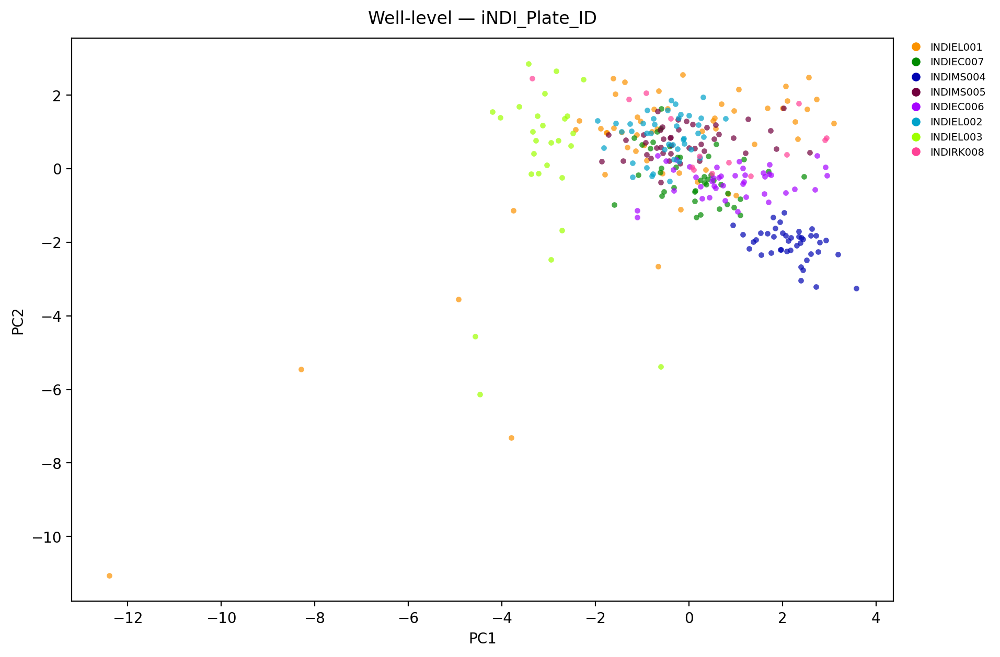

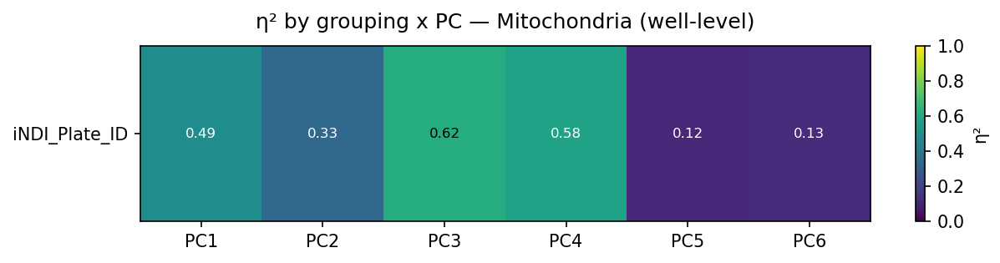

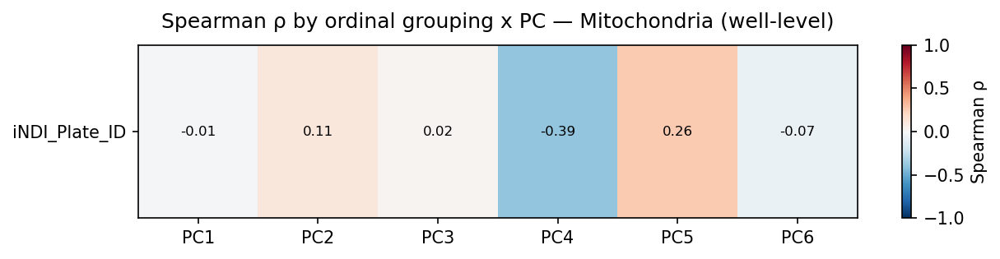

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.012955,0.111864,0.024266,-0.393814,0.259897,-0.066599


In [27]:
well_level = aggregate_wells(parental_manual, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID"],
            n_pcs=6, title="η² by grouping x PC — Mitochondria (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Mitochondria (well-level)")

In [28]:
build_pptx("/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_Mitochondria_analysis.pptx")

wrote 161 slides -> /data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_Mitochondria_analysis.pptx
